# Machine learning triage for glioma histological grading using a minimal mutation and age panel

**Scientific Reports — Revision 3 analysis notebook (single canonical run, N = 839)**

Authors: Singh S., Pal A., Mittal N., Kaur J., Gared F.
Data: UCI Machine Learning Repository ID 759 (*Glioma Grading Clinical and Mutation Features*, Tasci et al. 2022, doi:10.24432/C5R62J), derived from TCGA-LGG and TCGA-GBM.

### What changed relative to the Revision-2 notebook (audit of 12 Oct 2026)

| # | Revision-2 problem | Fix in this notebook |
|---|---|---|
| 1 | Final test-set model, SHAP, LOFO, reduced-panel and ensemble code were hard-coded to XGBoost although the locked primary model was Logistic Regression; the reported "LR" test result was an XGBoost model evaluated at LR's threshold | Every model-dependent step is built from `PRIMARY_MODEL_NAME` through one estimator factory; nothing is hard-coded to a family |
| 2 | The locked "class-weight (balanced)" imbalance strategy was never applied to any model | The factory applies the locked strategy to every family (`class_weight='balanced'`; XGBoost `scale_pos_weight` = training-partition LGG/GBM ratio) |
| 3 | LOFO and reduced-panel analyses used one fixed hyper-parameter set taken from the best outer fold (selected using outer-fold AUC) | Both are now **fully nested**: hyper-parameters re-tuned in the inner loop for every feature subset, so no outer-fold information is used |
| 4 | Extended LOFO compared a mean-of-fold AUC with pooled out-of-fold AUCs | One statistic (pooled OOF) on both sides, with a paired DeLong test per feature |
| 5 | Test-set "4-feature panel" was the permutation top-4, not the pre-specified nested panel | The panel carried to the test set is the nested majority-vote panel, locked before the test set is opened |
| 6 | Ensemble compared against XGBoost, built from best-fold hyper-parameters | Leakage-free nested soft-vote (mean of the four families' nested OOF probabilities) compared with the primary model |
| 7 | Duplicate audit text said "byte-identical incl. day-level age" | Raw-file audit: the two rows are distinct patients (35 y 65 d vs 35 y 66 d) that coincide after UCI's 2-decimal age rounding; both retained |
| 8 | WHO 2021 discordance audit ignored *IDH2* | Audit built here from the raw file with *IDH2*; IDH1-wild-type/IDH2-mutant tumours classed as IDH-mutant |
| 9 | Hard-coded labels ("LGG n=486", "1 duplicate removed"), clipped threshold figure, truncated confusion-matrix title | All labels computed; figures fixed |

### Design rules (fixed before any model is fitted)
1. **Single source of truth** — every number comes from one locked dataframe; the notebook writes a `ManuscriptNumbers` table that the manuscript is updated from.
2. **Development on the training partition only** — imbalance strategy, model family, calibration, threshold, feature importance, ablations and the reduced panel are all decided with cross-validation inside the 671-patient training partition.
3. **One primary model, chosen by a stated rule** — highest mean outer-fold AUC under nested CV, ties broken by mean outer-fold Brier score.
4. **Held-out test set opened once in this run.** *Disclosure:* test-set results from earlier versions of this analysis had been seen (the previously reviewed version used an 838-patient cohort and a different partition; an intermediate version used this partition with logistic regression as primary model). This is reported in the manuscript.
5. **All data-dependent preprocessing is fitted inside each fold.**

In [1]:
# SECTION 1 — IMPORTS, CONFIGURATION, REPRODUCIBILITY
import warnings; warnings.filterwarnings("ignore")
import os, sys, json, random, platform, hashlib, pickle, re
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

import numpy as np, pandas as pd, scipy
from scipy import stats
from scipy.stats import loguniform, randint, spearmanr
import matplotlib as mpl, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.contingency_tables import mcnemar

import sklearn
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     RandomizedSearchCV, cross_validate)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score, matthews_corrcoef, confusion_matrix,
                             roc_curve, brier_score_loss, make_scorer)
import xgboost
from xgboost import XGBClassifier
import imblearn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC, SMOTE, SMOTEN
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE); random.seed(RANDOM_STATE)
N_JOBS = int(os.environ.get("GLIOMA_N_JOBS", "-1"))
RUN_TAG = "r3"

PROJECT_DIR = Path(".").resolve()
DATA_DIR = PROJECT_DIR / "Data"
OUTPUT_DIR = PROJECT_DIR / "Results"
FIG_DIR, TABLE_DIR, MODEL_DIR = OUTPUT_DIR / "Figures", OUTPUT_DIR / "Tables", OUTPUT_DIR / "Models"
for d in (FIG_DIR, TABLE_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)
DATA_PATH = DATA_DIR / "TCGA_InfoWithGrade.csv"
RAW_DATA_PATH = DATA_DIR / "TCGA_GBM_LGG_Mutations_all.csv"

sns.set_theme(style="whitegrid", context="talk")
mpl.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 12})

# Every number the manuscript cites is registered here with its source table.
MANUSCRIPT_NUMBERS = []
def record(key, value, source, note=""):
    MANUSCRIPT_NUMBERS.append({"Key": key, "Value": value, "Source": source, "Note": note})
    return value

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / name, dpi=300, bbox_inches="tight"); plt.show(); plt.close()

print("Python", platform.python_version(), "| sklearn", sklearn.__version__, "| xgboost", xgboost.__version__,
      "| shap", shap.__version__, "| imblearn", imblearn.__version__, "| N_JOBS", N_JOBS)

Python 3.13.16 | sklearn 1.9.1 | xgboost 3.4.1 | shap 0.53.0 | imblearn 0.14.2 | N_JOBS -1


## Section 2 — Load data and lock the analysis dataframe
The analysis file (839 × 24) is the UCI release. The raw TCGA export (862 patients, with `Case_ID`, `Project`, `Primary_Diagnosis`) is used only for provenance and the WHO 2021 discordance audit, never for modelling.

In [2]:
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
df = pd.read_csv(DATA_PATH)
assert df.shape == (839, 24) and df.isnull().sum().sum() == 0

TARGET = "Grade"
CLINICAL_NUMERIC = ["Age_at_diagnosis"]
CLINICAL_CATEGORICAL = ["Gender", "Race"]
GENE_FEATURES = [c for c in df.columns if c not in [TARGET] + CLINICAL_NUMERIC + CLINICAL_CATEGORICAL]
ALL_FEATURES = CLINICAL_NUMERIC + CLINICAL_CATEGORICAL + GENE_FEATURES
assert len(GENE_FEATURES) == 20 and len(ALL_FEATURES) == 23
N_BINARY_OR_CATEGORICAL = len(CLINICAL_CATEGORICAL) + len(GENE_FEATURES)

DF_HASH = hashlib.sha256(pd.util.hash_pandas_object(df, index=True).values.tobytes()).hexdigest()
N_ANALYSIS, N_LGG, N_GBM = len(df), int((df.Grade == 0).sum()), int((df.Grade == 1).sum())
raw = pd.read_csv(RAW_DATA_PATH, encoding="utf-8-sig")
raw.columns = [c.strip() for c in raw.columns]

print(f"Analysis file SHA-256: {DATA_SHA256}\nContent hash: {DF_HASH}")
print(f"N = {N_ANALYSIS}  (LGG {N_LGG}, GBM {N_GBM});  features: 1 continuous + {N_BINARY_OR_CATEGORICAL} binary/categorical")
record("N_analysis", N_ANALYSIS, "Section 2"); record("N_LGG", N_LGG, "Section 2"); record("N_GBM", N_GBM, "Section 2")
record("N_binary_or_categorical_features", N_BINARY_OR_CATEGORICAL, "Section 2", "Gender, Race + 20 mutation genes; Age is the only continuous feature")

Analysis file SHA-256: 1b25614ff94c8cf95f80f2c91c33e69843044c62283332690c9ff88f195144a1
Content hash: 46b4f020c56397732d6f80c2e94a2ff4412500dcf140e4d99065cf5d9bdf2bf3
N = 839  (LGG 487, GBM 352);  features: 1 continuous + 22 binary/categorical


22

## Section 3 — Data audit: coding, exclusions, row-level provenance, and the duplicate-row question

In [3]:
# 3.1 Data dictionary
dd = [{"Variable": "Grade", "Role": "Target", "Type": "Binary", "Coding": "0 = LGG; 1 = GBM (legacy TCGA project label)"},
      {"Variable": "Gender", "Role": "Clinical", "Type": "Binary", "Coding": "0 = male; 1 = female"},
      {"Variable": "Age_at_diagnosis", "Role": "Clinical", "Type": "Continuous (years)", "Coding": "years + days/365, rounded to 2 decimals by UCI"},
      {"Variable": "Race", "Role": "Clinical", "Type": "Nominal (4 levels)", "Coding": "0 white; 1 black or African American; 2 Asian; 3 American Indian or Alaska Native (one-hot encoded)"}]
dd += [{"Variable": g, "Role": "Molecular", "Type": "Binary", "Coding": "0 = not mutated; 1 = mutated (somatic mutation call)"} for g in GENE_FEATURES]
pd.DataFrame(dd).to_csv(TABLE_DIR / "Table01_DataDictionary.csv", index=False)

# 3.2 Exclusions: raw 862 -> 839
def is_missing(s): return s.astype(str).str.strip().isin(["--", "not reported", "nan", "NaN"]) | s.isna()
miss = {c: is_missing(raw[c]) for c in ["Gender", "Age_at_diagnosis", "Race"]}
excluded = miss["Gender"] | miss["Age_at_diagnosis"] | miss["Race"]
excl = pd.DataFrame([{"Field": c, "Missing_or_not_reported": int(m.sum())} for c, m in miss.items()] +
                    [{"Field": "Excluded (union)", "Missing_or_not_reported": int(excluded.sum())},
                     {"Field": "Raw file patients", "Missing_or_not_reported": len(raw)},
                     {"Field": "Analysis patients", "Missing_or_not_reported": N_ANALYSIS}])
excl.to_csv(TABLE_DIR / "Table02_ExclusionAudit.csv", index=False)
print(excl.to_string(index=False))
assert len(raw) - int(excluded.sum()) == N_ANALYSIS

# 3.3 Row-level provenance: map every analysis row to its TCGA Case_ID and verify all 24 fields
kept = raw.loc[~excluded].reset_index(drop=True)
def age_years(s):
    y = re.search(r"(\d+)\s*years", s); d = re.search(r"(\d+)\s*days", s)
    return int(y.group(1)) + (int(d.group(1)) if d else 0) / 365
kept_age = kept["Age_at_diagnosis"].map(age_years)
checks = {
    "Grade": ((kept.Grade.str.strip() == "GBM").astype(int).values == df.Grade.values).all(),
    "Gender": ((kept.Gender.str.strip() == "Female").astype(int).values == df.Gender.values).all(),
    "Age": (np.abs(kept_age.round(2).values - df.Age_at_diagnosis.values) < 0.006).all(),
    "Genes": all(((kept[g].str.strip() == "MUTATED").astype(int).values == df[g].values).all() for g in GENE_FEATURES),
}
print("Row-level provenance checks:", checks)
assert all(checks.values()), "Analysis rows do not map 1:1 onto the raw file in order"
prov = df.copy()
prov["Case_ID"], prov["Project"], prov["Primary_Diagnosis"] = kept.Case_ID.values, kept.Project.values, kept.Primary_Diagnosis.values
prov["Age_raw"] = kept.Age_at_diagnosis.values

# 3.4 Identical feature rows: same patient or two patients?
dup_mask = df.duplicated(keep=False)
dups = prov.loc[dup_mask, ["Case_ID", "Project", "Primary_Diagnosis", "Age_raw", "Age_at_diagnosis", "Grade"]]
print("\nRows identical on all 24 analysis fields:\n", dups.to_string())
DUPLICATE_NOTE = (f"{int(dup_mask.sum())} analysis rows are identical on all 24 fields but map to distinct TCGA patients "
                  f"({', '.join(dups.Case_ID)}; raw ages {', '.join(dups.Age_raw)}; diagnoses "
                  f"{' / '.join(dups.Primary_Diagnosis)}). The coincidence arises from UCI's 2-decimal age rounding. "
                  "Both patients are retained.")
assert dups.Case_ID.nunique() == len(dups)
print("\n" + DUPLICATE_NOTE)

# 3.5 Class balance and race levels
assert sorted(df.Race.unique()) == [0, 1, 2, 3]
print(f"\nClass ratio LGG:GBM = {N_LGG/N_GBM:.2f}:1;  race counts {df.Race.value_counts().sort_index().to_dict()}")

            Field  Missing_or_not_reported
           Gender                        4
 Age_at_diagnosis                        5
             Race                       22
 Excluded (union)                       23
Raw file patients                      862
Analysis patients                      839
Row-level provenance checks: {'Grade': np.True_, 'Gender': np.True_, 'Age': np.True_, 'Genes': True}

Rows identical on all 24 analysis fields:
           Case_ID   Project        Primary_Diagnosis           Age_raw  Age_at_diagnosis  Grade
409  TCGA-P5-A72W  TCGA-LGG  Astrocytoma, anaplastic  35 years 65 days             35.18      0
424  TCGA-E1-A7Z4  TCGA-LGG         Astrocytoma, NOS  35 years 66 days             35.18      0

2 analysis rows are identical on all 24 fields but map to distinct TCGA patients (TCGA-P5-A72W, TCGA-E1-A7Z4; raw ages 35 years 65 days, 35 years 66 days; diagnoses Astrocytoma, anaplastic / Astrocytoma, NOS). The coincidence arises from UCI's 2-decimal age roundin

## Section 3b — Legacy label versus WHO 2021: audit of IDH-discordant cases
The target is the legacy TCGA LGG/GBM project label. Under WHO 2021, *IDH* status (IDH1 **or** IDH2) separates IDH-mutant gliomas from glioblastoma, IDH-wild-type. The UCI analysis file lacks 1p/19q co-deletion, *CDKN2A/B*, *TERT* promoter status, *EGFR* amplification and +7/−10 copy-number data, so this audit only describes how far the legacy label departs from IDH status. Those markers are added from published TCGA annotations in Section 20f (post hoc reconstruction), and the audit file points there rather than describing them as unmeasured.

In [4]:
idh_mut = (prov.IDH1 == 1) | (prov.IDH2 == 1)
def who_category(r):
    if r.Grade == 1 and r.IDH1 == 1:
        return "Legacy GBM, IDH1-mutant: IDH-mutant tumour (WHO 2021: astrocytoma, IDH-mutant, grade 4 if astrocytic)"
    if r.Grade == 0 and r.IDH1 == 0 and r.IDH2 == 1:
        return "Legacy LGG, IDH1-wild-type but IDH2-mutant: IDH-mutant tumour (not a glioblastoma candidate)"
    if r.Grade == 0 and r.IDH1 == 0 and r.IDH2 == 0:
        return "Legacy LGG, IDH1/2-wild-type: candidate glioblastoma, IDH-wild-type if TERT/EGFR-amp/+7-10 present (not in the UCI file; assessed from external annotations in Section 20f)"
    if r.Grade == 1 and r.IDH1 == 0 and r.IDH2 == 1:
        return "Legacy GBM, IDH2-mutant"
    return None
prov["WHO2021_audit_category"] = prov.apply(who_category, axis=1)
prov["IDH1_discordant"] = ((prov.Grade == 1) & (prov.IDH1 == 1)) | ((prov.Grade == 0) & (prov.IDH1 == 0))

audit = prov.loc[prov.WHO2021_audit_category.notna(),
                 ["Case_ID", "Project", "Grade", "Primary_Diagnosis", "Age_raw", "IDH1", "IDH2", "TP53", "ATRX",
                  "EGFR", "PTEN", "CIC", "FUBP1", "WHO2021_audit_category"]]
audit.to_csv(DATA_DIR / "Discordant_Cases_Audit_WHO2021.csv", index=False)
summary = audit.groupby("WHO2021_audit_category").agg(
    n=("Case_ID", "size"), TP53=("TP53", "sum"), ATRX=("ATRX", "sum"), EGFR=("EGFR", "sum"), PTEN=("PTEN", "sum"),
    CIC=("CIC", "sum"), FUBP1=("FUBP1", "sum")).reset_index()
summary.to_csv(TABLE_DIR / "Table28_WHO2021_DiscordanceSummary.csv", index=False)
by_dx = pd.crosstab(audit.Primary_Diagnosis, audit.WHO2021_audit_category)
by_dx.to_csv(TABLE_DIR / "Table29_WHO2021_DiscordanceByDiagnosis.csv")
print(summary.to_string(index=False)); print(); print(by_dx.to_string())

# Reconcile with the raw file (Reviewer 4 counted 108 IDH1-wild-type legacy LGG in the 862-patient file)
raw_idh1wt_lgg = int(((raw.Grade.str.strip() == "LGG") & (raw.IDH1.str.strip() == "NOT_MUTATED")).sum())
raw_idh1mut_gbm = int(((raw.Grade.str.strip() == "GBM") & (raw.IDH1.str.strip() == "MUTATED")).sum())
coh_idh1wt_lgg = int(((prov.Grade == 0) & (prov.IDH1 == 0)).sum())
coh_idh1mut_gbm = int(((prov.Grade == 1) & (prov.IDH1 == 1)).sum())
n_idh2_rescue = int(((prov.Grade == 0) & (prov.IDH1 == 0) & (prov.IDH2 == 1)).sum())
print(f"\nRaw file: {raw_idh1wt_lgg} IDH1-wt LGG, {raw_idh1mut_gbm} IDH1-mut GBM.  Cohort: {coh_idh1wt_lgg} and {coh_idh1mut_gbm} "
      f"({raw_idh1wt_lgg - coh_idh1wt_lgg} IDH1-wt LGG excluded for missing demographics).")
print(f"Of the {coh_idh1wt_lgg} IDH1-wt legacy LGG, {n_idh2_rescue} carry an IDH2 mutation (IDH-mutant) and "
      f"{coh_idh1wt_lgg - n_idh2_rescue} are IDH1/2-wild-type.")
for k, v in {"raw_IDH1wt_LGG": raw_idh1wt_lgg, "raw_IDH1mut_GBM": raw_idh1mut_gbm, "cohort_IDH1wt_LGG": coh_idh1wt_lgg,
             "cohort_IDH1mut_GBM": coh_idh1mut_gbm, "cohort_IDH1wt_IDH2mut_LGG": n_idh2_rescue,
             "cohort_IDH12wt_LGG": coh_idh1wt_lgg - n_idh2_rescue,
             "cohort_IDH12_status_discordant_total": int((((prov.Grade == 1) & idh_mut) | ((prov.Grade == 0) & ~idh_mut)).sum()),
             "cohort_IDH2mut_legacy_GBM": int(((prov.Grade == 1) & (prov.IDH1 == 0) & (prov.IDH2 == 1)).sum())}.items():
    record(k, v, "Table28")

                                                                                                                                                     WHO2021_audit_category  n  TP53  ATRX  EGFR  PTEN  CIC  FUBP1
                                                                      Legacy GBM, IDH1-mutant: IDH-mutant tumour (WHO 2021: astrocytoma, IDH-mutant, grade 4 if astrocytic) 23    22    18     2     1    1      0
                                                                                                                                                    Legacy GBM, IDH2-mutant  2     2     2     1     1    1      1
                                                                               Legacy LGG, IDH1-wild-type but IDH2-mutant: IDH-mutant tumour (not a glioblastoma candidate) 21     3     3     0     0    8      1
Legacy LGG, IDH1/2-wild-type: candidate glioblastoma, IDH-wild-type if TERT/EGFR-amp/+7-10 present (not in the UCI file; assessed from external annotations 

## Section 4 — Exploratory data analysis (whole cohort, descriptive only)

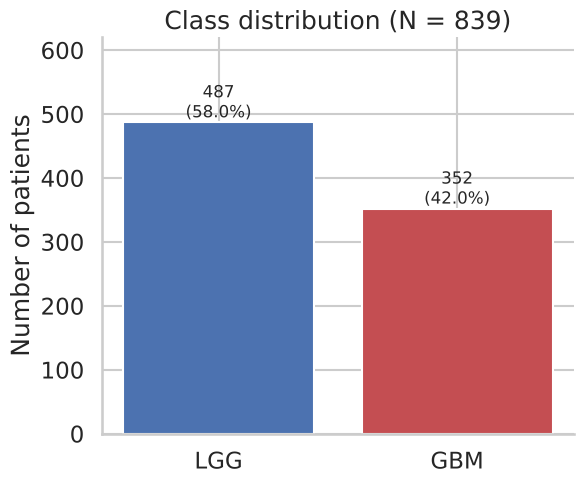

Age LGG 43.9±13.3 (IQR 34-54); GBM 60.7±13.4 (IQR 53-70); Shapiro p=5.2e-07,2.9e-04; Mann-Whitney U=32495.5, p=2.93e-53; Cohen d=1.26


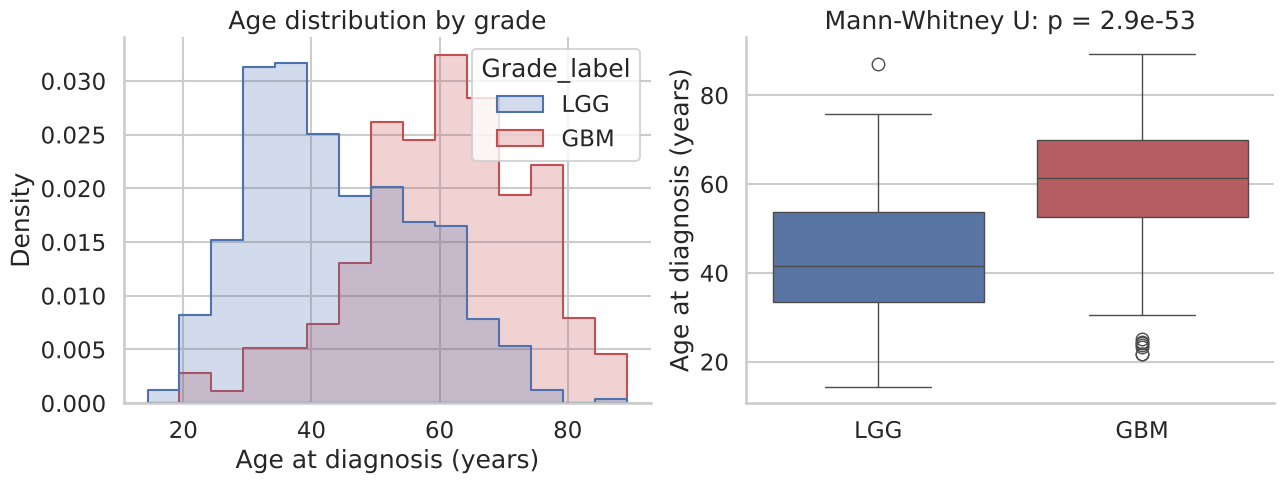

   Gene  LGG_percent  GBM_percent  Difference_pp  Chi2      p_value       Test  Min_expected_count
   IDH1         78.2          6.5          -71.7 417.9 7.129739e-93 chi-square               169.5
   ATRX         37.6          9.7          -27.9  81.6 1.664249e-19 chi-square                91.0
   PTEN          5.1         33.0           27.8 111.1 5.540342e-26 chi-square                59.2
    CIC         22.0          1.1          -20.8  75.5 3.734608e-18 chi-square                46.6
   EGFR          6.4         23.0           16.6  47.5 5.458835e-12 chi-square                47.0
   TP53         48.3         32.1          -16.2  21.3 3.926878e-06 chi-square               146.0
    RB1          1.2          9.7            8.4  30.1 4.042773e-08 chi-square                16.8
  FUBP1          8.8          0.6           -8.3  25.9 3.652869e-07 chi-square                18.9
  MUC16          8.4         16.2            7.8  11.2 8.054110e-04 chi-square                41.1
 NOTCH1   

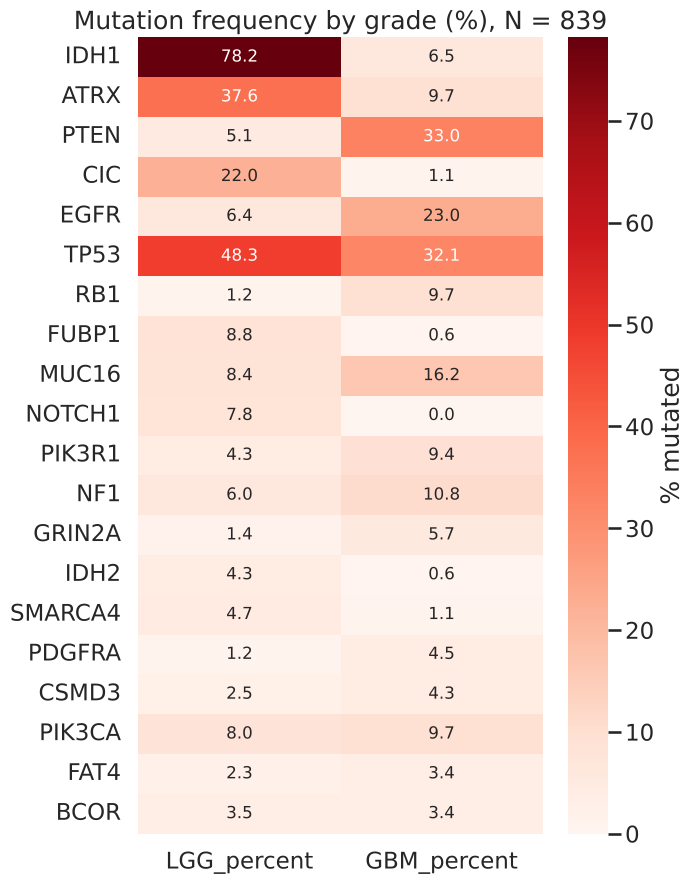


Gender: chi2=2.78, p=0.095;  Race (Monte Carlo, 20,000 permutations): p=0.0009
                               Characteristic      LGG (n=487)      GBM (n=352)  p_value                                         Test
           Age at diagnosis, years, mean (SD)      43.9 (13.3)      60.7 (13.4) 2.93e-53                               Mann-Whitney U
        Age at diagnosis, years, median (IQR) 41.6 (33.5-53.7) 61.4 (52.7-70.0)                                                      
                                  Male, n (%)      271 (55.6%)      217 (61.6%)    0.095                                   chi-square
                           Race: White, n (%)      457 (93.8%)      308 (87.5%)   0.0009 Monte Carlo chi-square (20,000 permutations)
       Race: Black or African American, n (%)        21 (4.3%)       38 (10.8%)                                                      
                           Race: Asian, n (%)         8 (1.6%)         6 (1.7%)                                     

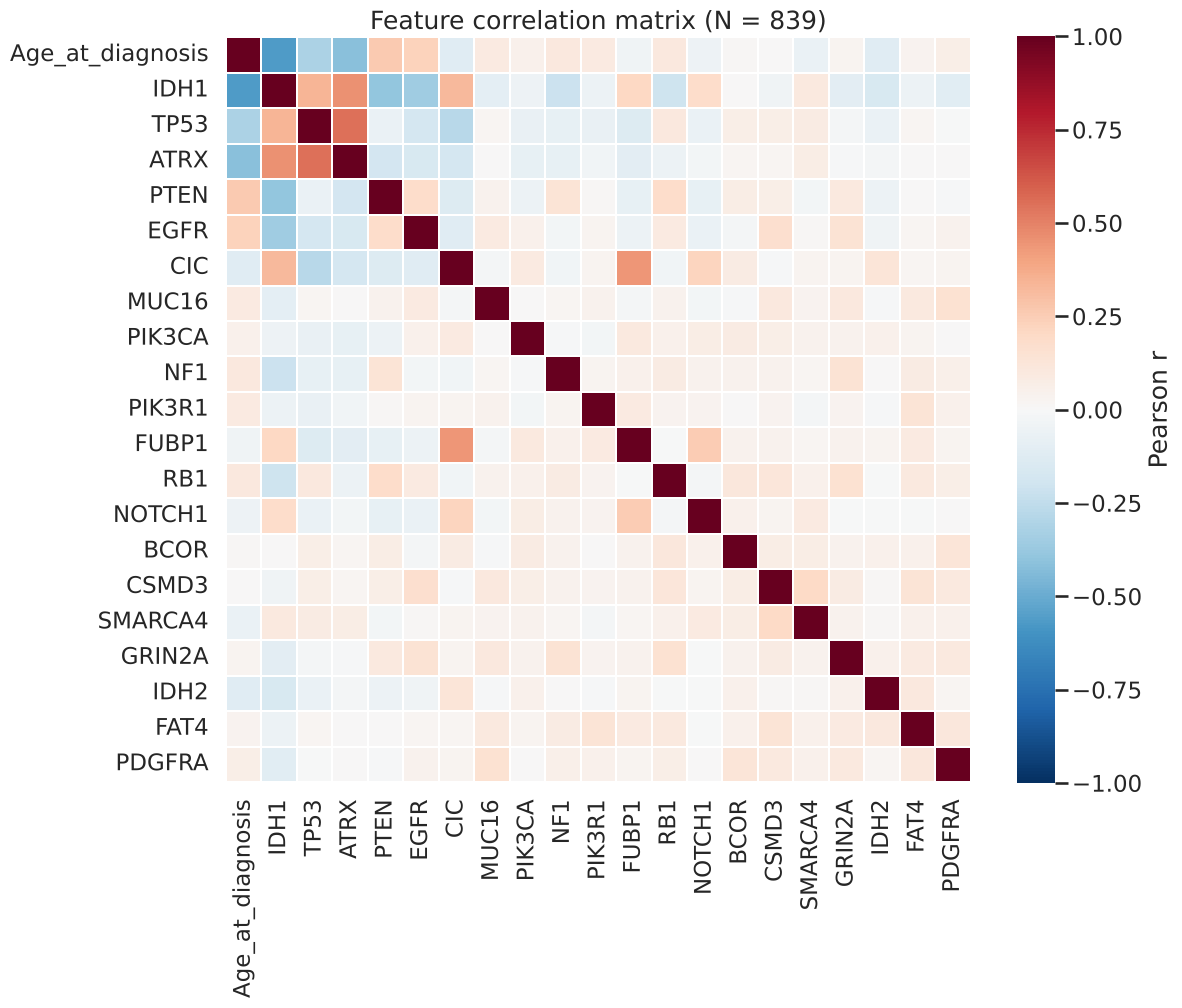

Feature_A Feature_B  Pearson_r      p_value
     IDH1      ATRX      0.455 4.339478e-44
     ATRX      TP53      0.547 1.281227e-66
     IDH1      TP53      0.341 2.735320e-24
      CIC     FUBP1      0.438 1.256076e-40
     IDH1      EGFR     -0.357 1.182472e-26


In [5]:
from scipy.stats import shapiro, mannwhitneyu, ttest_ind, chi2_contingency, fisher_exact
lab = df.assign(Grade_label=df.Grade.map({0: "LGG", 1: "GBM"}))
PAL = ["#4C72B0", "#C44E52"]

# 4.1 Class distribution
cnt = df.Grade.value_counts().sort_index(); pct = (cnt / len(df) * 100).round(1)
pd.DataFrame({"Grade": ["LGG", "GBM"], "N": cnt.values, "Percent": pct.values}).to_csv(TABLE_DIR / "Table_TargetDistribution.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(["LGG", "GBM"], cnt.values, color=PAL)
for i, v in enumerate(cnt.values): ax.text(i, v + 8, f"{v}\n({pct.values[i]}%)", ha="center", fontsize=12)
ax.set_ylabel("Number of patients"); ax.set_title(f"Class distribution (N = {N_ANALYSIS})"); ax.set_ylim(0, 620)
savefig("Figure01_ClassDistribution.png")

# 4.2 Age
age_lgg, age_gbm = df.loc[df.Grade == 0, "Age_at_diagnosis"], df.loc[df.Grade == 1, "Age_at_diagnosis"]
sh = (shapiro(age_lgg).pvalue, shapiro(age_gbm).pvalue)
U_stat, p_age = mannwhitneyu(age_lgg, age_gbm, alternative="two-sided")
pooled_sd = np.sqrt(((len(age_lgg)-1)*age_lgg.var() + (len(age_gbm)-1)*age_gbm.var()) / (len(df)-2))
cohen_d = (age_gbm.mean() - age_lgg.mean()) / pooled_sd
print(f"Age LGG {age_lgg.mean():.1f}±{age_lgg.std():.1f} (IQR {age_lgg.quantile(.25):.0f}-{age_lgg.quantile(.75):.0f}); "
      f"GBM {age_gbm.mean():.1f}±{age_gbm.std():.1f} (IQR {age_gbm.quantile(.25):.0f}-{age_gbm.quantile(.75):.0f}); "
      f"Shapiro p={sh[0]:.1e},{sh[1]:.1e}; Mann-Whitney U={U_stat:.1f}, p={p_age:.2e}; Cohen d={cohen_d:.2f}")
record("Age_mean_LGG", round(age_lgg.mean(), 1), "Section 4"); record("Age_mean_GBM", round(age_gbm.mean(), 1), "Section 4")
record("Age_MWU_U", round(U_stat, 1), "Section 4"); record("Age_cohen_d", round(cohen_d, 2), "Section 4")
record("Age_median_diff", round(age_gbm.median() - age_lgg.median(), 1), "Section 4")
record("Age_mean_diff", round(age_gbm.mean() - age_lgg.mean(), 1), "Section 4")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(data=lab, x="Age_at_diagnosis", hue="Grade_label", hue_order=["LGG", "GBM"], element="step",
             stat="density", common_norm=False, palette=PAL, ax=axes[0])
axes[0].set_xlabel("Age at diagnosis (years)"); axes[0].set_title("Age distribution by grade")
sns.boxplot(data=lab, x="Grade_label", y="Age_at_diagnosis", order=["LGG", "GBM"], palette=PAL, ax=axes[1])
axes[1].set_xlabel(""); axes[1].set_ylabel("Age at diagnosis (years)"); axes[1].set_title(f"Mann-Whitney U: p = {p_age:.1e}")
savefig("Figure03_AgeDistribution.png")

# 4.3 Mutation rates by grade (one dataframe drives table and heatmap)
rows = []
for g in GENE_FEATURES:
    ct = pd.crosstab(df[g], df.Grade)
    exp_min = (ct.sum(1).values[:, None] * ct.sum(0).values[None, :] / ct.values.sum()).min()
    if exp_min >= 5: chi2v, p, _, _ = chi2_contingency(ct); test = "chi-square"
    else: chi2v = np.nan; _, p = fisher_exact(ct); test = "Fisher exact"
    rows.append({"Gene": g, "LGG_percent": round(df.loc[df.Grade == 0, g].mean()*100, 1),
                 "GBM_percent": round(df.loc[df.Grade == 1, g].mean()*100, 1),
                 "Difference_pp": round((df.loc[df.Grade == 1, g].mean() - df.loc[df.Grade == 0, g].mean())*100, 1),
                 "Chi2": round(chi2v, 1) if not np.isnan(chi2v) else np.nan, "p_value": p, "Test": test,
                 "Min_expected_count": round(exp_min, 1)})
mut = pd.DataFrame(rows).sort_values("Difference_pp", key=abs, ascending=False).reset_index(drop=True)
mut.to_csv(TABLE_DIR / "Table03_MutationRatesByGrade.csv", index=False)
print(mut.to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 9))
sns.heatmap(mut.set_index("Gene")[["LGG_percent", "GBM_percent"]], annot=True, fmt=".1f", cmap="Reds",
            cbar_kws={"label": "% mutated"}, ax=ax)
ax.set_title(f"Mutation frequency by grade (%), N = {N_ANALYSIS}"); ax.set_ylabel("")
savefig("Figure02_MutationHeatmap.png")

# 4.4 Gender and race
gct = pd.crosstab(df.Gender, df.Grade); chi_g, p_g, _, _ = chi2_contingency(gct)
def mc_chi2(table, n_perm=20000, seed=RANDOM_STATE):
    rng_ = np.random.RandomState(seed); obs, _, _, expd = chi2_contingency(table)
    rows_, cols_ = np.repeat(np.arange(table.shape[0]), table.values.sum(1)), None
    labels = np.concatenate([np.repeat(np.arange(table.shape[1]), table.values[i]) for i in range(table.shape[0])])
    ge = 0
    for _ in range(n_perm):
        pc = np.zeros(table.shape); np.add.at(pc, (rows_, rng_.permutation(labels)), 1)
        ge += np.nansum((pc - expd) ** 2 / expd) >= obs - 1e-12
    return (ge + 1) / (n_perm + 1)
rct = pd.crosstab(df.Race, df.Grade); p_race = mc_chi2(rct)
print(f"\nGender: chi2={chi_g:.2f}, p={p_g:.3f};  Race (Monte Carlo, 20,000 permutations): p={p_race:.4f}")
record("Gender_chi2", round(chi_g, 2), "Section 4"); record("Gender_p", round(p_g, 3), "Section 4")
record("Race_MC_p", round(p_race, 4), "Section 4")
for lvl, n in df.Gender.value_counts().sort_index().items():
    record(f"Gender_{'male' if lvl == 0 else 'female'}_n", int(n), "Section 4", f"{n/len(df)*100:.1f}%")
for lvl, n in df.Race.value_counts().sort_index().items():
    record(f"Race_{lvl}_n", int(n), "Section 4", f"{n/len(df)*100:.1f}%")

# 4.5 Patient characteristics table (computed headers)
t1 = pd.DataFrame([
    {"Characteristic": "Age at diagnosis, years, mean (SD)", f"LGG (n={N_LGG})": f"{age_lgg.mean():.1f} ({age_lgg.std():.1f})",
     f"GBM (n={N_GBM})": f"{age_gbm.mean():.1f} ({age_gbm.std():.1f})", "p_value": f"{p_age:.2e}", "Test": "Mann-Whitney U"},
    {"Characteristic": "Male, n (%)", f"LGG (n={N_LGG})": f"{gct.loc[0,0]} ({gct.loc[0,0]/N_LGG*100:.1f}%)",
     f"GBM (n={N_GBM})": f"{gct.loc[0,1]} ({gct.loc[0,1]/N_GBM*100:.1f}%)", "p_value": f"{p_g:.3f}", "Test": "chi-square"},
])
rct = pd.crosstab(df.Race, df.Grade)
race_names = {0: "White", 1: "Black or African American", 2: "Asian", 3: "American Indian or Alaska Native"}
race_rows = [{"Characteristic": f"Race: {race_names[k]}, n (%)", f"LGG (n={N_LGG})": f"{rct.loc[k,0]} ({rct.loc[k,0]/N_LGG*100:.1f}%)",
              f"GBM (n={N_GBM})": f"{rct.loc[k,1]} ({rct.loc[k,1]/N_GBM*100:.1f}%)", "p_value": "", "Test": ""} for k in rct.index]
race_rows[0].update({"p_value": f"{p_race:.4f}", "Test": "Monte Carlo chi-square (20,000 permutations)"})
age_rows = [{"Characteristic": "Age at diagnosis, years, median (IQR)", f"LGG (n={N_LGG})": f"{age_lgg.median():.1f} ({age_lgg.quantile(.25):.1f}-{age_lgg.quantile(.75):.1f})",
             f"GBM (n={N_GBM})": f"{age_gbm.median():.1f} ({age_gbm.quantile(.25):.1f}-{age_gbm.quantile(.75):.1f})", "p_value": "", "Test": ""}]
t1 = pd.concat([t1.iloc[:1], pd.DataFrame(age_rows), t1.iloc[1:], pd.DataFrame(race_rows)], ignore_index=True)
for k in rct.index:
    record(f"Race_{k}_LGG_n", int(rct.loc[k, 0]), "Table_PatientCharacteristics"); record(f"Race_{k}_GBM_n", int(rct.loc[k, 1]), "Table_PatientCharacteristics")
t1.to_csv(TABLE_DIR / "Table_PatientCharacteristics.csv", index=False); print(t1.to_string(index=False))

# 4.6 Correlations
corr = df[["Age_at_diagnosis"] + GENE_FEATURES].corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=.3, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title(f"Feature correlation matrix (N = {N_ANALYSIS})"); savefig("Figure04_CorrelationMatrix.png")
pairs = [("IDH1", "ATRX"), ("ATRX", "TP53"), ("IDH1", "TP53"), ("CIC", "FUBP1"), ("IDH1", "EGFR")]
cm_rows = []
for a, b in pairs:
    r, p = stats.pearsonr(df[a], df[b]); cm_rows.append({"Feature_A": a, "Feature_B": b, "Pearson_r": round(r, 3), "p_value": p})
pd.DataFrame(cm_rows).to_csv(TABLE_DIR / "Table27_NamedCoMutationCorrelations.csv", index=False)
print(pd.DataFrame(cm_rows).to_string(index=False))

## Section 5 — Train/test split (sealed here), preprocessing, estimator factory

In [6]:
X_full, y_full = df[ALL_FEATURES].copy(), df[TARGET].copy()
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X_full, y_full, df.index, test_size=0.20, stratify=y_full, random_state=RANDOM_STATE)
pd.Series(idx_train, name="train_index").to_csv(TABLE_DIR / "split_train_indices.csv", index=False)
pd.Series(idx_test, name="test_index").to_csv(TABLE_DIR / "split_test_indices.csv", index=False)
Xtr, ytr = X_train.reset_index(drop=True), y_train.reset_index(drop=True)
y_arr = ytr.values
N_TRAIN, N_TEST = len(X_train), len(X_test)
TR_GBM, TR_LGG, TE_GBM, TE_LGG = int(y_train.sum()), int((y_train == 0).sum()), int(y_test.sum()), int((y_test == 0).sum())
SPW = TR_LGG / TR_GBM          # XGBoost scale_pos_weight if class weighting is locked (training partition only)
print(f"Train n={N_TRAIN} (LGG {TR_LGG}, GBM {TR_GBM});  Test n={N_TEST} (LGG {TE_LGG}, GBM {TE_GBM});  SPW={SPW:.3f}")
for k, v in {"N_train": N_TRAIN, "N_test": N_TEST, "Train_GBM": TR_GBM, "Train_LGG": TR_LGG, "Test_GBM": TE_GBM, "Test_LGG": TE_LGG}.items():
    record(k, v, "Section 5")

def build_preprocessor(features):
    t = []
    if "Age_at_diagnosis" in features: t.append(("age", StandardScaler(), ["Age_at_diagnosis"]))
    if "Gender" in features: t.append(("gender", "passthrough", ["Gender"]))
    if "Race" in features:   # categories pinned: one level has a single patient and can vanish from a fold
        t.append(("race", OneHotEncoder(categories=[[0, 1, 2, 3]], drop="first", handle_unknown="ignore"), ["Race"]))
    rest = [f for f in features if f not in ("Age_at_diagnosis", "Gender", "Race")]
    if rest: t.append(("genes", "passthrough", rest))
    return ColumnTransformer(t, remainder="drop", verbose_feature_names_out=False)

FAMILIES = ["LogisticRegression", "SVM_RBF", "RandomForest", "XGBoost"]
TREE_FAMILIES = {"RandomForest", "XGBoost"}
SEARCH_SPACES = {
    "LogisticRegression": ({"clf__C": loguniform(1e-3, 1e2)}, 25),
    "SVM_RBF": ({"clf__C": loguniform(1e-2, 1e2), "clf__gamma": loguniform(1e-4, 1e-1)}, 12),
    "RandomForest": ({"clf__n_estimators": randint(100, 500), "clf__max_depth": [None, 3, 5, 8, 12],
                      "clf__min_samples_leaf": randint(1, 8), "clf__max_features": ["sqrt", "log2", None]}, 25),
    "XGBoost": ({"clf__n_estimators": randint(100, 400), "clf__max_depth": randint(2, 6),
                 "clf__learning_rate": loguniform(0.01, 0.3), "clf__subsample": [0.6, 0.8, 1.0],
                 "clf__colsample_bytree": [0.6, 0.8, 1.0]}, 25),
}
IMBALANCE_STRATEGY = None   # locked in Section 6

def make_estimator(family, strategy=None):
    """The ONLY place estimators are created; applies the locked imbalance strategy to every family."""
    strategy = strategy or IMBALANCE_STRATEGY
    cw = "balanced" if strategy == "Class-weight (balanced)" else None
    if family == "LogisticRegression": return LogisticRegression(max_iter=5000, class_weight=cw, random_state=RANDOM_STATE)
    if family == "SVM_RBF": return SVC(kernel="rbf", probability=True, class_weight=cw, random_state=RANDOM_STATE)
    if family == "RandomForest": return RandomForestClassifier(class_weight=cw, random_state=RANDOM_STATE, n_jobs=1)
    if family == "XGBoost":
        return XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1,
                             scale_pos_weight=SPW if cw else 1.0)
    raise ValueError(family)

def make_pipeline(features, family, strategy=None):
    strategy = strategy or IMBALANCE_STRATEGY
    steps = [("preprocess", build_preprocessor(features)), ("clf", make_estimator(family, strategy))]
    if strategy == "SMOTENC":
        cat_idx = [i for i, f in enumerate(features) if f != "Age_at_diagnosis"]
        sampler = (SMOTEN(random_state=RANDOM_STATE) if len(cat_idx) == len(features)
                   else SMOTENC(categorical_features=cat_idx, random_state=RANDOM_STATE))
        return ImbPipeline([("resample", sampler)] + steps)
    return Pipeline(steps)

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
TEST_SET_OPENED = False

Train n=671 (LGG 389, GBM 282);  Test n=168 (LGG 98, GBM 70);  SPW=1.379


## Section 6 — Imbalance-handling comparison (training partition only)
Fixed classifier (random forest, 300 trees), 5×5 repeated stratified CV. Pre-specified rule: highest mean AUC among the three strategies that keep binary features binary (no correction, class weighting, SMOTENC). Standard SMOTE is a demonstration arm only.

In [7]:
cv_imb = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "balanced_accuracy": "balanced_accuracy", "mcc": make_scorer(matthews_corrcoef),
           "brier": make_scorer(brier_score_loss, response_method="predict_proba", greater_is_better=False)}
def rf(cw=None): return RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=RANDOM_STATE, n_jobs=1)
cat_idx_all = [i for i, f in enumerate(ALL_FEATURES) if f != "Age_at_diagnosis"]
arms = {
    "No resampling": Pipeline([("preprocess", build_preprocessor(ALL_FEATURES)), ("clf", rf())]),
    "Class-weight (balanced)": Pipeline([("preprocess", build_preprocessor(ALL_FEATURES)), ("clf", rf("balanced"))]),
    "SMOTENC": ImbPipeline([("resample", SMOTENC(categorical_features=cat_idx_all, random_state=RANDOM_STATE)),
                            ("preprocess", build_preprocessor(ALL_FEATURES)), ("clf", rf())]),
    "Standard SMOTE": ImbPipeline([("preprocess", build_preprocessor(ALL_FEATURES)),
                                   ("resample", SMOTE(random_state=RANDOM_STATE)), ("clf", rf())]),
}
rows = []
for name, pipe in arms.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv_imb, scoring=scoring, n_jobs=N_JOBS)
    row = {"Strategy": name}
    for m in scoring:
        v = -res[f"test_{m}"] if m == "brier" else res[f"test_{m}"]
        row[f"{m}_mean"], row[f"{m}_sd"] = round(v.mean(), 4), round(v.std(), 4)
    row["roc_auc_mean_full_precision"] = res["test_roc_auc"].mean(); row["brier_mean_full_precision"] = -res["test_brier"].mean()
    rows.append(row)
imb = pd.DataFrame(rows); imb.to_csv(TABLE_DIR / "Table04_ImbalanceStrategyComparison.csv", index=False)
print(imb.to_string(index=False))

eligible = imb[imb.Strategy != "Standard SMOTE"]
IMBALANCE_STRATEGY = eligible.sort_values(["roc_auc_mean_full_precision", "brier_mean_full_precision"],
                                         ascending=[False, True]).iloc[0].Strategy   # full precision; Brier breaks exact ties
spread = imb.roc_auc_mean.max() - imb.roc_auc_mean.min()
print(f"\nLOCKED IMBALANCE_STRATEGY = '{IMBALANCE_STRATEGY}'. Spread across all four arms: {spread:.4f} AUC "
      f"(mean SD {imb.roc_auc_sd.mean():.3f}).")

# Demonstrate standard SMOTE's non-binary synthetic mutation values
Xt = build_preprocessor(ALL_FEATURES).fit_transform(X_train)
Xs, _ = SMOTE(random_state=RANDOM_STATE).fit_resample(Xt, y_train)
synth = Xs[len(Xt):]; gene_cols = list(range(Xt.shape[1] - len(GENE_FEATURES), Xt.shape[1]))
frac_nonbinary_any = np.mean([(synth[:, j] % 1 != 0).mean() for j in gene_cols])
frac_first = (synth[:, gene_cols[0]] % 1 != 0).mean()
print(f"Standard SMOTE: {len(synth)} synthetic rows; non-binary values in {GENE_FEATURES[0]}: {frac_first*100:.1f}%, "
      f"mean over all 20 genes: {frac_nonbinary_any*100:.1f}%")
record("Imbalance_locked", IMBALANCE_STRATEGY, "Table04"); record("Imbalance_AUC_spread", round(spread, 4), "Table04")
record("SMOTE_nonbinary_pct_first_gene", round(frac_first*100, 1), "Section 6", GENE_FEATURES[0])
record("SMOTE_nonbinary_pct_mean_genes", round(frac_nonbinary_any*100, 1), "Section 6")

               Strategy  roc_auc_mean  roc_auc_sd  balanced_accuracy_mean  balanced_accuracy_sd  mcc_mean  mcc_sd  brier_mean  brier_sd  roc_auc_mean_full_precision  brier_mean_full_precision
          No resampling        0.9013      0.0189                  0.8553                0.0213    0.7069  0.0428      0.1159    0.0129                     0.901347                   0.115914
Class-weight (balanced)        0.9014      0.0178                  0.8547                0.0197    0.7039  0.0394      0.1159    0.0127                     0.901433                   0.115873
                SMOTENC        0.9014      0.0198                  0.8557                0.0189    0.7061  0.0377      0.1164    0.0135                     0.901394                   0.116352
         Standard SMOTE        0.9013      0.0196                  0.8563                0.0166    0.7075  0.0340      0.1157    0.0129                     0.901269                   0.115671

LOCKED IMBALANCE_STRATEGY = 'Class-weig

np.float64(3.4)

## Section 7 — Nested cross-validation helpers
One function serves every nested analysis (model families, baselines, LOFO, panels). For each outer fold an inner `RandomizedSearchCV` tunes hyper-parameters on that fold's training portion only.

In [8]:
def nested_cv(features, family, outer=outer_cv, X=Xtr, y=ytr, n_iter=None):
    params, default_iter = SEARCH_SPACES[family]
    n_iter = n_iter or default_iter
    oof = np.zeros(len(y)); recs = []
    for k, (tr, te) in enumerate(outer.split(X, y)):
        search = RandomizedSearchCV(make_pipeline(features, family), params, n_iter=n_iter, scoring="roc_auc",
                                    cv=inner_cv, random_state=RANDOM_STATE, n_jobs=N_JOBS, refit=True)
        search.fit(X.iloc[tr][features], y.iloc[tr])
        p = search.predict_proba(X.iloc[te][features])[:, 1]; oof[te] = p
        recs.append({"fold": k, "auc": roc_auc_score(y.iloc[te], p), "brier": brier_score_loss(y.iloc[te], p),
                     "best_params": search.best_params_})
    return oof, recs

# Cache with a code-version component (R1 W9 / R3 m3). The key combines: the data hash; a fingerprint of the
# compiled body of the cached function (bytecode + constants + referenced names, recursing into nested functions,
# so editing comments or unrelated cells does not invalidate it, but editing the function does); fingerprints of
# the shared modelling helpers it calls; a deterministic description of the search spaces; the locked imbalance
# strategy; library versions; and an optional caller-supplied context (e.g. upstream hyper-parameters).
import types, inspect
def _code_fp(co):
    h = hashlib.sha256(co.co_code)
    h.update(repr(co.co_names).encode()); h.update(repr(co.co_varnames).encode())
    for c in co.co_consts:
        h.update((_code_fp(c) if isinstance(c, types.CodeType) else repr(c)).encode())
    return h.hexdigest()
def _fp(obj):
    return _code_fp(obj.__code__) if hasattr(obj, "__code__") else hashlib.sha256(repr(obj).encode()).hexdigest()
def _space_desc(spaces):
    def d(v):
        if hasattr(v, "dist"): return f"{v.dist.name}{tuple(v.args)}{sorted(v.kwds.items())}"
        return repr(v)
    return repr({f: ({k: d(v) for k, v in sorted(p.items())}, n) for f, (p, n) in sorted(spaces.items())})
CACHE_MANIFEST = {}
def cache(name, fn, deps=(), ctx=None):
    core = [build_preprocessor, make_estimator, make_pipeline, nested_cv] + list(deps)
    key_src = "|".join([DF_HASH, RUN_TAG, _fp(fn)] + [_fp(d) for d in core] +
                       [_space_desc(SEARCH_SPACES), str(IMBALANCE_STRATEGY), f"{SPW:.12g}", str(RANDOM_STATE),
                        repr(ALL_FEATURES), sklearn.__version__, xgboost.__version__, platform.python_version(), repr(ctx)])
    code_key = hashlib.sha256(key_src.encode()).hexdigest()[:10]
    path = MODEL_DIR / f"{name}_{DF_HASH[:12]}_{RUN_TAG}_{code_key}.pkl"
    hit = path.exists()
    CACHE_MANIFEST[name] = {"file": path.name, "code_key": code_key, "hit": hit}
    print(f"[cache] {name}: {'HIT' if hit else 'MISS (computing)'} key={code_key}")
    if hit:
        with open(path, "rb") as f: return pickle.load(f)
    out = fn()
    with open(path, "wb") as f: pickle.dump(out, f)
    return out

# DeLong (DeLong et al. 1988; fast midrank form)
def _midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]: j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1; i = j
    T2 = np.empty(N); T2[J] = T; return T2
def _delong(y, s):
    o = np.argsort(-y, kind="stable"); y, s = y[o], s[o]; m = int(y.sum()); n = len(y) - m
    tx, ty, tz = _midrank(s[:m]), _midrank(s[m:]), _midrank(s)
    return tz[:m].sum() / m / n - (m + 1) / (2 * n), (tz[:m] - tx) / n, 1 - (tz[m:] - ty) / m, m, n
def delong(y, a, b):
    y = np.asarray(y); A = _delong(y, np.asarray(a)); B = _delong(y, np.asarray(b)); m, n = A[3], A[4]
    S = np.cov(np.vstack([A[1], B[1]])) / m + np.cov(np.vstack([A[2], B[2]])) / n
    se = np.sqrt(max(S[0, 0] + S[1, 1] - 2 * S[0, 1], 0)); d = A[0] - B[0]
    z = 0 if se == 0 else d / se
    return {"auc_A": A[0], "auc_B": B[0], "diff": d, "se": se, "ci_lo": d - 1.96 * se, "ci_hi": d + 1.96 * se,
            "p": 2 * (1 - stats.norm.cdf(abs(z)))}

def ece(y, p, bins=10):
    edges = np.linspace(0, 1, bins + 1); ids = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1); e = 0
    for b in range(bins):
        m = ids == b
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e
def cal_slope_intercept(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6); lp = np.log(p / (1 - p))
    slope = sm.Logit(y, sm.add_constant(lp)).fit(disp=0).params[1]
    citl = sm.GLM(y, np.ones((len(y), 1)), family=sm.families.Binomial(), offset=lp).fit().params[0]
    return slope, citl   # calibration slope; calibration-in-the-large (intercept with slope fixed at 1)
def confusion_at(y, p, t):
    pr = (p >= t).astype(int)
    return int(((pr == 1) & (y == 1)).sum()), int(((pr == 0) & (y == 0)).sum()), int(((pr == 1) & (y == 0)).sum()), int(((pr == 0) & (y == 1)).sum())
def ops(y, p, t):
    tp, tn, fp, fn = confusion_at(y, p, t)
    sd = lambda a, b: a / b if b else 0.0
    return {"TP": tp, "TN": tn, "FP": fp, "FN": fn, "Sensitivity": sd(tp, tp + fn), "Specificity": sd(tn, tn + fp),
            "PPV": sd(tp, tp + fp), "NPV": sd(tn, tn + fn), "Accuracy": (tp + tn) / len(y)}
def net_benefit(y, p, ts):
    n = len(y); out = []
    for t in ts:
        pr = p >= t; out.append(((pr & (y == 1)).sum() - (pr & (y == 0)).sum() * t / (1 - t)) / n)
    return np.array(out)
rng = np.random.RandomState(RANDOM_STATE)

## Section 8 — Model-family comparison under nested CV and primary-model lock

[cache] nested_cv_families: MISS (computing) key=7ded954bbd


             Model  Mean_of_fold_AUC  AUC_fold_SD  Pooled_OOF_AUC  Mean_of_fold_Brier  Pooled_OOF_Brier    Gap
           XGBoost            0.9149       0.0186          0.9116              0.1056            0.1056 0.0034
LogisticRegression            0.9124       0.0228          0.9113              0.1069            0.1069 0.0011
      RandomForest            0.9114       0.0149          0.9065              0.1077            0.1077 0.0050
           SVM_RBF            0.9090       0.0191          0.8939              0.1096            0.1096 0.0151

LOCKED PRIMARY_MODEL_NAME = XGBoost  (pooled-OOF winner: XGBoost; agree)
Per-fold tuned hyper-parameters: [{'clf__colsample_bytree': 0.6, 'clf__learning_rate': np.float64(0.02516607127550297), 'clf__max_depth': 2, 'clf__n_estimators': 379, 'clf__subsample': 0.8}, {'clf__colsample_bytree': 0.6, 'clf__learning_rate': np.float64(0.02516607127550297), 'clf__max_depth': 2, 'clf__n_estimators': 379, 'clf__subsample': 0.8}, {'clf__colsample_bytree

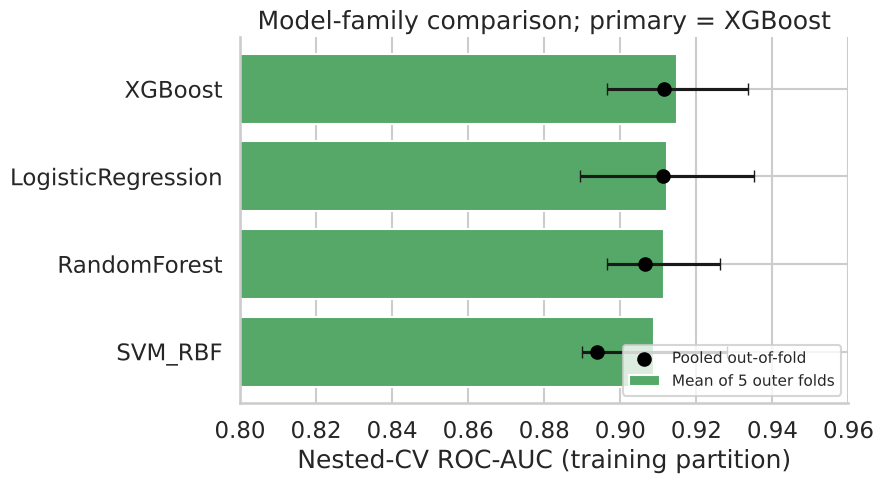

In [9]:
nested = cache("nested_cv_families", lambda: {f: nested_cv(ALL_FEATURES, f) for f in FAMILIES})
rows = []
for f in FAMILIES:
    oof, recs = nested[f]
    rows.append({"Model": f, "Mean_of_fold_AUC": np.mean([r["auc"] for r in recs]), "AUC_fold_SD": np.std([r["auc"] for r in recs]),
                 "Pooled_OOF_AUC": roc_auc_score(y_arr, oof), "Mean_of_fold_Brier": np.mean([r["brier"] for r in recs]),
                 "Pooled_OOF_Brier": brier_score_loss(y_arr, oof)})
fam = pd.DataFrame(rows).sort_values("Mean_of_fold_AUC", ascending=False).reset_index(drop=True)
fam["Gap"] = fam.Mean_of_fold_AUC - fam.Pooled_OOF_AUC
fam.round(4).to_csv(TABLE_DIR / "Table06_ModelFamilyComparison.csv", index=False)
print(fam.round(4).to_string(index=False))

best = fam.Mean_of_fold_AUC.max()
tied = fam[np.isclose(fam.Mean_of_fold_AUC, best, atol=5e-5)]
PRIMARY_MODEL_NAME = tied.sort_values("Mean_of_fold_Brier").iloc[0].Model
POOLED_WINNER = fam.sort_values("Pooled_OOF_AUC", ascending=False).iloc[0].Model
primary_oof, primary_recs = nested[PRIMARY_MODEL_NAME]
print(f"\nLOCKED PRIMARY_MODEL_NAME = {PRIMARY_MODEL_NAME}  (pooled-OOF winner: {POOLED_WINNER}; "
      f"{'agree' if POOLED_WINNER == PRIMARY_MODEL_NAME else 'DISAGREE - disclosed'})")
print("Per-fold tuned hyper-parameters:", [r["best_params"] for r in primary_recs])
np.save(MODEL_DIR / "primary_model_oof_proba.npy", primary_oof)
(MODEL_DIR / "primary_model_name.txt").write_text(PRIMARY_MODEL_NAME)

for _, r in fam.iterrows():
    record(f"NestedCV_meanfold_AUC_{r.Model}", round(r.Mean_of_fold_AUC, 3), "Table06")
    record(f"NestedCV_pooled_AUC_{r.Model}", round(r.Pooled_OOF_AUC, 3), "Table06")
record("Primary_model", PRIMARY_MODEL_NAME, "Table06"); record("Pooled_OOF_winner", POOLED_WINNER, "Table06")
record("Family_AUC_range_meanfold", round(fam.Mean_of_fold_AUC.max() - fam.Mean_of_fold_AUC.min(), 4), "Table06")

fig, ax = plt.subplots(figsize=(9, 5))
o = fam.sort_values("Mean_of_fold_AUC")
ax.barh(o.Model, o.Mean_of_fold_AUC, xerr=o.AUC_fold_SD, color="#55A868", capsize=4, label="Mean of 5 outer folds")
ax.scatter(o.Pooled_OOF_AUC, o.Model, color="black", zorder=3, label="Pooled out-of-fold")
ax.set_xlim(0.80, 0.96); ax.set_xlabel("Nested-CV ROC-AUC (training partition)")
ax.set_title(f"Model-family comparison; primary = {PRIMARY_MODEL_NAME}"); ax.legend(loc="lower right", fontsize=11)
savefig("Figure06_ModelFamilyComparison.png")

## Section 9 — Baselines and incremental value
Two complementary views: (a) a descriptive baseline suite (logistic regression, 10×5 repeated CV); (b) the formal paired test — the primary model versus an Age + IDH1 logistic regression tuned with the **same** nested protocol on the **same** outer folds (DeLong).

In [10]:
cv_base = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
base_sets = {"Age only": ["Age_at_diagnosis"], "IDH1 only": ["IDH1"], "Age + IDH1": ["Age_at_diagnosis", "IDH1"],
             "Clinical (Age + Gender + Race)": ["Age_at_diagnosis", "Gender", "Race"], "All 23 features": ALL_FEATURES}
bscore = {"roc_auc": "roc_auc", "balanced_accuracy": "balanced_accuracy", "mcc": make_scorer(matthews_corrcoef),
          "sensitivity": make_scorer(recall_score, pos_label=1), "specificity": make_scorer(recall_score, pos_label=0),
          "brier": make_scorer(brier_score_loss, response_method="predict_proba", greater_is_better=False)}
rows = []
for name, feats in base_sets.items():
    res = cross_validate(make_pipeline(feats, "LogisticRegression"), X_train[feats], y_train, cv=cv_base, scoring=bscore, n_jobs=N_JOBS)
    row = {"Model": name, "N_features": len(feats)}
    for m in bscore:
        v = -res[f"test_{m}"] if m == "brier" else res[f"test_{m}"]; row[f"{m}_mean"], row[f"{m}_sd"] = round(v.mean(), 4), round(v.std(), 4)
    rows.append(row)
rule = {m: [] for m in ["roc_auc", "balanced_accuracy", "mcc", "sensitivity", "specificity"]}
for _, te in cv_base.split(X_train, y_train):
    yt = y_train.iloc[te].values; pr = (X_train.iloc[te].IDH1.values == 0).astype(int)
    rule["roc_auc"].append(roc_auc_score(yt, pr)); rule["balanced_accuracy"].append(balanced_accuracy_score(yt, pr))
    rule["mcc"].append(matthews_corrcoef(yt, pr)); rule["sensitivity"].append(recall_score(yt, pr)); rule["specificity"].append(recall_score(yt, pr, pos_label=0))
rows.append({"Model": "Rule: IDH1 wild-type -> GBM (no fitting)", "N_features": 1,
             **{f"{m}_mean": round(np.mean(v), 4) for m, v in rule.items()}, **{f"{m}_sd": round(np.std(v), 4) for m, v in rule.items()}})
basetab = pd.DataFrame(rows); basetab.to_csv(TABLE_DIR / "Table05_BaselineIncrementalValue.csv", index=False)
print(basetab[["Model", "roc_auc_mean", "roc_auc_sd", "sensitivity_mean", "specificity_mean", "brier_mean"]].to_string(index=False))
for _, r in basetab.iterrows(): record(f"Baseline_AUC_{r.Model}", round(r.roc_auc_mean, 3), "Table05")

age_idh1_oof, age_idh1_recs = cache("age_idh1_nested", lambda: nested_cv(["Age_at_diagnosis", "IDH1"], "LogisticRegression"))
dl = delong(y_arr, primary_oof, age_idh1_oof)
print(f"\nPrimary ({PRIMARY_MODEL_NAME}) pooled-OOF AUC {dl['auc_A']:.4f} vs Age+IDH1 {dl['auc_B']:.4f}: "
      f"diff {dl['diff']:+.4f} (95% CI {dl['ci_lo']:+.4f} to {dl['ci_hi']:+.4f}), DeLong p = {dl['p']:.4f}")
record("Dev_AUC_primary_pooled", round(dl["auc_A"], 3), "Table07"); record("Dev_AUC_AgeIDH1_pooled", round(dl["auc_B"], 3), "Table07")
record("Dev_DeltaAUC_vs_AgeIDH1", round(dl["diff"], 3), "Table07", f"95% CI {dl['ci_lo']:+.3f} to {dl['ci_hi']:+.3f}")
record("Dev_DeLong_p_vs_AgeIDH1", round(dl["p"], 4), "Table07")

                                   Model  roc_auc_mean  roc_auc_sd  sensitivity_mean  specificity_mean  brier_mean
                                Age only        0.8079      0.0316            0.7610            0.7137      0.1785
                               IDH1 only        0.8558      0.0242            0.9326            0.7789      0.1253
                              Age + IDH1        0.8985      0.0213            0.9230            0.7905      0.1171
          Clinical (Age + Gender + Race)        0.8114      0.0310            0.7582            0.7124      0.1771
                         All 23 features        0.9186      0.0200            0.9191            0.8393      0.1042
Rule: IDH1 wild-type -> GBM (no fitting)        0.8558      0.0242            0.9326            0.7789         NaN
[cache] age_idh1_nested: MISS (computing) key=0668dc15f2



Primary (XGBoost) pooled-OOF AUC 0.9116 vs Age+IDH1 0.8963: diff +0.0153 (95% CI +0.0009 to +0.0297), DeLong p = 0.0368


np.float64(0.0368)

## Section 10 — Formal comparisons: primary model versus every other family and versus a nested soft-vote ensemble
The ensemble is leakage-free: its out-of-fold probability is the mean of the four families' nested out-of-fold probabilities (same outer folds, each family tuned in its own inner loop).

In [11]:
# validate DeLong SE against a paired bootstrap before trusting it
other = [f for f in FAMILIES if f != PRIMARY_MODEL_NAME][0]
bd = []
for _ in range(2000):
    i = rng.randint(0, len(y_arr), len(y_arr))
    if len(np.unique(y_arr[i])) < 2: continue
    bd.append(roc_auc_score(y_arr[i], primary_oof[i]) - roc_auc_score(y_arr[i], nested[other][0][i]))
ratio = delong(y_arr, primary_oof, nested[other][0])["se"] / np.std(bd)
print(f"DeLong SE / bootstrap SE = {ratio:.2f}"); assert 0.5 < ratio < 2.0, "DeLong implementation disagrees with bootstrap"

ensemble_oof = np.mean([nested[f][0] for f in FAMILIES], axis=0)
comps = [(f"{PRIMARY_MODEL_NAME} vs Age+IDH1 (LR, nested)", primary_oof, age_idh1_oof)]
comps += [(f"{PRIMARY_MODEL_NAME} vs {f}", primary_oof, nested[f][0]) for f in FAMILIES if f != PRIMARY_MODEL_NAME]
comps += [(f"Soft-vote ensemble (4 families, nested) vs {PRIMARY_MODEL_NAME}", ensemble_oof, primary_oof)]
rows = []
for name, a, b in comps:
    d = delong(y_arr, a, b); rows.append({"Comparison": name, "AUC_A": d["auc_A"], "AUC_B": d["auc_B"], "Diff": d["diff"],
                                          "Diff_CI_lo": d["ci_lo"], "Diff_CI_hi": d["ci_hi"], "DeLong_p": d["p"]})
# McNemar at 0.5 for the baseline comparison (classification agreement)
cp, cb = (primary_oof >= .5) == y_arr, (age_idh1_oof >= .5) == y_arr
tab = pd.crosstab(cb, cp).reindex(index=[False, True], columns=[False, True], fill_value=0).values
rows[0]["McNemar_p_at_0.5"] = mcnemar(tab, exact=False, correction=True).pvalue
stat = pd.DataFrame(rows); stat.round(4).to_csv(TABLE_DIR / "Table07_StatisticalComparison.csv", index=False)
print(stat.round(4).to_string(index=False))
ens = stat.iloc[-1]
record("Ensemble_pooled_AUC", round(ens.AUC_A, 3), "Table07"); record("Ensemble_vs_primary_p", round(ens.DeLong_p, 3), "Table07")
for _, r in stat.iloc[1:-1].iterrows(): record(f"DeLong_p_{r.Comparison}", round(r.DeLong_p, 3), "Table07")

DeLong SE / bootstrap SE = 1.02
                                        Comparison  AUC_A  AUC_B   Diff  Diff_CI_lo  Diff_CI_hi  DeLong_p  McNemar_p_at_0.5
                  XGBoost vs Age+IDH1 (LR, nested) 0.9116 0.8963 0.0153      0.0009      0.0297    0.0368            0.0033
                     XGBoost vs LogisticRegression 0.9116 0.9113 0.0003     -0.0095      0.0101    0.9508               NaN
                                XGBoost vs SVM_RBF 0.9116 0.8939 0.0177      0.0029      0.0324    0.0188               NaN
                           XGBoost vs RandomForest 0.9116 0.9065 0.0051     -0.0048      0.0150    0.3104               NaN
Soft-vote ensemble (4 families, nested) vs XGBoost 0.9127 0.9116 0.0011     -0.0053      0.0076    0.7267               NaN


## Section 11 — Calibration of the primary model (out-of-fold) and the deployment calibrator
Rule: lowest ECE among methods without small-sample degeneracy (no single probability value shared by > 10 % of patients).

                      Method    ECE  Brier  Slope  Calibration_in_the_large  Max_pileup_fraction  N_unique_values  Degenerate
          Raw (uncalibrated) 0.0413 0.1056 0.9665                   -0.2738               0.0149              374       False
Platt/sigmoid (cross-fitted) 0.0399 0.1057 0.9959                   -0.0042               0.0238              364       False
     Isotonic (cross-fitted) 0.0259 0.1052    NaN                       NaN               0.1416               58        True

LOCKED CALIBRATION_METHOD = Platt/sigmoid (cross-fitted)


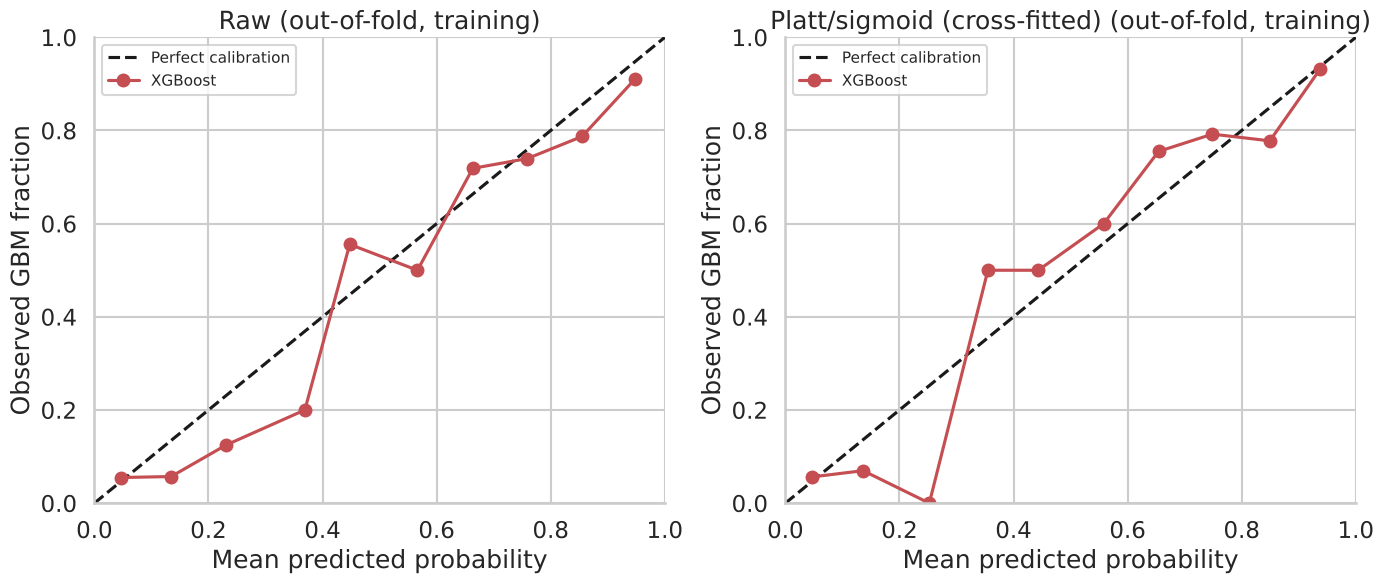

In [12]:
p_raw = np.clip(primary_oof, 1e-6, 1 - 1e-6)
ccv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
p_platt, p_iso = np.zeros_like(p_raw), np.zeros_like(p_raw)
logit = lambda p: np.log(p / (1 - p)).reshape(-1, 1)
for tr, te in ccv.split(p_raw.reshape(-1, 1), y_arr):
    p_platt[te] = LogisticRegression().fit(logit(p_raw[tr]), y_arr[tr]).predict_proba(logit(p_raw[te]))[:, 1]
    p_iso[te] = IsotonicRegression(out_of_bounds="clip").fit(p_raw[tr], y_arr[tr]).predict(p_raw[te])
def pileup(p): v, c = np.unique(np.round(p, 3), return_counts=True); return c.max() / len(p), len(v)
rows = []
for name, p in [("Raw (uncalibrated)", p_raw), ("Platt/sigmoid (cross-fitted)", p_platt), ("Isotonic (cross-fitted)", p_iso)]:
    pc = np.clip(p, 1e-6, 1 - 1e-6); s, i = cal_slope_intercept(y_arr, pc) if name != "Isotonic (cross-fitted)" else (np.nan, np.nan)
    pf, nu = pileup(p)
    rows.append({"Method": name, "ECE": ece(y_arr, pc), "Brier": brier_score_loss(y_arr, pc), "Slope": s,
                 "Calibration_in_the_large": i, "Max_pileup_fraction": pf, "N_unique_values": nu, "Degenerate": pf > 0.10})
calt = pd.DataFrame(rows); calt.round(4).to_csv(TABLE_DIR / "Table09_CalibrationComparison.csv", index=False)
print(calt.round(4).to_string(index=False))
el = calt[~calt.Degenerate]; CALIBRATION_METHOD = el.loc[el.ECE.idxmin(), "Method"]
primary_proba_final = {"Raw (uncalibrated)": p_raw, "Platt/sigmoid (cross-fitted)": p_platt,
                       "Isotonic (cross-fitted)": p_iso}[CALIBRATION_METHOD]
primary_proba_final = np.clip(primary_proba_final, 1e-6, 1 - 1e-6)
np.save(MODEL_DIR / "primary_proba_final.npy", primary_proba_final)
if CALIBRATION_METHOD.startswith("Raw"): DEPLOY = ("raw", None)
elif CALIBRATION_METHOD.startswith("Platt"): DEPLOY = ("platt", LogisticRegression().fit(logit(p_raw), y_arr))
else: DEPLOY = ("isotonic", IsotonicRegression(out_of_bounds="clip").fit(p_raw, y_arr))
def deploy_calibrate(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    if DEPLOY[0] == "raw": return p
    if DEPLOY[0] == "platt": return DEPLOY[1].predict_proba(logit(p))[:, 1]
    return np.clip(DEPLOY[1].predict(p), 1e-6, 1 - 1e-6)
with open(MODEL_DIR / "deployment_calibrator.pkl", "wb") as f: pickle.dump(DEPLOY, f)
r0 = calt.iloc[0]; iso = calt.iloc[2]
print(f"\nLOCKED CALIBRATION_METHOD = {CALIBRATION_METHOD}")
record("Calibration_locked", CALIBRATION_METHOD, "Table09")
record("Raw_ECE", round(r0.ECE, 3), "Table09"); record("Raw_slope", round(r0.Slope, 3), "Table09")
record("Raw_CITL", round(r0.Calibration_in_the_large, 3), "Table09"); record("Raw_Brier_OOF", round(r0.Brier, 3), "Table09")
record("Isotonic_pileup_pct", round(iso.Max_pileup_fraction * 100, 1), "Table09", f"{int(round(iso.Max_pileup_fraction*N_TRAIN))} of {N_TRAIN}")
prev_tr = y_arr.mean(); nos = prev_tr * (1 - prev_tr); b_final = brier_score_loss(y_arr, primary_proba_final)
record("Train_noskill_Brier", round(nos, 3), "Section 11", f"prevalence {TR_GBM}/{N_TRAIN}")
record("OOF_Brier_reduction_pct", round((1 - b_final / nos) * 100, 0), "Section 11")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (lbl, p) in zip(axes, [("Raw", p_raw), (CALIBRATION_METHOD, primary_proba_final)]):
    fp_, mp_ = calibration_curve(y_arr, p, n_bins=10, strategy="uniform")
    ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration"); ax.plot(mp_, fp_, "o-", color="#C44E52", label=PRIMARY_MODEL_NAME)
    ax.set(xlabel="Mean predicted probability", ylabel="Observed GBM fraction", title=f"{lbl} (out-of-fold, training)", xlim=(0, 1), ylim=(0, 1)); ax.legend(fontsize=11)
savefig("Figure07_CalibrationCurve.png")

## Section 12 — Operating threshold (Youden's J) and cost-ratio sensitivity analysis

LOCKED OPTIMAL_THRESHOLD = 0.351 (bootstrap 95% CI 0.257-0.567); OOF sens 0.926, spec 0.833


 Cost_ratio_FN_per_FP  Cost_optimal_threshold  Sensitivity  Specificity   PPV   NPV
                  1.0                   0.351        0.926        0.833 0.801 0.939
                  1.5                   0.351        0.926        0.833 0.801 0.939
                  2.0                   0.317        0.929        0.828 0.796 0.942
                  3.0                   0.317        0.929        0.828 0.796 0.942
                  5.0                   0.317        0.929        0.828 0.796 0.942
                  7.0                   0.197        0.933        0.810 0.780 0.943
                 10.0                   0.131        0.947        0.722 0.712 0.949


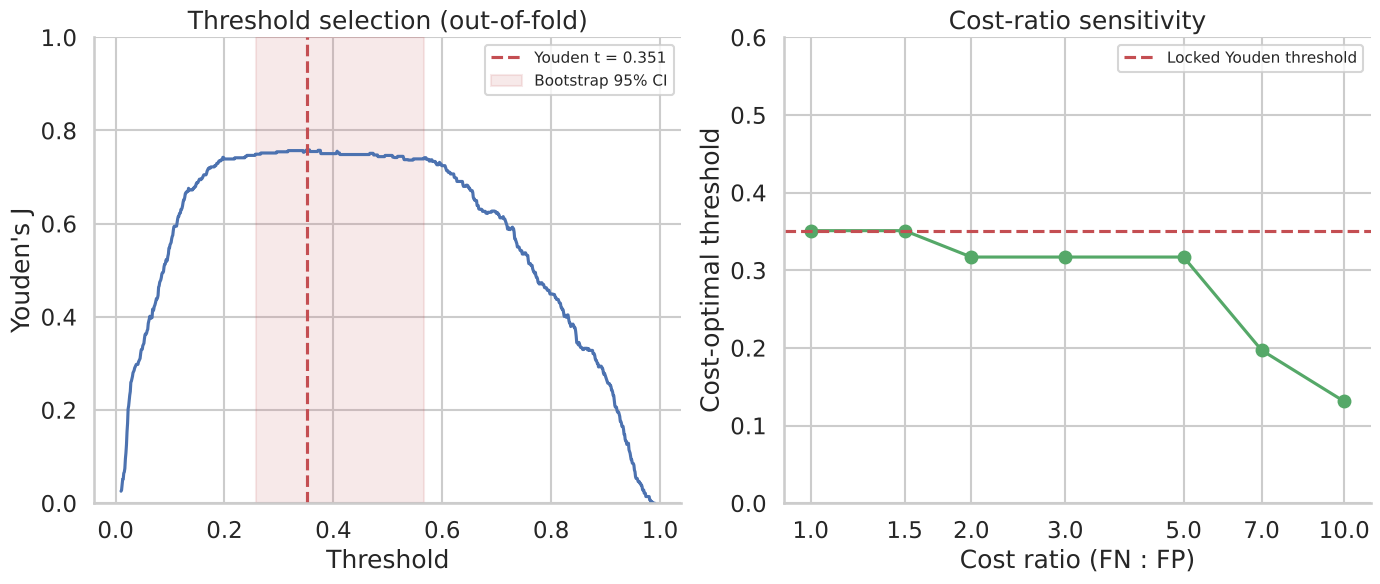

           Metric  Point_estimate  CI_lower_2.5%  CI_upper_97.5%
              AUC          0.9103         0.8890          0.9318
         Accuracy          0.8718         0.8465          0.8972
               F1          0.8586         0.8289          0.8878
Average_precision          0.8676         0.8290          0.9050
              MCC          0.7490         0.7009          0.7987
Balanced_accuracy          0.8792         0.8555          0.9030
      Sensitivity          0.9255         0.8960          0.9549
      Specificity          0.8329         0.7964          0.8706
              PPV          0.8006         0.7591          0.8453
              NPV          0.9391         0.9133          0.9639
            Brier          0.1057         0.0898          0.1213


In [13]:
grid = np.linspace(0.01, 0.99, 981)
def youden(y, p):
    P = p[None, :] >= grid[:, None]; pos = (y == 1)
    tp = (P & pos).sum(1); tn = (~P & ~pos).sum(1)
    j = tp / pos.sum() + tn / (~pos).sum() - 1
    return float(grid[j.argmax()]), j
OPTIMAL_THRESHOLD, J = youden(y_arr, primary_proba_final)
o = ops(y_arr, primary_proba_final, OPTIMAL_THRESHOLD)
bt = []
for _ in range(1000):
    i = rng.randint(0, len(y_arr), len(y_arr))
    if len(np.unique(y_arr[i])) > 1: bt.append(youden(y_arr[i], primary_proba_final[i])[0])
th_lo, th_hi = np.percentile(bt, [2.5, 97.5])
print(f"LOCKED OPTIMAL_THRESHOLD = {OPTIMAL_THRESHOLD:.3f} (bootstrap 95% CI {th_lo:.3f}-{th_hi:.3f}); "
      f"OOF sens {o['Sensitivity']:.3f}, spec {o['Specificity']:.3f}")
record("Threshold_Youden", round(OPTIMAL_THRESHOLD, 3), "Section 12", f"bootstrap 95% CI {th_lo:.3f}-{th_hi:.3f}")
record("Threshold_boot_CI_lo", round(th_lo, 3), "Section 12"); record("Threshold_boot_CI_hi", round(th_hi, 3), "Section 12")
record("Threshold_boot_n_resamples", 1000, "Section 12", f"bootstrap resamples drawn for the threshold CI (code: range(1000)); {len(bt)} contained both classes and were used; out-of-fold predictions held fixed (no refitting)")
record("Threshold_boot_n_resamples_used", len(bt), "Section 12")
record("OOF_sens_at_threshold", round(o["Sensitivity"], 3), "Section 12"); record("OOF_spec_at_threshold", round(o["Specificity"], 3), "Section 12")

rows = []
for r in [1, 1.5, 2, 3, 5, 7, 10]:
    costs = [confusion_at(y_arr, primary_proba_final, t)[2] + r * confusion_at(y_arr, primary_proba_final, t)[3] for t in grid]
    t = float(grid[int(np.argmin(costs))]); oo = ops(y_arr, primary_proba_final, t)
    rows.append({"Cost_ratio_FN_per_FP": r, "Cost_optimal_threshold": round(t, 3), "Sensitivity": round(oo["Sensitivity"], 3),
                 "Specificity": round(oo["Specificity"], 3), "PPV": round(oo["PPV"], 3), "NPV": round(oo["NPV"], 3)})
cost = pd.DataFrame(rows); cost.to_csv(TABLE_DIR / "Table10_ThresholdCostSensitivity.csv", index=False)
print(cost.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].plot(grid, J, color="#4C72B0"); axes[0].axvline(OPTIMAL_THRESHOLD, color="#C44E52", ls="--", label=f"Youden t = {OPTIMAL_THRESHOLD:.3f}")
axes[0].axvspan(th_lo, th_hi, color="#C44E52", alpha=.12, label="Bootstrap 95% CI")
axes[0].set(xlabel="Threshold", ylabel="Youden's J", title="Threshold selection (out-of-fold)", ylim=(0, 1)); axes[0].legend(fontsize=11)
axes[1].plot(cost.Cost_ratio_FN_per_FP, cost.Cost_optimal_threshold, "o-", color="#55A868")
axes[1].axhline(OPTIMAL_THRESHOLD, color="#C44E52", ls="--", label="Locked Youden threshold")
axes[1].set_xscale("log"); axes[1].set_xticks(cost.Cost_ratio_FN_per_FP); axes[1].get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
axes[1].set(xlabel="Cost ratio (FN : FP)", ylabel="Cost-optimal threshold", title="Cost-ratio sensitivity",
            ylim=(0, max(0.6, cost.Cost_optimal_threshold.max() + .05))); axes[1].legend(fontsize=11)
savefig("Figure08_ThresholdSensitivity.png")

# Development-level bootstrap CIs for the primary model at the locked threshold
def metric_set(y, p, t):
    pr = (p >= t).astype(int)
    return {"AUC": roc_auc_score(y, p), "Accuracy": accuracy_score(y, pr), "F1": f1_score(y, pr),
            "Average_precision": average_precision_score(y, p), "MCC": matthews_corrcoef(y, pr),
            "Balanced_accuracy": balanced_accuracy_score(y, pr), "Sensitivity": recall_score(y, pr),
            "Specificity": recall_score(y, pr, pos_label=0), "PPV": precision_score(y, pr, zero_division=0),
            "NPV": precision_score(y, pr, pos_label=0, zero_division=0), "Brier": brier_score_loss(y, p)}
def boot_ci(y, p, t, B=2000):
    pt = metric_set(y, p, t); bs = {k: [] for k in pt}
    for _ in range(B):
        i = rng.randint(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        for k, v in metric_set(y[i], p[i], t).items(): bs[k].append(v)
    return pd.DataFrame([{"Metric": k, "Point_estimate": round(pt[k], 4), "CI_lower_2.5%": round(np.percentile(v, 2.5), 4),
                          "CI_upper_97.5%": round(np.percentile(v, 97.5), 4)} for k, v in bs.items()])
dev_ci = boot_ci(y_arr, primary_proba_final, OPTIMAL_THRESHOLD)
dev_ci.to_csv(TABLE_DIR / "Table08_PrimaryModelBootstrapCI.csv", index=False); print(dev_ci.to_string(index=False))

## Section 13 — Repeated nested CV stability of the primary model (10 repeats, different outer splits)

[cache] repeated_nested_XGBoost: MISS (computing) key=640ddd8a14


 repeat  mean_of_fold_auc  pooled_oof_auc  youden_threshold_raw_scale
      0            0.9171          0.9117                       0.497
      1            0.9181          0.9185                       0.493
      2            0.9203          0.9208                       0.493
      3            0.9149          0.9106                       0.405
      4            0.9085          0.9033                       0.410
      5            0.9171          0.9124                       0.492
      6            0.9199          0.9186                       0.441
      7            0.9112          0.9077                       0.409
      8            0.9195          0.9140                       0.469
      9            0.9173          0.9155                       0.481


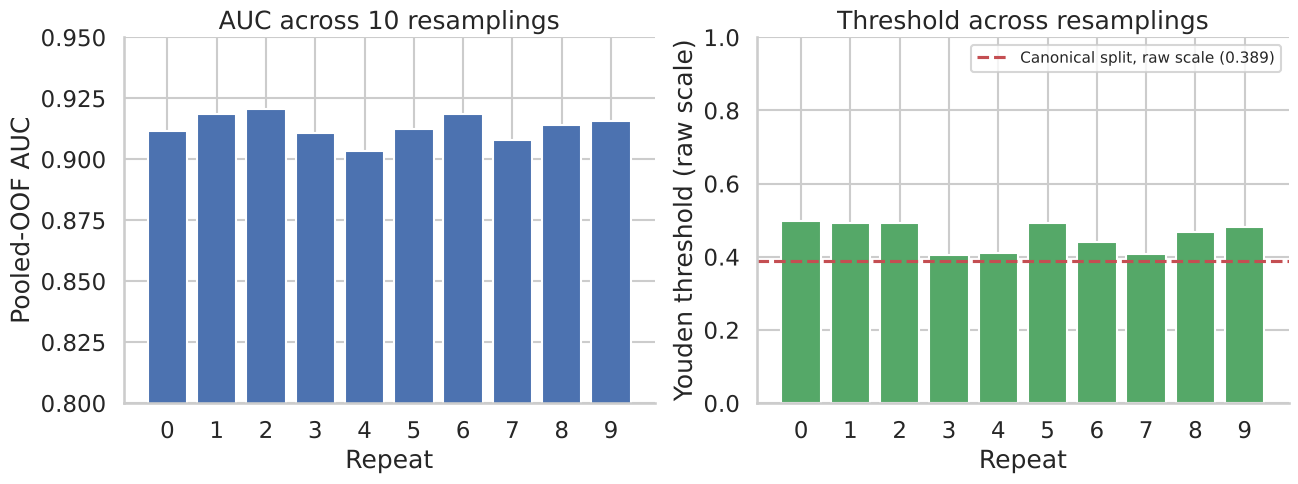

In [14]:
def _repeats():
    out = []
    for r in range(10):
        ocv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE + 1000 + r)
        oof, recs = nested_cv(ALL_FEATURES, PRIMARY_MODEL_NAME, outer=ocv)
        out.append({"repeat": r, "mean_of_fold_auc": np.mean([x["auc"] for x in recs]), "pooled_oof_auc": roc_auc_score(y_arr, oof),
                    "youden_threshold_raw_scale": youden(y_arr, np.clip(oof, 1e-6, 1 - 1e-6))[0]})
    return out
rep = pd.DataFrame(cache(f"repeated_nested_{PRIMARY_MODEL_NAME}", _repeats, deps=[youden]))
rep.round(4).to_csv(TABLE_DIR / "Table_RepeatedNestedCVStability.csv", index=False); print(rep.round(4).to_string(index=False))
for c in ["mean_of_fold_auc", "pooled_oof_auc", "youden_threshold_raw_scale"]:
    record(f"Repeated_{c}_mean", round(rep[c].mean(), 3), "Table_RepeatedNestedCVStability",
           f"SD {rep[c].std():.3f}; range {rep[c].min():.3f}-{rep[c].max():.3f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(rep.repeat.astype(str), rep.pooled_oof_auc, color="#4C72B0"); axes[0].set(ylim=(0.8, 0.95), xlabel="Repeat", ylabel="Pooled-OOF AUC", title="AUC across 10 resamplings")
RAW_SCALE_YOUDEN = youden(y_arr, p_raw)[0]
record("Canonical_raw_scale_Youden", round(RAW_SCALE_YOUDEN, 3), "Section 13", f"locked threshold {OPTIMAL_THRESHOLD:.3f} is on the {CALIBRATION_METHOD} scale")
axes[1].bar(rep.repeat.astype(str), rep.youden_threshold_raw_scale, color="#55A868")
axes[1].axhline(RAW_SCALE_YOUDEN, color="#C44E52", ls="--", label=f"Canonical split, raw scale ({RAW_SCALE_YOUDEN:.3f})")
axes[1].set(ylim=(0, 1), xlabel="Repeat", ylabel="Youden threshold (raw scale)", title="Threshold across resamplings"); axes[1].legend(fontsize=11)
savefig("Figure_RepeatedNestedCVStability.png")

## Section 14 — Decision-curve analysis (development, out-of-fold)

Thresholds where primary net benefit exceeds Age+IDH1 with bootstrap 95% CI excluding 0: [0.01, 0.02, 0.04, 0.05, 0.06, 0.17, 0.19, 0.2, 0.21, 0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3, 0.31, 0.32, 0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4, 0.41, 0.42, 0.43, 0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5, 0.51, 0.52, 0.53, 0.54, 0.55, 0.56, 0.57, 0.58, 0.59, 0.6, 0.61]


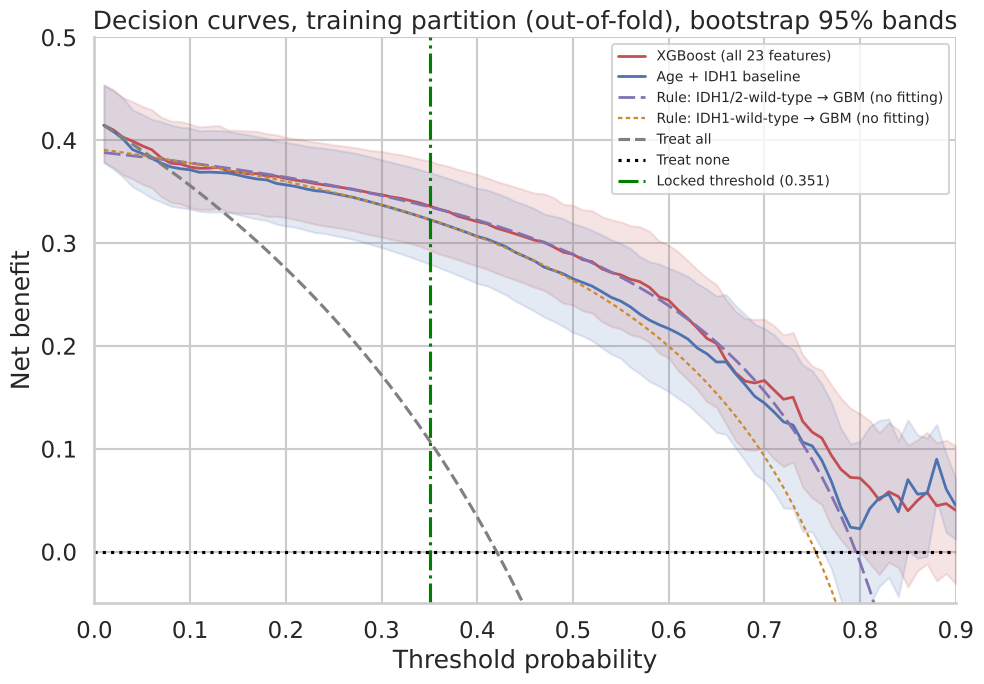

In [15]:
ts = np.round(np.arange(0.01, 0.91, 0.01), 2); prev = y_arr.mean()
age_idh1_cal = age_idh1_oof   # baseline probabilities as produced (LR, nested)
# R4 (RR-4): the no-fit IDH rules are added as decision strategies. A binary rule classifies the same patients as
# positive at every threshold, so its net benefit is TP/n - FP/n * t/(1-t): a curve with the shape of "treat all"
# scaled by the rule's sensitivity and false-positive rate. The extra bootstrap columns reuse the same resample
# indices, so the random stream and every previously reported column are unchanged.
rule1_tr = (Xtr.IDH1.values == 0).astype(int); rule12_tr = ((Xtr.IDH1.values == 0) & (Xtr.IDH2.values == 0)).astype(int)
nb_p, nb_b = net_benefit(y_arr, primary_proba_final, ts), net_benefit(y_arr, age_idh1_cal, ts)
nb_r1, nb_r12 = net_benefit(y_arr, rule1_tr, ts), net_benefit(y_arr, rule12_tr, ts)
nb_all = prev - (1 - prev) * ts / (1 - ts)
B = np.full((1000, len(ts), 7), np.nan)
for b in range(1000):
    i = rng.randint(0, len(y_arr), len(y_arr))
    if len(np.unique(y_arr[i])) < 2: continue
    B[b, :, 0] = net_benefit(y_arr[i], primary_proba_final[i], ts); B[b, :, 1] = net_benefit(y_arr[i], age_idh1_cal[i], ts)
    B[b, :, 2] = B[b, :, 0] - B[b, :, 1]
    B[b, :, 3] = net_benefit(y_arr[i], rule1_tr[i], ts); B[b, :, 4] = net_benefit(y_arr[i], rule12_tr[i], ts)
    B[b, :, 5] = B[b, :, 0] - B[b, :, 3]; B[b, :, 6] = B[b, :, 0] - B[b, :, 4]
lo, hi = np.nanpercentile(B, 2.5, axis=0), np.nanpercentile(B, 97.5, axis=0)
dca = pd.DataFrame({"Threshold": ts, "Primary_NB": nb_p, "Primary_NB_lo": lo[:, 0], "Primary_NB_hi": hi[:, 0],
                    "AgeIDH1_NB": nb_b, "AgeIDH1_NB_lo": lo[:, 1], "AgeIDH1_NB_hi": hi[:, 1],
                    "Delta_NB": nb_p - nb_b, "Delta_NB_lo": lo[:, 2], "Delta_NB_hi": hi[:, 2], "TreatAll_NB": nb_all, "TreatNone_NB": 0.0,
                    "RuleIDH1_NB": nb_r1, "RuleIDH1_NB_lo": lo[:, 3], "RuleIDH1_NB_hi": hi[:, 3],
                    "RuleIDH12_NB": nb_r12, "RuleIDH12_NB_lo": lo[:, 4], "RuleIDH12_NB_hi": hi[:, 4],
                    "Delta_NB_vs_RuleIDH1": nb_p - nb_r1, "Delta_NB_vs_RuleIDH1_lo": lo[:, 5], "Delta_NB_vs_RuleIDH1_hi": hi[:, 5],
                    "Delta_NB_vs_RuleIDH12": nb_p - nb_r12, "Delta_NB_vs_RuleIDH12_lo": lo[:, 6], "Delta_NB_vs_RuleIDH12_hi": hi[:, 6]})
dca.round(4).to_csv(TABLE_DIR / "Table11_DecisionCurveAnalysis.csv", index=False)
sig = dca[(dca.Delta_NB_lo > 0)]
print(f"Thresholds where primary net benefit exceeds Age+IDH1 with bootstrap 95% CI excluding 0: "
      f"{sig.Threshold.tolist() if len(sig) else 'none'}")
beats_all = dca[(dca.Primary_NB > dca.TreatAll_NB) & (dca.Primary_NB > 0)]
record("DCA_thresholds_DeltaNB_CI_excl_0", len(sig), "Table11", f"{sig.Threshold.min() if len(sig) else '-'}-{sig.Threshold.max() if len(sig) else '-'}")
record("DCA_primary_beats_treatall_from", float(beats_all.Threshold.min()), "Table11")
_r = dca.loc[(dca.Threshold - round(OPTIMAL_THRESHOLD, 2)).abs().idxmin()]
record("DCA_dev_DeltaNB_at_tau", round(_r.Delta_NB, 3), "Table11", f"threshold {_r.Threshold:.2f}; 95% CI {_r.Delta_NB_lo:.3f} to {_r.Delta_NB_hi:.3f}")
record("DCA_dev_NB_primary_at_tau", round(_r.Primary_NB, 3), "Table11", f"threshold {_r.Threshold:.2f}; 95% CI {_r.Primary_NB_lo:.3f} to {_r.Primary_NB_hi:.3f}")
for _k, _c in [("ruleIDH1", "RuleIDH1"), ("ruleIDH12", "RuleIDH12")]:
    record(f"DCA_dev_NB_{_k}_at_tau", round(_r[f"{_c}_NB"], 3), "Table11", f"threshold {_r.Threshold:.2f}; 95% CI {_r[f'{_c}_NB_lo']:.3f} to {_r[f'{_c}_NB_hi']:.3f}")
    record(f"DCA_dev_DeltaNB_model_minus_{_k}_at_tau", round(_r[f"Delta_NB_vs_{_c}"], 3), "Table11",
           f"threshold {_r.Threshold:.2f}; paired bootstrap 95% CI {_r[f'Delta_NB_vs_{_c}_lo']:.3f} to {_r[f'Delta_NB_vs_{_c}_hi']:.3f}")
    _w = dca[(dca.Threshold >= 0.30) & (dca.Threshold <= 0.50)]
    record(f"DCA_dev_n_thresholds_0.30-0.50_rule_NB_ge_model_{_k}", int((_w[f"{_c}_NB"] >= _w.Primary_NB - 1e-12).sum()), "Table11", f"of {len(_w)} grid points")
fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(ts, nb_p, color="#C44E52", lw=2, label=f"{PRIMARY_MODEL_NAME} (all 23 features)"); ax.fill_between(ts, lo[:, 0], hi[:, 0], color="#C44E52", alpha=.15)
ax.plot(ts, nb_b, color="#4C72B0", lw=2, label="Age + IDH1 baseline"); ax.fill_between(ts, lo[:, 1], hi[:, 1], color="#4C72B0", alpha=.15)
ax.plot(ts, nb_r12, color="#8172B2", lw=2, ls=(0, (6, 2)), label="Rule: IDH1/2-wild-type → GBM (no fitting)")
ax.plot(ts, nb_r1, color="#CC8A2E", lw=1.6, ls=(0, (2, 1.5)), label="Rule: IDH1-wild-type → GBM (no fitting)")
ax.plot(ts, nb_all, color="grey", ls="--", label="Treat all"); ax.axhline(0, color="black", ls=":", label="Treat none")
ax.axvline(OPTIMAL_THRESHOLD, color="green", ls="-.", label=f"Locked threshold ({OPTIMAL_THRESHOLD:.3f})")
ax.set(xlabel="Threshold probability", ylabel="Net benefit", xlim=(0, .9), ylim=(-.05, .5),
       title="Decision curves, training partition (out-of-fold), bootstrap 95% bands"); ax.legend(fontsize=10, loc="upper right")
savefig("Figure09_DecisionCurveAnalysis.png")

## Section 15 — Feature attribution for the primary model (fold-aggregated, held-out patients only)
* Logistic regression → `shap.LinearExplainer` with the fold's own training data as background (interventional, i.e. features treated as independent); fold coefficients reported alongside.
* Random forest / XGBoost → `shap.TreeExplainer` without background data (`feature_perturbation="tree_path_dependent"`).
* SVM → `shap.KernelExplainer` with a 25-centroid k-means background of the fold's training data.
Permutation importance (AUC drop, 20 repeats) is computed for the full pipeline on raw features. SHAP values are on the log-odds (margin) scale.

[cache] explain_XGBoost: MISS (computing) key=e31f119a79


SHAP method: TreeExplainer (tree_path_dependent; no background data)
         Feature  Mean_abs_SHAP
            IDH1         1.6561
Age_at_diagnosis         0.5535
            TP53         0.4341
            PTEN         0.1862
             CIC         0.1306
             NF1         0.1244
            IDH2         0.1218
            ATRX         0.0944
            EGFR         0.0750
          PIK3R1         0.0523
         Feature  Mean_permutation_importance  SD_across_folds
            IDH1                       0.2662           0.0056
Age_at_diagnosis                       0.0186           0.0091
            TP53                       0.0148           0.0047
            IDH2                       0.0060           0.0035
             NF1                       0.0043           0.0025
             CIC                       0.0029           0.0019
            PTEN                       0.0028           0.0027
            ATRX                       0.0028           0.0022
           M

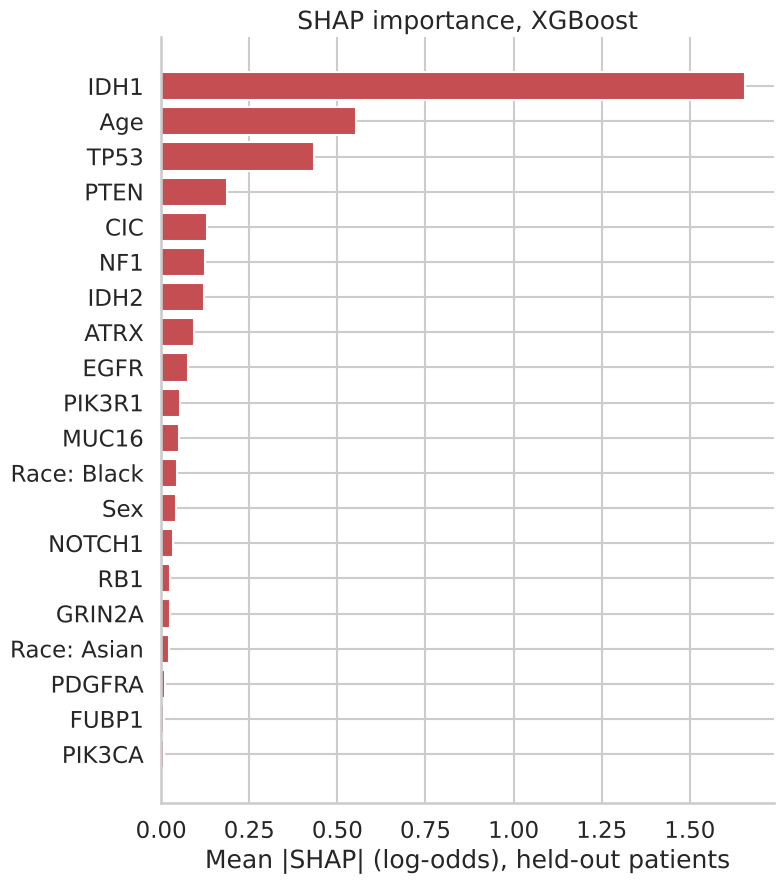

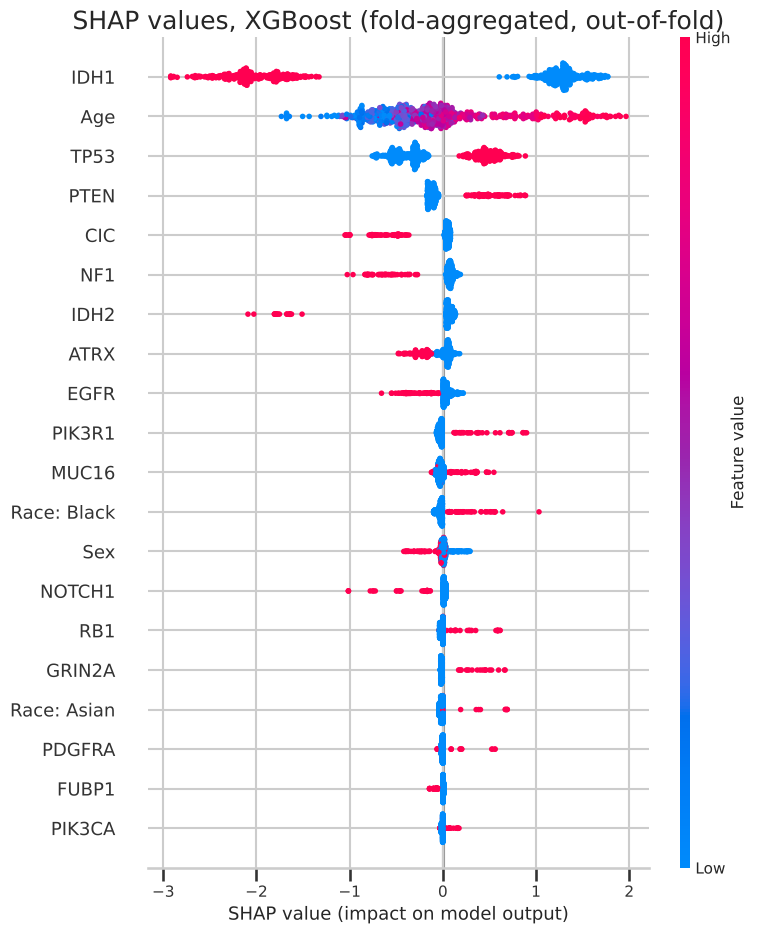

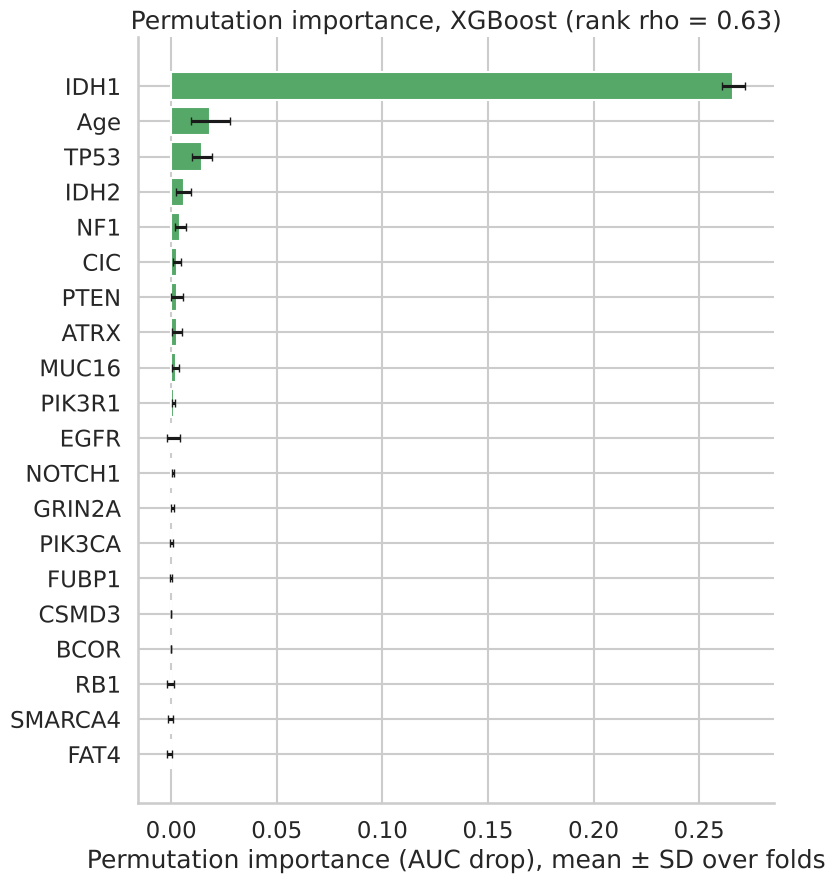

In [16]:
def explain_fold(family, params, tr, te):
    pipe = make_pipeline(ALL_FEATURES, family); pipe.set_params(**params); pipe.fit(Xtr.iloc[tr], ytr.iloc[tr])
    prep, clf = pipe.named_steps["preprocess"], pipe.named_steps["clf"]
    Xtr_t, Xte_t = prep.transform(Xtr.iloc[tr]), prep.transform(Xtr.iloc[te]); names = list(prep.get_feature_names_out())
    if family == "LogisticRegression":
        ex = shap.LinearExplainer(clf, shap.maskers.Independent(Xtr_t, max_samples=len(Xtr_t))); sv = ex.shap_values(Xte_t); coef = clf.coef_[0]
        method = "LinearExplainer (interventional; background = fold training data)"
    elif family in TREE_FAMILIES:
        ex = shap.TreeExplainer(clf, feature_perturbation="tree_path_dependent"); sv = ex.shap_values(Xte_t, check_additivity=False)
        if isinstance(sv, list): sv = sv[1]
        if sv.ndim == 3: sv = sv[:, :, 1]
        coef = None; method = "TreeExplainer (tree_path_dependent; no background data)"
    else:
        f = lambda Z: clf.decision_function(Z)
        ex = shap.KernelExplainer(f, shap.kmeans(Xtr_t, 25)); sv = ex.shap_values(Xte_t, nsamples=200); coef = None
        method = "KernelExplainer on decision function (k-means background, 25 centroids)"
    perm = permutation_importance(pipe, Xtr.iloc[te], ytr.iloc[te], scoring="roc_auc", n_repeats=20,
                                  random_state=RANDOM_STATE, n_jobs=N_JOBS).importances_mean
    return {"sv": sv, "Xte_t": Xte_t, "te": te, "names": names, "coef": coef, "perm": perm, "method": method}

def _explain():
    return [explain_fold(PRIMARY_MODEL_NAME, primary_recs[k]["best_params"], tr, te)
            for k, (tr, te) in enumerate(outer_cv.split(Xtr, ytr))]
EX = cache(f"explain_{PRIMARY_MODEL_NAME}", _explain, deps=[explain_fold], ctx=[r["best_params"] for r in primary_recs])
SHAP_METHOD = EX[0]["method"]; names = EX[0]["names"]
order = np.argsort(np.concatenate([e["te"] for e in EX]))
shap_matrix = np.vstack([e["sv"] for e in EX])[order]; X_disp = np.vstack([e["Xte_t"] for e in EX])[order]
shap_imp = pd.DataFrame({"Feature": names, "Mean_abs_SHAP": np.abs(shap_matrix).mean(0)}).sort_values("Mean_abs_SHAP", ascending=False)
shap_imp.round(4).to_csv(TABLE_DIR / "Table12_SHAPImportance.csv", index=False)
perm_m = np.vstack([e["perm"] for e in EX])
perm_imp = pd.DataFrame({"Feature": ALL_FEATURES, "Mean_permutation_importance": perm_m.mean(0), "SD_across_folds": perm_m.std(0)}) \
             .sort_values("Mean_permutation_importance", ascending=False)
perm_imp.round(4).to_csv(TABLE_DIR / "Table13_PermutationImportance.csv", index=False)
rhos = [spearmanr(perm_m[i], perm_m[j])[0] for i in range(5) for j in range(i + 1, 5)]
print("SHAP method:", SHAP_METHOD); print(shap_imp.head(10).round(4).to_string(index=False)); print(perm_imp.head(10).round(4).to_string(index=False))
print(f"Permutation ranking stability across folds: mean pairwise Spearman rho = {np.mean(rhos):.2f}")
if EX[0]["coef"] is not None:
    C = np.vstack([e["coef"] for e in EX])
    coef_t = pd.DataFrame({"Feature": names, "Coef_mean": C.mean(0), "Coef_SD": C.std(0), "OR_mean": np.exp(C.mean(0))}) \
               .reindex(columns=["Feature", "Coef_mean", "Coef_SD", "OR_mean"]).sort_values("Coef_mean", key=abs, ascending=False)
    coef_t.round(4).to_csv(TABLE_DIR / "Table23_PrimaryLR_FoldCoefficients.csv", index=False)
    print("\nFold-averaged log-odds coefficients (Age per SD; binary features per mutation):"); print(coef_t.head(10).round(3).to_string(index=False))
record("SHAP_method", SHAP_METHOD, "Section 15"); record("Perm_rank_stability_rho", round(np.mean(rhos), 2), "Section 15")
for f in shap_imp.Feature.head(4): record(f"SHAP_{f}", round(float(shap_imp.set_index('Feature').loc[f, 'Mean_abs_SHAP']), 3), "Table12")
for f in perm_imp.Feature.head(4): record(f"Perm_{f}", round(float(perm_imp.set_index('Feature').loc[f, 'Mean_permutation_importance']), 3), "Table13")

# R4 (R2 W8 / RR-14): display names in figures only; tables and ManuscriptNumbers keys keep the raw variable names
DISPLAY_NAMES = {"Age_at_diagnosis": "Age", "Gender": "Sex", "Race": "Race", "Race_1": "Race: Black",
                 "Race_2": "Race: Asian", "Race_3": "Race: AI/AN"}
disp = lambda f: DISPLAY_NAMES.get(f, f)
fig, ax = plt.subplots(figsize=(8, 9)); t20 = shap_imp.head(20).iloc[::-1]
ax.barh(t20.Feature.map(disp), t20.Mean_abs_SHAP, color="#C44E52"); ax.set(xlabel="Mean |SHAP| (log-odds), held-out patients", title=f"SHAP importance, {PRIMARY_MODEL_NAME}")
savefig("Figure10_SHAPImportance.png")
plt.figure(figsize=(9, 9)); shap.summary_plot(shap_matrix, pd.DataFrame(X_disp, columns=[disp(n) for n in names]), show=False, max_display=20)
plt.title(f"SHAP values, {PRIMARY_MODEL_NAME} (fold-aggregated, out-of-fold)"); savefig("Figure11_SHAPBeeswarm.png")
fig, ax = plt.subplots(figsize=(8, 9)); t20 = perm_imp.head(20).iloc[::-1]
ax.barh(t20.Feature.map(disp), t20.Mean_permutation_importance, xerr=t20.SD_across_folds, color="#55A868", capsize=3)
ax.set(xlabel="Permutation importance (AUC drop), mean ± SD over folds", title=f"Permutation importance, {PRIMARY_MODEL_NAME} (rank rho = {np.mean(rhos):.2f})")
savefig("Figure12_PermutationImportance.png")

## Section 16 — Leave-one-feature-out (fully nested)
For each feature, the primary model family is re-tuned and re-evaluated by nested CV without that feature, on the same outer folds. ΔAUC compares pooled out-of-fold AUCs (paired DeLong). Sensitivity, specificity and net benefit use the locked threshold after the locked deployment calibration.

In [17]:
def _lofo():
    return {f: nested_cv([x for x in ALL_FEATURES if x != f], PRIMARY_MODEL_NAME)[0] for f in ALL_FEATURES}
lofo_oof = cache(f"lofo_nested_{PRIMARY_MODEL_NAME}", _lofo)
full_cal = deploy_calibrate(primary_oof); full_o = ops(y_arr, full_cal, OPTIMAL_THRESHOLD)
full_nb = net_benefit(y_arr, full_cal, [OPTIMAL_THRESHOLD])[0]; full_ece = ece(y_arr, full_cal); full_br = brier_score_loss(y_arr, full_cal)
rows = []
for f, oof in lofo_oof.items():
    pc = deploy_calibrate(oof); d = delong(y_arr, primary_oof, oof); oo = ops(y_arr, pc, OPTIMAL_THRESHOLD)
    rows.append({"Feature_removed": f, "AUC_without": d["auc_B"], "Delta_AUC": d["diff"], "Delta_AUC_CI_lo": d["ci_lo"],
                 "Delta_AUC_CI_hi": d["ci_hi"], "DeLong_p": d["p"], "Delta_Brier": brier_score_loss(y_arr, pc) - full_br,
                 "Delta_ECE": ece(y_arr, pc) - full_ece, "Delta_Sensitivity": full_o["Sensitivity"] - oo["Sensitivity"],
                 "Delta_Specificity": full_o["Specificity"] - oo["Specificity"],
                 "Delta_NetBenefit": full_nb - net_benefit(y_arr, pc, [OPTIMAL_THRESHOLD])[0]})
lofo = pd.DataFrame(rows).sort_values("Delta_AUC", ascending=False).reset_index(drop=True)
from statsmodels.stats.multitest import multipletests
lofo["DeLong_p_Holm"] = multipletests(lofo.DeLong_p, method="holm")[1]
lofo.round(4).to_csv(TABLE_DIR / "Table14_LeaveOneFeatureOut.csv", index=False)
print(f"Full model pooled-OOF AUC = {roc_auc_score(y_arr, primary_oof):.4f}  (positive Delta = performance lost when the feature is removed)")
print(lofo.head(8).round(4).to_string(index=False))
for f in lofo.Feature_removed.head(3):
    r = lofo.set_index("Feature_removed").loc[f]
    record(f"LOFO_DeltaAUC_{f}", round(r.Delta_AUC, 3), "Table14", f"p={r.DeLong_p:.3g} (Holm {r.DeLong_p_Holm:.3g}); dSens {r.Delta_Sensitivity:+.3f}; dSpec {r.Delta_Specificity:+.3f}; dNB {r.Delta_NetBenefit:+.3f}; dECE {r.Delta_ECE:+.3f}")
record("LOFO_n_features_p_lt_0.05", int((lofo.DeLong_p < 0.05).sum()), "Table14", "unadjusted")
record("LOFO_n_features_Holm_lt_0.05", int((lofo.DeLong_p_Holm < 0.05).sum()), "Table14", ", ".join(lofo.loc[lofo.DeLong_p_Holm < 0.05, "Feature_removed"]))

[cache] lofo_nested_XGBoost: MISS (computing) key=c227b5e8dd


Full model pooled-OOF AUC = 0.9116  (positive Delta = performance lost when the feature is removed)
 Feature_removed  AUC_without  Delta_AUC  Delta_AUC_CI_lo  Delta_AUC_CI_hi  DeLong_p  Delta_Brier  Delta_ECE  Delta_Sensitivity  Delta_Specificity  Delta_NetBenefit  DeLong_p_Holm
            IDH1       0.8901     0.0214           0.0077           0.0352    0.0022       0.0223     0.0270             0.0248             0.0514            0.0266         0.0515
             NF1       0.8970     0.0146           0.0045           0.0246    0.0045       0.0061     0.0237            -0.0035             0.0129            0.0025         0.0985
           MUC16       0.8983     0.0133           0.0040           0.0226    0.0049       0.0058     0.0200            -0.0071             0.0026           -0.0022         0.1034
            TP53       0.9015     0.0101          -0.0012           0.0214    0.0786       0.0045     0.0267            -0.0071             0.0154            0.0019         1.0000


0

## Section 17 — Reduced-panel ablation with nested feature selection, and the panel locked for the test set
In each outer fold: (i) features are ranked by permutation importance from a 3-fold inner CV on that fold's training portion (primary family, default hyper-parameters, locked imbalance strategy); (ii) the top-*k* panel is tuned by inner CV and scored on the held-out fold. The held-out fold never informs its own ranking. **Pre-specified rule:** the 4-feature panel carried to the test set is the set of features most often selected in the folds' top-4 (majority vote; ties broken by mean rank).

[cache] panels_nested_XGBoost: MISS (computing) key=259e8b9a74


 N_features                           Majority_panel                                             Selection_counts  Mean_of_fold_AUC  Fold_SD  Pooled_OOF_AUC  Pct_of_full_pooled  DeltaAUC_vs_full  DeLong_p_vs_full
          1                                     IDH1                                                     IDH1:5/5            0.8557   0.0201          0.8477             92.9924            0.0639            0.0000
          2                               IDH1, IDH2                                           IDH1:5/5; IDH2:2/5            0.8708   0.0226          0.8656             94.9564            0.0460            0.0000
          3             IDH1, Age_at_diagnosis, IDH2                     IDH1:5/5; Age_at_diagnosis:5/5; IDH2:2/5            0.8910   0.0202          0.8842             96.9910            0.0274            0.0002
          4       IDH1, Age_at_diagnosis, IDH2, TP53           IDH1:5/5; Age_at_diagnosis:5/5; IDH2:3/5; TP53:3/5            0.9044   0.0070        

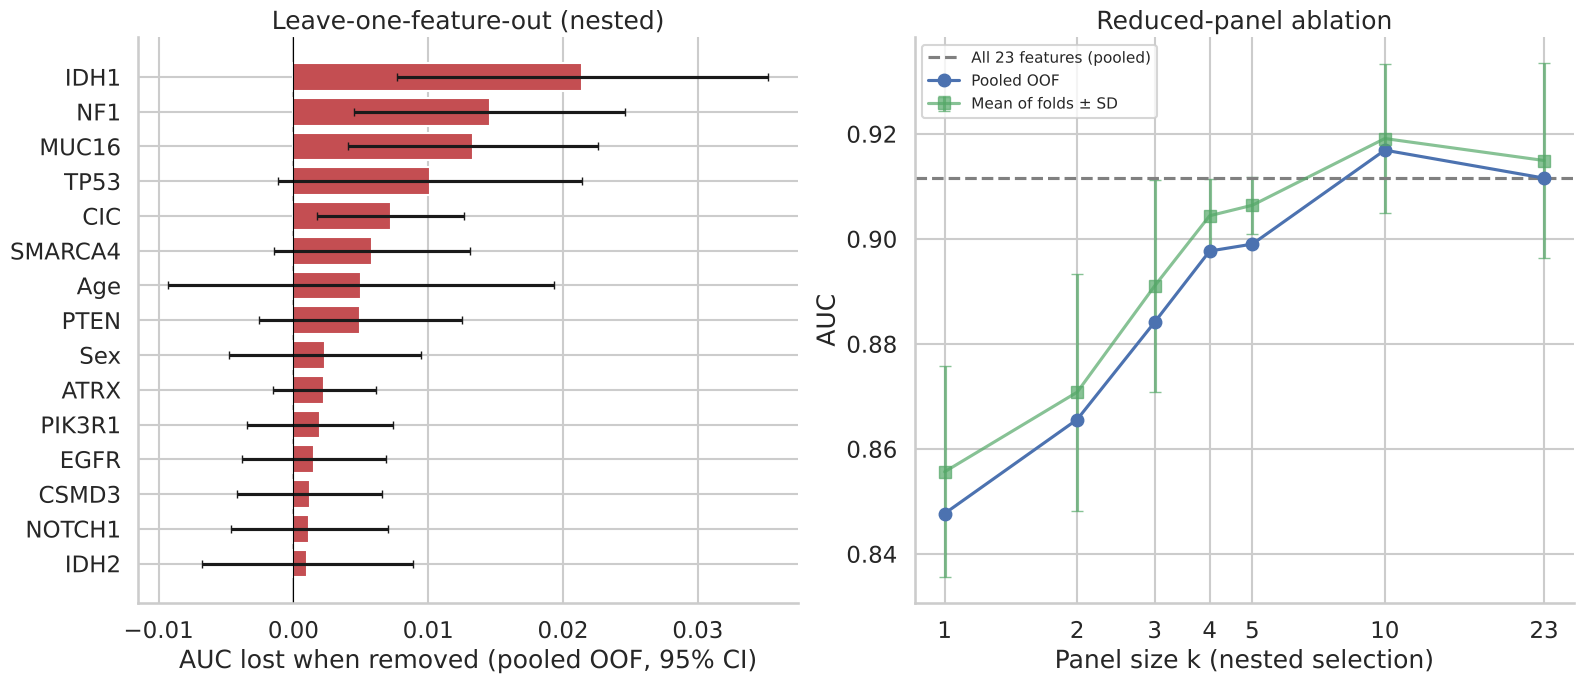

In [18]:
PANEL_SIZES = [1, 2, 3, 4, 5, 10]
def _panels():
    oof = {k: np.zeros(len(ytr)) for k in PANEL_SIZES}; fold_auc = {k: [] for k in PANEL_SIZES}; rankings = []
    for k_fold, (tr, te) in enumerate(outer_cv.split(Xtr, ytr)):
        Xa, ya = Xtr.iloc[tr], ytr.iloc[tr]; imps = []
        for itr, iva in StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE).split(Xa, ya):
            pipe = make_pipeline(ALL_FEATURES, PRIMARY_MODEL_NAME).fit(Xa.iloc[itr], ya.iloc[itr])
            imps.append(permutation_importance(pipe, Xa.iloc[iva], ya.iloc[iva], scoring="roc_auc", n_repeats=10,
                                               random_state=RANDOM_STATE, n_jobs=N_JOBS).importances_mean)
        score = np.mean(imps, 0); ranked = [ALL_FEATURES[i] for i in np.argsort(-score, kind="stable")]; rankings.append(ranked)
        params, n_iter = SEARCH_SPACES[PRIMARY_MODEL_NAME]
        for k in PANEL_SIZES:
            feats = ranked[:k]
            s = RandomizedSearchCV(make_pipeline(feats, PRIMARY_MODEL_NAME), params, n_iter=n_iter, scoring="roc_auc",
                                   cv=inner_cv, random_state=RANDOM_STATE, n_jobs=N_JOBS).fit(Xa[feats], ya)
            p = s.predict_proba(Xtr.iloc[te][feats])[:, 1]; oof[k][te] = p; fold_auc[k].append(roc_auc_score(ytr.iloc[te], p))
    return oof, fold_auc, rankings
panel_oof, panel_fold_auc, rankings = cache(f"panels_nested_{PRIMARY_MODEL_NAME}", _panels)

def majority_panel(k):
    cnt = Counter(f for r in rankings for f in r[:k]); mean_rank = {f: np.mean([r.index(f) for r in rankings]) for f in cnt}
    return [f for f, _ in sorted(cnt.items(), key=lambda kv: (-kv[1], mean_rank[kv[0]]))][:k], cnt
full_pooled = roc_auc_score(y_arr, primary_oof); full_meanfold = np.mean([r["auc"] for r in primary_recs])
rows = []
for k in PANEL_SIZES:
    feats, cnt = majority_panel(k); pooled = roc_auc_score(y_arr, panel_oof[k]); d = delong(y_arr, primary_oof, panel_oof[k])
    rows.append({"N_features": k, "Majority_panel": ", ".join(feats) if k <= 5 else f"top {k}",
                 "Selection_counts": "; ".join(f"{f}:{cnt[f]}/5" for f in feats) if k <= 5 else "",
                 "Mean_of_fold_AUC": np.mean(panel_fold_auc[k]), "Fold_SD": np.std(panel_fold_auc[k]), "Pooled_OOF_AUC": pooled,
                 "Pct_of_full_pooled": pooled / full_pooled * 100, "DeltaAUC_vs_full": d["diff"], "DeLong_p_vs_full": d["p"]})
rows.append({"N_features": 23, "Majority_panel": "all features", "Selection_counts": "", "Mean_of_fold_AUC": full_meanfold,
             "Fold_SD": np.std([r["auc"] for r in primary_recs]), "Pooled_OOF_AUC": full_pooled, "Pct_of_full_pooled": 100.0,
             "DeltaAUC_vs_full": 0.0, "DeLong_p_vs_full": np.nan})
panel = pd.DataFrame(rows); panel.round(4).to_csv(TABLE_DIR / "Table15_ReducedPanelAblation.csv", index=False)
pd.DataFrame({f"fold_{i}": r[:10] for i, r in enumerate(rankings)}, index=[f"rank_{j+1}" for j in range(10)]).to_csv(TABLE_DIR / "Table15b_PerFoldRankings.csv")
print(panel.round(4).to_string(index=False))
FOUR_FEATURE_PANEL = majority_panel(4)[0]
print(f"\nLOCKED FOUR_FEATURE_PANEL = {FOUR_FEATURE_PANEL} (pre-specified majority-vote rule; locked before the test set is opened)")
p4 = panel.set_index("N_features").loc[4]
record("Panel4_features", ", ".join(FOUR_FEATURE_PANEL), "Table15"); record("Panel4_dev_pooled_AUC", round(p4.Pooled_OOF_AUC, 3), "Table15")
record("Panel4_dev_pct_of_full", round(p4.Pct_of_full_pooled, 1), "Table15"); record("Panel4_dev_DeLong_p", round(p4.DeLong_p_vs_full, 3), "Table15")
for k in [1, 2, 3, 5]:
    record(f"Panel{k}_dev_pct_of_full", round(panel.set_index('N_features').loc[k].Pct_of_full_pooled, 1), "Table15")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
top = lofo.head(15).iloc[::-1]
axes[0].barh(top.Feature_removed.map(disp), top.Delta_AUC, xerr=[top.Delta_AUC - top.Delta_AUC_CI_lo, top.Delta_AUC_CI_hi - top.Delta_AUC], color="#C44E52", capsize=3)
axes[0].axvline(0, color="black", lw=.8); axes[0].set(xlabel="AUC lost when removed (pooled OOF, 95% CI)", title="Leave-one-feature-out (nested)")
axes[1].errorbar(panel.N_features, panel.Pooled_OOF_AUC, marker="o", color="#4C72B0", label="Pooled OOF")
axes[1].errorbar(panel.N_features, panel.Mean_of_fold_AUC, yerr=panel.Fold_SD, marker="s", color="#55A868", capsize=4, alpha=.7, label="Mean of folds ± SD")
axes[1].axhline(full_pooled, color="grey", ls="--", label="All 23 features (pooled)"); axes[1].set_xscale("log"); axes[1].set_xticks(panel.N_features)
axes[1].get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter()); axes[1].set(xlabel="Panel size k (nested selection)", ylabel="AUC", title="Reduced-panel ablation"); axes[1].legend(fontsize=11)
savefig("Figure13_AblationAnalysis.png")

## Section 18 — Value of hyper-parameter tuning (primary family)

In [19]:
unt = np.zeros(len(ytr)); unt_f = []
for tr, te in outer_cv.split(Xtr, ytr):
    p = make_pipeline(ALL_FEATURES, PRIMARY_MODEL_NAME).fit(Xtr.iloc[tr], ytr.iloc[tr]).predict_proba(Xtr.iloc[te])[:, 1]
    unt[te] = p; unt_f.append(roc_auc_score(ytr.iloc[te], p))
d = delong(y_arr, primary_oof, unt)
tune = pd.DataFrame([{"Configuration": "Library defaults", "Mean_of_fold_AUC": np.mean(unt_f), "Pooled_OOF_AUC": d["auc_B"]},
                     {"Configuration": "Nested-CV tuned", "Mean_of_fold_AUC": full_meanfold, "Pooled_OOF_AUC": d["auc_A"]}])
tune["DeLong_p"] = [np.nan, d["p"]]; tune.round(4).to_csv(TABLE_DIR / "Table18_TunedVsUntuned.csv", index=False); print(tune.round(4).to_string(index=False))
record("Tuning_gain_pooled_AUC", round(d["diff"], 3), "Table18", f"p={d['p']:.3f}")

   Configuration  Mean_of_fold_AUC  Pooled_OOF_AUC  DeLong_p
Library defaults            0.8968          0.8973       NaN
 Nested-CV tuned            0.9149          0.9116    0.0055


np.float64(0.014)

## Section 19 — Lock summary before opening the test set

In [20]:
LOCKS = {"Imbalance strategy": IMBALANCE_STRATEGY, "Primary model": PRIMARY_MODEL_NAME, "Calibration": CALIBRATION_METHOD,
         "Threshold": round(OPTIMAL_THRESHOLD, 3), "Four-feature panel": ", ".join(FOUR_FEATURE_PANEL)}
for k, v in LOCKS.items(): print(f"{k:22s}: {v}")
with open(MODEL_DIR / "locks_before_test.json", "w") as f: json.dump(LOCKS, f, indent=2)

Imbalance strategy    : Class-weight (balanced)
Primary model         : XGBoost
Calibration           : Platt/sigmoid (cross-fitted)
Threshold             : 0.351
Four-feature panel    : IDH1, Age_at_diagnosis, IDH2, TP53


## Section 20 — Sealed test-set evaluation (opened once in this run)
Final models are refit on all 671 training patients with a fresh 5-fold randomized search (no test contact): the primary model (23 features), the Age + IDH1 logistic baseline, and the locked 4-feature panel (primary family). The deployment calibrator and threshold locked above are applied unchanged.

[cache] final_models_XGBoost: MISS (computing) key=2a88a735f0


Final primary estimator: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.6, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None,
              learning_rate=np.float64(0.01700037298921102), max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=314, n_jobs=1,
              num_parallel_tree=None, ...)
Best params: {'primary': {'clf__colsample_bytree': 0.6, 'clf__learning_rate': np.float64(0.01700037298921102), 'clf__max_depth': 4, 'clf__n_estimators': 314, 'clf_

           Metric  Point_estimate  CI_lower_2.5%  CI_upper_97.5%
              AUC          0.9317         0.8927          0.9642
         Accuracy          0.8512         0.7917          0.9048
               F1          0.8387         0.7692          0.8974
Average_precision          0.8995         0.8375          0.9495
              MCC          0.7144         0.6081          0.8143
Balanced_accuracy          0.8622         0.8082          0.9106
      Sensitivity          0.9286         0.8636          0.9846
      Specificity          0.7959         0.7103          0.8750
              PPV          0.7647         0.6712          0.8519
              NPV          0.9398         0.8846          0.9875
            Brier          0.1011         0.0749          0.1291
Confusion matrix at t=0.351: TP 65 TN 78 FP 20 FN 5
                                                                   Comparison  AUC_primary  AUC_comparator  Pct_of_primary   Diff  Diff_CI_lo  Diff_CI_hi  DeLong_p
    

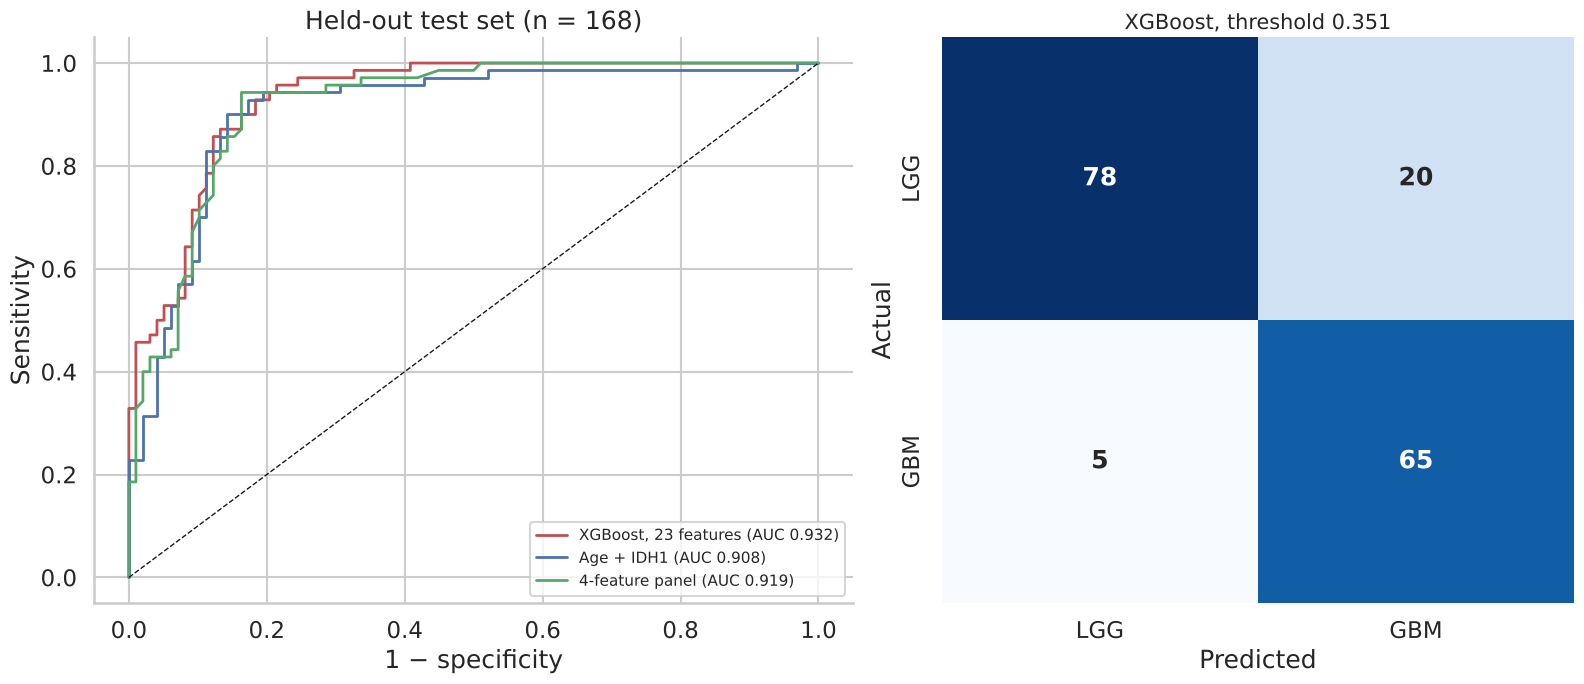

In [21]:
TEST_SET_OPENED = True
def fit_final(features, family):
    params, n_iter = SEARCH_SPACES[family]
    return RandomizedSearchCV(make_pipeline(features, family), params, n_iter=n_iter, scoring="roc_auc",
                              cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), random_state=RANDOM_STATE,
                              n_jobs=N_JOBS).fit(X_train[features], y_train)
def _final():
    m = {"primary": fit_final(ALL_FEATURES, PRIMARY_MODEL_NAME), "age_idh1": fit_final(["Age_at_diagnosis", "IDH1"], "LogisticRegression"),
         "panel4": fit_final(FOUR_FEATURE_PANEL, PRIMARY_MODEL_NAME)}
    return {k: v.best_estimator_ for k, v in m.items()} | {"best_params": {k: v.best_params_ for k, v in m.items()}}
FINAL = cache(f"final_models_{PRIMARY_MODEL_NAME}", _final, deps=[fit_final], ctx=FOUR_FEATURE_PANEL)
assert type(FINAL["primary"].named_steps["clf"]).__name__ == {"LogisticRegression": "LogisticRegression", "SVM_RBF": "SVC",
       "RandomForest": "RandomForestClassifier", "XGBoost": "XGBClassifier"}[PRIMARY_MODEL_NAME], "final model family mismatch"
print("Final primary estimator:", FINAL["primary"].named_steps["clf"]); print("Best params:", FINAL["best_params"])

y_te = y_test.values
p_primary_raw = FINAL["primary"].predict_proba(X_test[ALL_FEATURES])[:, 1]
p_primary = deploy_calibrate(p_primary_raw)
p_base = FINAL["age_idh1"].predict_proba(X_test[["Age_at_diagnosis", "IDH1"]])[:, 1]
p_panel = FINAL["panel4"].predict_proba(X_test[FOUR_FEATURE_PANEL])[:, 1]
pd.DataFrame({"test_index": idx_test, "y": y_te, "primary_raw": p_primary_raw, "primary_calibrated": p_primary,
              "age_idh1": p_base, "panel4": p_panel}).to_csv(MODEL_DIR / "test_set_predictions.csv", index=False)

test_ci = boot_ci(y_te, p_primary, OPTIMAL_THRESHOLD); test_ci.to_csv(TABLE_DIR / "Table16_FinalTestSetResults.csv", index=False)
print(test_ci.to_string(index=False))
oT = ops(y_te, p_primary, OPTIMAL_THRESHOLD); print(f"Confusion matrix at t={OPTIMAL_THRESHOLD:.3f}: TP {oT['TP']} TN {oT['TN']} FP {oT['FP']} FN {oT['FN']}")
for _, r in test_ci.iterrows():
    record(f"Test_{r.Metric}", round(r.Point_estimate, 3), "Table16", f"95% CI {r['CI_lower_2.5%']:.3f}-{r['CI_upper_97.5%']:.3f}")
for k in ["TP", "TN", "FP", "FN"]: record(f"Test_{k}", oT[k], "Table16")
nos_te = y_te.mean() * (1 - y_te.mean()); record("Test_noskill_Brier", round(nos_te, 3), "Section 20")
record("Test_Brier_reduction_pct", round((1 - brier_score_loss(y_te, p_primary) / nos_te) * 100, 0), "Section 20")

rows = []
for name, pb in [("Age + IDH1 (LR)", p_base), (f"4-feature panel ({', '.join(FOUR_FEATURE_PANEL)})", p_panel)]:
    d = delong(y_te, p_primary, pb)
    rows.append({"Comparison": f"{PRIMARY_MODEL_NAME} (23 features) vs {name}", "AUC_primary": d["auc_A"], "AUC_comparator": d["auc_B"],
                 "Pct_of_primary": d["auc_B"] / d["auc_A"] * 100, "Diff": d["diff"], "Diff_CI_lo": d["ci_lo"], "Diff_CI_hi": d["ci_hi"], "DeLong_p": d["p"]})
tcmp = pd.DataFrame(rows); tcmp.round(4).to_csv(TABLE_DIR / "Table16b_TestSetComparisons.csv", index=False); print(tcmp.round(4).to_string(index=False))
record("Test_AUC_AgeIDH1", round(tcmp.iloc[0].AUC_comparator, 3), "Table16b", f"{tcmp.iloc[0].Pct_of_primary:.1f}% of primary; p={tcmp.iloc[0].DeLong_p:.3f}")
record("Test_DeltaAUC_vs_AgeIDH1", round(tcmp.iloc[0].Diff, 3), "Table16b", f"95% CI {tcmp.iloc[0].Diff_CI_lo:+.3f} to {tcmp.iloc[0].Diff_CI_hi:+.3f}; p={tcmp.iloc[0].DeLong_p:.3f}")
record("Test_AUC_panel4", round(tcmp.iloc[1].AUC_comparator, 3), "Table16b", f"{tcmp.iloc[1].Pct_of_primary:.1f}% of primary; p={tcmp.iloc[1].DeLong_p:.3f}")
record("Test_panel4_pct_of_primary", round(tcmp.iloc[1].Pct_of_primary, 1), "Table16b")
record("Test_AgeIDH1_pct_of_primary", round(tcmp.iloc[0].Pct_of_primary, 1), "Table16b")

fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.2, 1]})
for p, lbl, c in [(p_primary, f"{PRIMARY_MODEL_NAME}, 23 features", "#C44E52"), (p_base, "Age + IDH1", "#4C72B0"),
                  (p_panel, f"4-feature panel", "#55A868")]:
    fpr, tpr, _ = roc_curve(y_te, p); axes[0].plot(fpr, tpr, color=c, lw=2, label=f"{lbl} (AUC {roc_auc_score(y_te, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set(xlabel="1 − specificity", ylabel="Sensitivity", title=f"Held-out test set (n = {N_TEST})"); axes[0].legend(loc="lower right", fontsize=11)
cmx = confusion_matrix(y_te, (p_primary >= OPTIMAL_THRESHOLD).astype(int))
sns.heatmap(cmx, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1], xticklabels=["LGG", "GBM"], yticklabels=["LGG", "GBM"], annot_kws={"size": 18, "weight": "bold"})
axes[1].set(xlabel="Predicted", ylabel="Actual"); axes[1].set_title(f"{PRIMARY_MODEL_NAME}, threshold {OPTIMAL_THRESHOLD:.3f}", fontsize=15)
savefig("Figure14_FinalTestSetEvaluation.png")

     Threshold_definition  Threshold  TP  TN  FP  FN  Sensitivity  Specificity    PPV    NPV  Accuracy    MCC
              Default 0.5      0.500  61  83  15   9       0.8714       0.8469 0.8026 0.9022    0.8571 0.7116
          Youden (locked)      0.351  65  78  20   5       0.9286       0.7959 0.7647 0.9398    0.8512 0.7144
Cost-optimal, FN:FP = 5:1      0.317  65  78  20   5       0.9286       0.7959 0.7647 0.9398    0.8512 0.7144


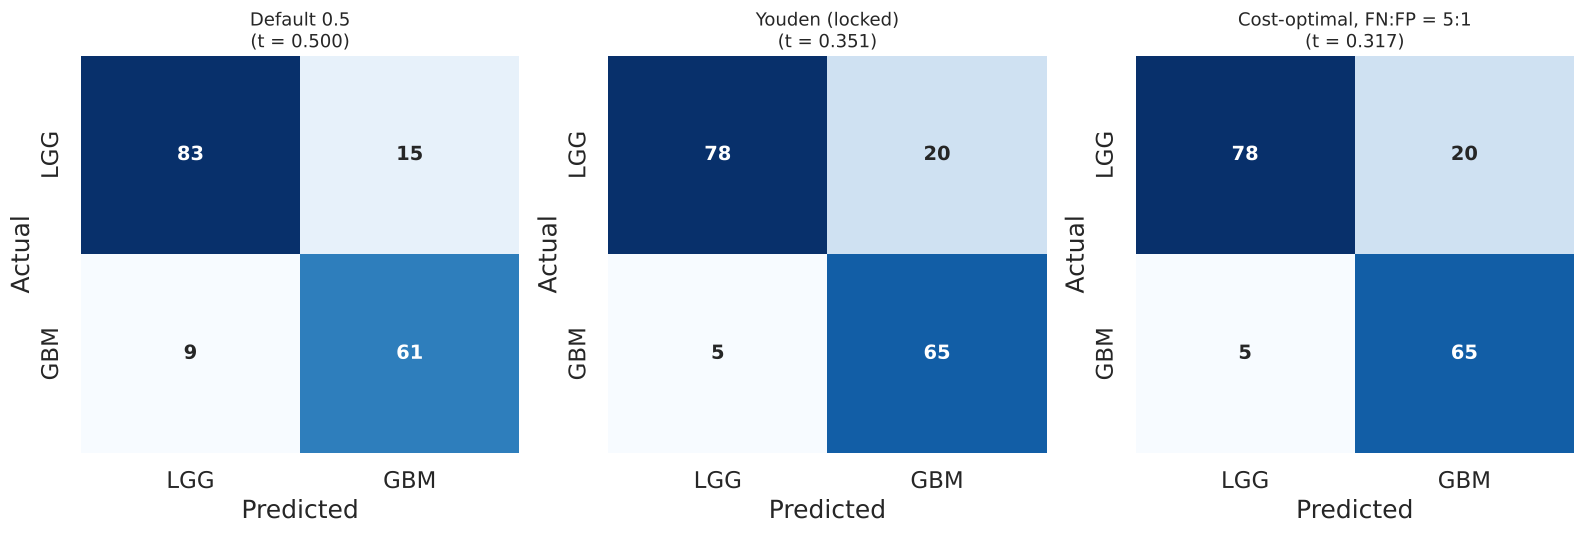

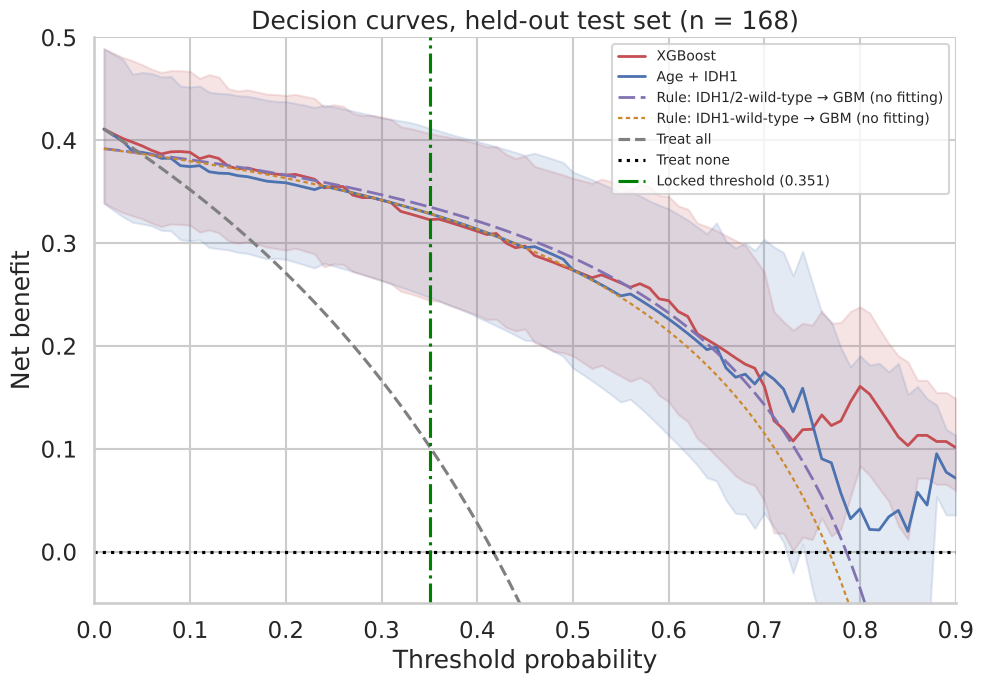

In [22]:
# 20b — Three operating points on the test set (thresholds all fixed on training data)
cost5 = float(cost.set_index("Cost_ratio_FN_per_FP").loc[5, "Cost_optimal_threshold"])
rows, cms = [], {}
for lbl, t in [("Default 0.5", 0.5), ("Youden (locked)", OPTIMAL_THRESHOLD), ("Cost-optimal, FN:FP = 5:1", cost5)]:
    oo = ops(y_te, p_primary, t); cms[f"{lbl}\n(t = {t:.3f})"] = confusion_matrix(y_te, (p_primary >= t).astype(int))
    rows.append({"Threshold_definition": lbl, "Threshold": round(t, 3), **{k: oo[k] for k in ["TP", "TN", "FP", "FN"]},
                 **{k: round(oo[k], 4) for k in ["Sensitivity", "Specificity", "PPV", "NPV", "Accuracy"]},
                 "MCC": round(matthews_corrcoef(y_te, (p_primary >= t).astype(int)), 4)})
three = pd.DataFrame(rows); three.to_csv(TABLE_DIR / "Table17_ConfusionMatrices_ThreeThresholds.csv", index=False); print(three.to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, (lbl, c) in zip(axes, cms.items()):
    sns.heatmap(c, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["LGG", "GBM"], yticklabels=["LGG", "GBM"], annot_kws={"size": 14, "weight": "bold"})
    ax.set(xlabel="Predicted", ylabel="Actual"); ax.set_title(lbl, fontsize=13)
savefig("Figure15_ThreeThresholdConfusionMatrices.png")

# 20c — Test-set decision curves (descriptive; no decision is taken from them)
nbT_p, nbT_b = net_benefit(y_te, p_primary, ts), net_benefit(y_te, p_base, ts); pv = y_te.mean(); nbT_all = pv - (1 - pv) * ts / (1 - ts)
rule1_te = (X_test.IDH1.values == 0).astype(int); rule12_te = ((X_test.IDH1.values == 0) & (X_test.IDH2.values == 0)).astype(int)
nbT_r1, nbT_r12 = net_benefit(y_te, rule1_te, ts), net_benefit(y_te, rule12_te, ts)   # R4 (RR-4); same resample indices as before
BT = np.full((1000, len(ts), 7), np.nan)
for b in range(1000):
    i = rng.randint(0, len(y_te), len(y_te))
    if len(np.unique(y_te[i])) < 2: continue
    BT[b, :, 0] = net_benefit(y_te[i], p_primary[i], ts); BT[b, :, 1] = net_benefit(y_te[i], p_base[i], ts)
    BT[b, :, 2] = BT[b, :, 0] - BT[b, :, 1]
    BT[b, :, 3] = net_benefit(y_te[i], rule1_te[i], ts); BT[b, :, 4] = net_benefit(y_te[i], rule12_te[i], ts)
    BT[b, :, 5] = BT[b, :, 0] - BT[b, :, 3]; BT[b, :, 6] = BT[b, :, 0] - BT[b, :, 4]
loT, hiT = np.nanpercentile(BT, 2.5, 0), np.nanpercentile(BT, 97.5, 0)
dcaT = pd.DataFrame({"Threshold": ts, "Primary_NB": nbT_p, "Primary_lo": loT[:, 0], "Primary_hi": hiT[:, 0], "AgeIDH1_NB": nbT_b,
              "AgeIDH1_lo": loT[:, 1], "AgeIDH1_hi": hiT[:, 1], "Delta_NB": nbT_p - nbT_b, "Delta_NB_lo": loT[:, 2],
              "Delta_NB_hi": hiT[:, 2], "TreatAll_NB": nbT_all,
              "RuleIDH1_NB": nbT_r1, "RuleIDH1_lo": loT[:, 3], "RuleIDH1_hi": hiT[:, 3],
              "RuleIDH12_NB": nbT_r12, "RuleIDH12_lo": loT[:, 4], "RuleIDH12_hi": hiT[:, 4],
              "Delta_NB_vs_RuleIDH1": nbT_p - nbT_r1, "Delta_NB_vs_RuleIDH1_lo": loT[:, 5], "Delta_NB_vs_RuleIDH1_hi": hiT[:, 5],
              "Delta_NB_vs_RuleIDH12": nbT_p - nbT_r12, "Delta_NB_vs_RuleIDH12_lo": loT[:, 6], "Delta_NB_vs_RuleIDH12_hi": hiT[:, 6]})
dcaT.round(4).to_csv(TABLE_DIR / "Table11b_TestSetDCA.csv", index=False)
_r = dcaT.loc[(dcaT.Threshold - round(OPTIMAL_THRESHOLD, 2)).abs().idxmin()]
record("DCA_test_NB_primary_at_tau", round(_r.Primary_NB, 3), "Table11b", f"Age+IDH1 {_r.AgeIDH1_NB:.3f}; treat-all {_r.TreatAll_NB:.3f}; threshold {_r.Threshold:.2f}")
record("DCA_test_DeltaNB_at_tau", round(_r.Delta_NB, 3), "Table11b", f"95% CI {_r.Delta_NB_lo:.3f} to {_r.Delta_NB_hi:.3f}")
record("DCA_test_n_thresholds_DeltaNB_CI_excl_0", int((dcaT.Delta_NB_lo > 0).sum()), "Table11b")
record("DCA_test_NB_AgeIDH1_at_tau", round(_r.AgeIDH1_NB, 3), "Table11b", f"threshold {_r.Threshold:.2f}; 95% CI {_r.AgeIDH1_lo:.3f} to {_r.AgeIDH1_hi:.3f}")
for _k, _c in [("ruleIDH1", "RuleIDH1"), ("ruleIDH12", "RuleIDH12")]:
    record(f"DCA_test_NB_{_k}_at_tau", round(_r[f"{_c}_NB"], 3), "Table11b", f"threshold {_r.Threshold:.2f}; 95% CI {_r[f'{_c}_lo']:.3f} to {_r[f'{_c}_hi']:.3f}")
    record(f"DCA_test_DeltaNB_model_minus_{_k}_at_tau", round(_r[f"Delta_NB_vs_{_c}"], 3), "Table11b",
           f"threshold {_r.Threshold:.2f}; paired bootstrap 95% CI {_r[f'Delta_NB_vs_{_c}_lo']:.3f} to {_r[f'Delta_NB_vs_{_c}_hi']:.3f}")
    _w = dcaT[(dcaT.Threshold >= 0.30) & (dcaT.Threshold <= 0.50)]
    record(f"DCA_test_n_thresholds_0.30-0.50_rule_NB_ge_model_{_k}", int((_w[f"{_c}_NB"] >= _w.Primary_NB - 1e-12).sum()), "Table11b", f"of {len(_w)} grid points")
fig, ax = plt.subplots(figsize=(10, 7))
ax.plot(ts, nbT_p, color="#C44E52", lw=2, label=PRIMARY_MODEL_NAME); ax.fill_between(ts, loT[:, 0], hiT[:, 0], color="#C44E52", alpha=.15)
ax.plot(ts, nbT_b, color="#4C72B0", lw=2, label="Age + IDH1"); ax.fill_between(ts, loT[:, 1], hiT[:, 1], color="#4C72B0", alpha=.15)
ax.plot(ts, nbT_r12, color="#8172B2", lw=2, ls=(0, (6, 2)), label="Rule: IDH1/2-wild-type → GBM (no fitting)")
ax.plot(ts, nbT_r1, color="#CC8A2E", lw=1.6, ls=(0, (2, 1.5)), label="Rule: IDH1-wild-type → GBM (no fitting)")
ax.plot(ts, nbT_all, color="grey", ls="--", label="Treat all"); ax.axhline(0, color="black", ls=":", label="Treat none")
ax.axvline(OPTIMAL_THRESHOLD, color="green", ls="-.", label=f"Locked threshold ({OPTIMAL_THRESHOLD:.3f})")
ax.set(xlim=(0, .9), ylim=(-.05, .5), xlabel="Threshold probability", ylabel="Net benefit", title=f"Decision curves, held-out test set (n = {N_TEST})"); ax.legend(fontsize=10, loc="upper right")
savefig("Figure16_TestSetDCA.png")

           Attribute                                    Group   N  N_GBM  N_LGG  Accuracy  Errors            AUC      AUC_CI  Sensitivity  Specificity                     Note                                                                                                                                                      Interpretation_note
                 Sex                                     Male  90     39     51     0.833      15          0.918 0.859-0.970        0.897        0.784                      NaN                                                                                                                                                                         
                 Sex                                   Female  78     31     47     0.872      10          0.947 0.897-0.983        0.968        0.809                      NaN                                                                                                                                       

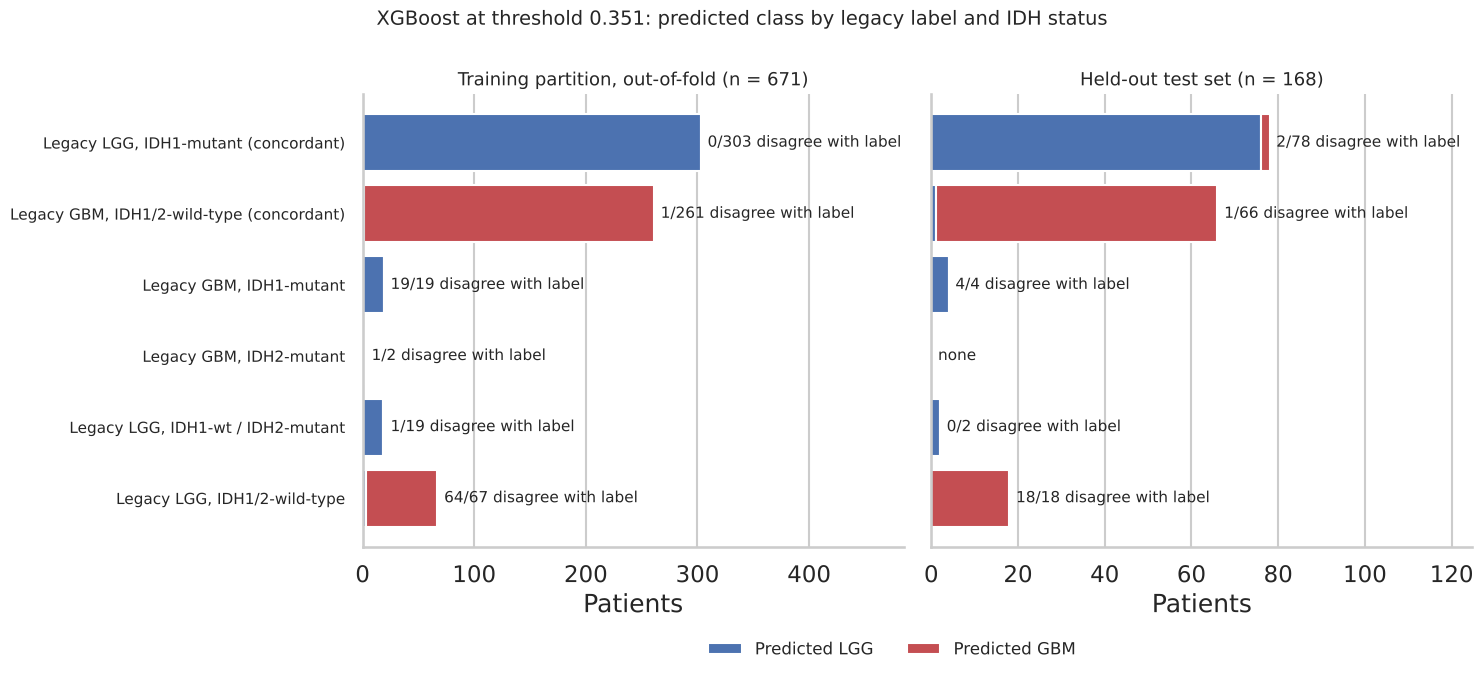

         Set                    Predictor   AUC  Sensitivity  Specificity  Accuracy  Errors  DeltaAUC_model_minus_rule  CI_lo  CI_hi  DeLong_p
Training OOF                 Locked model 0.910        0.926        0.833     0.872      86                        NaN    NaN    NaN       NaN
Training OOF   Rule: IDH1-wildtype -> GBM 0.856        0.933        0.779     0.844     105                      0.055  0.037  0.072       0.0
Training OOF Rule: IDH1/2-wildtype -> GBM 0.877        0.926        0.828     0.869      88                      0.034  0.020  0.048       0.0
 Sealed test                 Locked model 0.932        0.929        0.796     0.851      25                        NaN    NaN    NaN       NaN
 Sealed test   Rule: IDH1-wildtype -> GBM 0.869        0.943        0.796     0.857      24                      0.062  0.031  0.094       0.0
 Sealed test Rule: IDH1/2-wildtype -> GBM 0.880        0.943        0.816     0.869      22                      0.052  0.023  0.081       0.0

In [23]:
# 20d — Subgroups on the test set: sex, race, and agreement of the legacy label with IDH1 status
te_prov = prov.loc[idx_test].reset_index(drop=True)
MIN_PER_CLASS = 10
def sub_rows(attr, mask_dict):
    out = []
    for lbl, m in mask_dict.items():
        m = np.asarray(m); yg, pg = y_te[m], p_primary[m]; npos, nneg = int(yg.sum()), int((1 - yg).sum())
        oo = ops(yg, pg, OPTIMAL_THRESHOLD)
        row = {"Attribute": attr, "Group": lbl, "N": int(m.sum()), "N_GBM": npos, "N_LGG": nneg, "Accuracy": round(oo["Accuracy"], 3),
               "Errors": oo["FP"] + oo["FN"]}
        if npos >= MIN_PER_CLASS and nneg >= MIN_PER_CLASS:
            bs = []
            for _ in range(1000):
                i = rng.randint(0, len(yg), len(yg))
                if len(np.unique(yg[i])) > 1: bs.append(roc_auc_score(yg[i], pg[i]))
            row.update({"AUC": round(roc_auc_score(yg, pg), 3), "AUC_CI": f"{np.percentile(bs, 2.5):.3f}-{np.percentile(bs, 97.5):.3f}",
                        "Sensitivity": round(oo["Sensitivity"], 3), "Specificity": round(oo["Specificity"], 3)})
        else:
            row.update({"AUC": "not reportable", "Note": f"< {MIN_PER_CLASS} patients in a class"})
        out.append(row)
    return out
rows = sub_rows("Sex", {"Male": te_prov.Gender == 0, "Female": te_prov.Gender == 1})
rows += sub_rows("Race", {n: te_prov.Race == k for k, n in {0: "White", 1: "Black/African American", 2: "Asian", 3: "Am. Indian/Alaska Native"}.items() if (te_prov.Race == k).any()})
rows += sub_rows("Legacy label vs IDH1", {"Concordant (LGG/IDH1-mut or GBM/IDH1-wt)": ~te_prov.IDH1_discordant,
                                         "Discordant (LGG/IDH1-wt or GBM/IDH1-mut)": te_prov.IDH1_discordant})
subg = pd.DataFrame(rows)
# R4 (RR-5 / R1 W8 / DA m3): the concordance strata are defined jointly by the outcome and the dominant predictor
subg["Interpretation_note"] = np.where(subg.Group.str.startswith("Concordant"),
    "Tautological: stratum defined by agreement of the label with IDH1, the dominant predictor; an AUC near 1 is guaranteed by construction and is not a performance estimate",
    np.where(subg.Group.str.startswith("Discordant"), "Stratum defined by disagreement of the label with IDH1; low accuracy is expected by construction", ""))
subg.to_csv(TABLE_DIR / "Table21_SubgroupPerformance.csv", index=False); print(subg.to_string(index=False))
n_err = int(subg.loc[subg.Attribute == "Legacy label vs IDH1", "Errors"].sum())
disc_err = int(subg.loc[subg.Group.str.startswith("Discordant"), "Errors"].iloc[0]); disc_n = int(subg.loc[subg.Group.str.startswith("Discordant"), "N"].iloc[0])
print(f"\n{disc_err} of {n_err} test-set errors ({disc_err/n_err*100:.0f}%) occur in the {disc_n} IDH1-discordant patients "
      f"({disc_n/N_TEST*100:.0f}% of the test set).")
record("Test_discordant_n", disc_n, "Table21"); record("Test_errors_total", n_err, "Table21")
record("Test_errors_in_discordant", disc_err, "Table21", f"{disc_err/n_err*100:.0f}% of errors")
for _, r in subg.iterrows():
    record(f"Subgroup_{r.Group[:20]}_N", int(r.N), "Table21", f"AUC {r.AUC}")

# Development-level (n = 671, out-of-fold) version of the same analysis, and the accuracy ceiling implied by label-IDH discordance
tr_prov = prov.loc[idx_train].reset_index(drop=True); disc_tr = tr_prov.IDH1_discordant.values
pred_tr = (primary_proba_final >= OPTIMAL_THRESHOLD).astype(int); err_tr = pred_tr != y_arr
dev_rows = []
for lbl, m in [("Concordant", ~disc_tr), ("Discordant", disc_tr), ("All", np.ones_like(disc_tr, bool))]:
    dev_rows.append({"Set": "Training OOF", "Group": lbl, "N": int(m.sum()), "Errors": int(err_tr[m].sum()), "Accuracy": round(1 - err_tr[m].mean(), 3)})
for lbl, m in [("Concordant", ~te_prov.IDH1_discordant.values), ("Discordant", te_prov.IDH1_discordant.values), ("All", np.ones(N_TEST, bool))]:
    e = (p_primary >= OPTIMAL_THRESHOLD).astype(int) != y_te
    dev_rows.append({"Set": "Sealed test", "Group": lbl, "N": int(m.sum()), "Errors": int(e[m].sum()), "Accuracy": round(1 - e[m].mean(), 3)})
disc_tab = pd.DataFrame(dev_rows); disc_tab.to_csv(TABLE_DIR / "Table30_ErrorsByLabelIDHConcordance.csv", index=False); print(disc_tab.to_string(index=False))
frac_disc = prov.IDH1_discordant.mean(); idh_rule_acc = 1 - frac_disc
idh12_disc = (((prov.Grade == 1) & idh_mut) | ((prov.Grade == 0) & ~idh_mut)).mean()
print(f"\nWhole cohort: {prov.IDH1_discordant.sum()} of {N_ANALYSIS} ({frac_disc*100:.1f}%) legacy labels disagree with IDH1 status "
      f"-> accuracy of the IDH1 rule = {idh_rule_acc*100:.1f}%; using IDH1 or IDH2: {idh12_disc*100:.1f}% discordant.")
dv = disc_tab[(disc_tab.Set == "Training OOF")].set_index("Group")
record("Cohort_IDH1_discordant_n", int(prov.IDH1_discordant.sum()), "Section 20d", f"{frac_disc*100:.1f}% of cohort")
record("Cohort_IDH12_discordant_pct", round(idh12_disc * 100, 1), "Section 20d")
record("IDH1_rule_accuracy_ceiling_pct", round(idh_rule_acc * 100, 1), "Section 20d")
record("Dev_errors_in_discordant", int(dv.loc["Discordant", "Errors"]), "Table30", f"of {int(dv.loc['All', 'Errors'])} OOF errors; discordant n={int(dv.loc['Discordant', 'N'])}")
record("Dev_accuracy_concordant", dv.loc["Concordant", "Accuracy"], "Table30"); record("Dev_accuracy_discordant", dv.loc["Discordant", "Accuracy"], "Table30")

# Table 31 / Figure 18 — predictions by WHO 2021 audit category: does the model side with the legacy label or with IDH status?
SHORT = {"Concordant LGG": "Legacy LGG, IDH1-mutant (concordant)", "Concordant GBM": "Legacy GBM, IDH1/2-wild-type (concordant)",
         "A": "Legacy GBM, IDH1-mutant", "B": "Legacy GBM, IDH2-mutant", "C": "Legacy LGG, IDH1-wt / IDH2-mutant",
         "D": "Legacy LGG, IDH1/2-wild-type"}
def short_cat(r):
    c = r.WHO2021_audit_category
    if c is None or (isinstance(c, float) and np.isnan(c)):
        return SHORT["Concordant GBM"] if r.Grade == 1 else SHORT["Concordant LGG"]
    return {"Legacy GBM, IDH1": SHORT["A"], "Legacy GBM, IDH2": SHORT["B"], "Legacy LGG, IDH1-wild-type but": SHORT["C"],
            "Legacy LGG, IDH1/2": SHORT["D"]}[next(k for k in ["Legacy GBM, IDH1", "Legacy GBM, IDH2", "Legacy LGG, IDH1-wild-type but", "Legacy LGG, IDH1/2"] if c.startswith(k))]
cat_rows = []
for setname, P, prov_ in [("Training OOF", primary_proba_final, tr_prov), ("Sealed test", p_primary, te_prov)]:
    cats = prov_.apply(short_cat, axis=1).values; pred = (P >= OPTIMAL_THRESHOLD).astype(int); yy = prov_.Grade.values
    idh = ((prov_.IDH1 == 1) | (prov_.IDH2 == 1)).values
    for c in SHORT.values():
        m = cats == c
        if not m.any(): continue
        cat_rows.append({"Set": setname, "Category": c, "N": int(m.sum()), "Predicted_GBM": int(pred[m].sum()),
                         "Predicted_LGG": int((1 - pred[m]).sum()), "Errors_vs_legacy_label": int((pred[m] != yy[m]).sum()),
                         "Prediction_agrees_with_IDH_status": int((pred[m] == (~idh[m]).astype(int)).sum())})
cat_tab = pd.DataFrame(cat_rows); cat_tab.to_csv(TABLE_DIR / "Table31_PredictionsByWHOAuditCategory.csv", index=False); print(cat_tab.to_string(index=False))
for setname, tag in [("Training OOF", "Dev"), ("Sealed test", "Test")]:
    ct = cat_tab[cat_tab.Set == setname].set_index("Category")
    disc_cats = [SHORT["A"], SHORT["C"], SHORT["D"]]
    err_idh_dir = sum(int(ct.loc[c, "Errors_vs_legacy_label"]) for c in [SHORT["A"], SHORT["D"]] if c in ct.index)
    record(f"{tag}_errors_IDH_direction", err_idh_dir, "Table31", "errors in IDH1-mutant legacy GBM + IDH1/2-wt legacy LGG (prediction follows IDH status)")
    for key, c in [("A", SHORT["A"]), ("C", SHORT["C"]), ("D", SHORT["D"])]:
        if c in ct.index:
            record(f"{tag}_cat{key}_n", int(ct.loc[c, "N"]), "Table31", f"predicted GBM {int(ct.loc[c, 'Predicted_GBM'])}; errors {int(ct.loc[c, 'Errors_vs_legacy_label'])}")
            record(f"{tag}_cat{key}_predGBM", int(ct.loc[c, "Predicted_GBM"]), "Table31")
    conc = ct.loc[[SHORT["Concordant LGG"], SHORT["Concordant GBM"]]]
    record(f"{tag}_concordant_n", int(conc.N.sum()), "Table31", f"errors {int(conc.Errors_vs_legacy_label.sum())}")
    record(f"{tag}_concordant_errors", int(conc.Errors_vs_legacy_label.sum()), "Table31")
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), sharey=True)
axes[0].invert_yaxis()
order = [SHORT[k] for k in ["Concordant LGG", "Concordant GBM", "A", "B", "C", "D"]]
for ax, setname in zip(axes, ["Training OOF", "Sealed test"]):
    ct = cat_tab[cat_tab.Set == setname].set_index("Category").reindex(order).fillna(0)
    yy_ = np.arange(len(order))
    ax.barh(yy_, ct.Predicted_LGG, color="#4C72B0", label="Predicted LGG")
    ax.barh(yy_, ct.Predicted_GBM, left=ct.Predicted_LGG, color="#C44E52", label="Predicted GBM")
    for i, c in enumerate(order):
        n = int(ct.loc[c, "N"]); e = int(ct.loc[c, "Errors_vs_legacy_label"])
        ax.text(n + max(ct.N) * 0.02, i, f"{e}/{n} disagree with label" if n else "none", va="center", fontsize=11)
    ax.set_yticks(yy_); ax.set_yticklabels(order, fontsize=11); ax.set_xlabel("Patients"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(ct.N) * 1.6)
    ax.set_title(f"Training partition, out-of-fold (n = {N_TRAIN})" if setname == "Training OOF" else f"Held-out test set (n = {N_TEST})", fontsize=13)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, fontsize=12, frameon=False, bbox_to_anchor=(0.6, -0.06))
plt.suptitle(f"{PRIMARY_MODEL_NAME} at threshold {OPTIMAL_THRESHOLD:.3f}: predicted class by legacy label and IDH status", y=1.01, fontsize=14)
savefig("Figure18_ErrorsByLabelIDHConcordance.png")

# 20e — No-fit IDH rules as comparators, IDH1/2-based concordance, and EGFR within IDH-wildtype tumours
rule_rows = []
for setname, P, prov_ in [("Training OOF", primary_proba_final, tr_prov), ("Sealed test", p_primary, te_prov)]:
    yy = prov_.Grade.values; r1 = (prov_.IDH1 == 0).astype(int).values; r12 = ((prov_.IDH1 == 0) & (prov_.IDH2 == 0)).astype(int).values
    for name, score, thr in [("Locked model", P, OPTIMAL_THRESHOLD), ("Rule: IDH1-wildtype -> GBM", r1, 0.5), ("Rule: IDH1/2-wildtype -> GBM", r12, 0.5)]:
        o = ops(yy, score, thr); d = delong(yy, P, score) if name != "Locked model" else None
        rule_rows.append({"Set": setname, "Predictor": name, "AUC": roc_auc_score(yy, score), "Sensitivity": o["Sensitivity"], "Specificity": o["Specificity"],
                          "Accuracy": o["Accuracy"], "Errors": o["FP"] + o["FN"], "DeltaAUC_model_minus_rule": np.nan if d is None else d["diff"],
                          "CI_lo": np.nan if d is None else d["ci_lo"], "CI_hi": np.nan if d is None else d["ci_hi"], "DeLong_p": np.nan if d is None else d["p"]})
rules = pd.DataFrame(rule_rows); rules.round(4).to_csv(TABLE_DIR / "Table32_IDHRulesVsModel.csv", index=False); print(rules.round(3).to_string(index=False))
for _, r in rules.iterrows():
    tag = ("Dev" if r.Set == "Training OOF" else "Test") + "_" + {"Locked model": "model", "Rule: IDH1-wildtype -> GBM": "ruleIDH1", "Rule: IDH1/2-wildtype -> GBM": "ruleIDH12"}[r.Predictor]
    record(f"{tag}_acc", round(r.Accuracy, 3), "Table32", f"sens {r.Sensitivity:.3f}; spec {r.Specificity:.3f}; errors {int(r.Errors)}; AUC {r.AUC:.3f}")
    record(f"{tag}_sens", round(r.Sensitivity, 3), "Table32"); record(f"{tag}_spec", round(r.Specificity, 3), "Table32")
    record(f"{tag}_errors", int(r.Errors), "Table32"); record(f"{tag}_AUC", round(r.AUC, 3), "Table32")
    if not pd.isna(r.DeLong_p):
        record(f"{tag}_DeltaAUC_vs_model", round(r.DeltaAUC_model_minus_rule, 3), "Table32", f"95% CI {r.CI_lo:.3f} to {r.CI_hi:.3f}; p={r.DeLong_p:.2g}")
        record(f"{tag}_DeLong_p", float(f"{r.DeLong_p:.2g}"), "Table32")

idh12_rows = []
for setname, P, prov_ in [("Training OOF", primary_proba_final, tr_prov), ("Sealed test", p_primary, te_prov)]:
    yy = prov_.Grade.values; idh = ((prov_.IDH1 == 1) | (prov_.IDH2 == 1)).values
    disc = ((yy == 1) & idh) | ((yy == 0) & ~idh); pred = (P >= OPTIMAL_THRESHOLD).astype(int); err = pred != yy
    follows_idh = pred == (~idh).astype(int)
    for lbl, m in [("Concordant", ~disc), ("Discordant", disc)]:
        idh12_rows.append({"Set": setname, "Group": lbl, "N": int(m.sum()), "Errors": int(err[m].sum()), "Accuracy": round(1 - err[m].mean(), 3),
                           "Errors_where_prediction_follows_IDH": int((err & follows_idh)[m].sum())})
idh12 = pd.DataFrame(idh12_rows); idh12.to_csv(TABLE_DIR / "Table30b_ErrorsByLabelIDH12Concordance.csv", index=False); print(idh12.to_string(index=False))
for _, r in idh12.iterrows():
    tag = ("Dev" if r.Set == "Training OOF" else "Test") + ("_IDH12conc" if r.Group == "Concordant" else "_IDH12disc")
    record(f"{tag}_n", int(r.N), "Table30b", f"errors {r.Errors}; accuracy {r.Accuracy}; errors following IDH status {r.Errors_where_prediction_follows_IDH}")
    record(f"{tag}_errors", int(r.Errors), "Table30b"); record(f"{tag}_acc", r.Accuracy, "Table30b")
record("Dev_errors_follow_IDH12", int(idh12[idh12.Set == "Training OOF"].Errors_where_prediction_follows_IDH.sum()), "Table30b")
record("Test_errors_follow_IDH12", int(idh12[idh12.Set == "Sealed test"].Errors_where_prediction_follows_IDH.sum()), "Table30b")
record("IDH12_rule_accuracy_ceiling_pct", round(100 - idh12_disc * 100, 1), "Section 20d")
record("Cohort_IDH12_discordant_n", int((((prov.Grade == 1) & idh_mut) | ((prov.Grade == 0) & ~idh_mut)).sum()), "Section 20d")

wt = prov[(prov.IDH1 == 0) & (prov.IDH2 == 0)]
for g in ["EGFR", "PTEN", "NF1", "TP53"]:
    a = wt[wt.Grade == 0][g]; b = wt[wt.Grade == 1][g]
    record(f"IDHwt_{g}_LGG_pct", round(a.mean() * 100, 1), "Section 20e", f"{int(a.sum())}/{len(a)} legacy LGG vs {int(b.sum())}/{len(b)} legacy GBM ({b.mean()*100:.1f}%), IDH1/2-wildtype only")
    record(f"IDHwt_{g}_GBM_pct", round(b.mean() * 100, 1), "Section 20e")

## Section 20f — Post hoc reconstruction of WHO 2021 categories from published TCGA molecular annotations
Ceccarelli et al. (Cell 2016; cBioPortal study lgggbm_tcga_pub) report 1p/19q status, combined chromosome 7 gain / 10 loss, TERT promoter status and GISTIC copy-number calls for TCGA LGG/GBM. Linking by case identifier gives an approximate WHO 2021 category for most patients. This analysis is descriptive and does not feed back into any locked decision.

In [24]:
ann = pd.read_csv(DATA_DIR / "External" / "Ceccarelli2016_molecular_annotations.csv")
cna = pd.read_csv(DATA_DIR / "External" / "Ceccarelli2016_GISTIC_EGFR_CDKN2AB.csv")
mol = prov[["Case_ID", "Grade", "IDH1", "IDH2"]].merge(ann, left_on="Case_ID", right_on="PATIENT_ID", how="left").merge(cna, on="PATIENT_ID", how="left")
assert len(mol) == N_ANALYSIS
mol["idh_mut"] = (mol.IDH1 == 1) | (mol.IDH2 == 1)
def who2021(r):
    # returns (category, CNS WHO grade 4: 1/0/NaN, glioblastoma IDH-wildtype: 1/0/NaN). H3 status is not available (rare in adults).
    if r.idh_mut:
        if r.IDH_1P19Q_SUBTYPE == "Codel": return "Oligodendroglioma, IDH-mutant, 1p/19q-codeleted", 0, 0
        if pd.isna(r.IDH_1P19Q_SUBTYPE): return "IDH-mutant, 1p/19q unknown", np.nan, 0
        cdkn = (r.CDKN2A == -2) or (r.CDKN2B == -2)
        if r.Grade == 1 or cdkn: return "Astrocytoma, IDH-mutant, grade 4", 1, 0
        if pd.isna(r.CDKN2A): return "Astrocytoma, IDH-mutant, grade not assignable", np.nan, 0
        return "Astrocytoma, IDH-mutant, grade 2-3", 0, 0
    tert = r.TERT_PROMOTER_STATUS == "Mutant"; egfr = r.EGFR == 2; c710 = r.CHR_7_GAIN_CHR_10_LOSS == "Gain chr 7 & loss chr 10"
    if r.Grade == 1: return "Glioblastoma, IDH-wildtype (histological criteria)", 1, 1
    if tert or egfr or c710: return "Glioblastoma, IDH-wildtype (molecular criteria)", 1, 1
    if (not pd.isna(r.EGFR)) and (not pd.isna(r.CHR_7_GAIN_CHR_10_LOSS)) and r.TERT_PROMOTER_STATUS == "WT":
        return "IDH-wildtype, glioblastoma criteria not met", 0, 0
    return "IDH-wildtype, glioblastoma status not assessable (TERT unknown)", np.nan, np.nan
mol[["WHO2021_reconstructed", "WHO_grade4", "WHO_GBM_IDHwt"]] = mol.apply(lambda r: pd.Series(who2021(r)), axis=1)
mol["Primary_Diagnosis"] = prov.Primary_Diagnosis.values
molgbm = mol[mol.WHO2021_reconstructed == "Glioblastoma, IDH-wildtype (molecular criteria)"].Primary_Diagnosis.value_counts()
print(molgbm)
record("WHO_molGBM_oligo_or_mixed_histology_n", int(molgbm[[k for k in molgbm.index if ("Oligodendroglioma" in k) or ("Mixed" in k)]].sum()), "Table33", "; ".join(f"{k}: {v}" for k, v in molgbm.items()))
mol.drop(columns=["PATIENT_ID"]).to_csv(DATA_DIR / "WHO2021_Reconstruction_PatientLevel.csv", index=False)
recon = pd.crosstab(mol.WHO2021_reconstructed, mol.Grade.map({0: "Legacy LGG", 1: "Legacy GBM"}), margins=True)
recon.to_csv(TABLE_DIR / "Table33_WHO2021_Reconstruction.csv"); print(recon)
record("WHO_annotated_n", int(mol.IDH_1P19Q_SUBTYPE.notna().sum()), "Table33", "patients with 1p/19q status (field used for classification)")
record("WHO_grade4_known_n", int(mol.WHO_grade4.notna().sum()), "Table33")
record("WHO_GBMwt_known_n", int(mol.WHO_GBM_IDHwt.notna().sum()), "Table33")
idh_agree = mol.IDH_STATUS.notna()
record("IDH_status_agreement_pct", round(((mol.IDH_STATUS == "Mutant") == mol.idh_mut)[idh_agree].mean() * 100, 1), "Table33", f"mutation calls vs Ceccarelli IDH status, n={int(idh_agree.sum())}")
for (k, g), v in pd.crosstab(mol.WHO2021_reconstructed, mol.Grade).stack().items():
    record(f"WHO_cat_{k[:40]}_{'GBM' if g == 1 else 'LGG'}", int(v), "Table33")
for tgt in ["WHO_grade4", "WHO_GBM_IDHwt"]:
    m = mol[tgt].notna()
    record(f"Legacy_vs_{tgt}_agreement_pct", round((mol.loc[m, tgt] == mol.loc[m, "Grade"]).mean() * 100, 1), "Table34", f"n={int(m.sum())}")
    record(f"Legacy_vs_{tgt}_n", int(m.sum()), "Table34")
mol["prob"] = np.nan; mol["set"] = ""
mol.loc[idx_train, "prob"] = primary_proba_final; mol.loc[idx_train, "set"] = "Training OOF"
mol.loc[idx_test, "prob"] = p_primary; mol.loc[idx_test, "set"] = "Sealed test"
mol["pred"] = (mol.prob >= OPTIMAL_THRESHOLD).astype(int)
mol["rule12"] = (~mol.idh_mut).astype(int)
ev = []
for setname in ["Training OOF", "Sealed test"]:
    for tgt, nm in [("Grade", "Legacy label"), ("WHO_grade4", "WHO 2021 CNS grade 4"), ("WHO_GBM_IDHwt", "WHO 2021 glioblastoma, IDH-wildtype")]:
        m = (mol.set == setname) & mol[tgt].notna(); yy = mol.loc[m, tgt].astype(int).values; pp = mol.loc[m, "prob"].values
        o = ops(yy, pp, OPTIMAL_THRESHOLD); orl = ops(yy, mol.loc[m, "rule12"].values, 0.5)
        ev.append({"Set": setname, "Target": nm, "N": int(m.sum()), "N_positive": int(yy.sum()), "AUC": roc_auc_score(yy, pp),
                   "Accuracy": o["Accuracy"], "Sensitivity": o["Sensitivity"], "Specificity": o["Specificity"], "Errors": o["FP"] + o["FN"],
                   "IDH12_rule_accuracy": orl["Accuracy"], "IDH12_rule_errors": orl["FP"] + orl["FN"]})
ev = pd.DataFrame(ev); ev.round(4).to_csv(TABLE_DIR / "Table34_ModelVsReconstructedWHO2021.csv", index=False); print(ev.round(3).to_string(index=False))
for _, r in ev.iterrows():
    tag = ("Dev" if r.Set == "Training OOF" else "Test") + "_" + {"Legacy label": "legacy", "WHO 2021 CNS grade 4": "grade4", "WHO 2021 glioblastoma, IDH-wildtype": "GBMwt"}[r.Target]
    record(f"{tag}_n", int(r.N), "Table34", f"positives {r.N_positive}; AUC {r.AUC:.3f}; acc {r.Accuracy:.3f}; sens {r.Sensitivity:.3f}; spec {r.Specificity:.3f}; errors {r.Errors}")
    for k in ["AUC", "Accuracy", "Sensitivity", "Specificity", "IDH12_rule_accuracy"]:
        record(f"{tag}_{k}", round(r[k], 3), "Table34")
    record(f"{tag}_errors", int(r.Errors), "Table34"); record(f"{tag}_rule_errors", int(r.IDH12_rule_errors), "Table34")
for setname, tag in [("Training OOF", "Dev"), ("Sealed test", "Test")]:
    m = mol.set == setname; err = m & (mol.pred != mol.Grade)
    for tgt, nm in [("WHO_GBM_IDHwt", "GBMwt"), ("WHO_grade4", "grade4")]:
        known = err & mol[tgt].notna(); fixed = known & (mol.pred == mol[tgt])
        record(f"{tag}_legacy_errors_correct_for_{nm}", int(fixed.sum()), "Table34", f"of {int(known.sum())} legacy-label errors with a reconstructed label ({int(err.sum())} errors in total)")
        record(f"{tag}_legacy_errors_known_{nm}", int(known.sum()), "Table34")
cat_pred = []
for (cat_, setname), g in mol[mol.set != ""].groupby(["WHO2021_reconstructed", "set"]):
    cat_pred.append({"Category": cat_, "Set": setname, "Legacy_LGG": int((g.Grade == 0).sum()), "Legacy_GBM": int((g.Grade == 1).sum()),
                     "N": len(g), "Predicted_GBM": int(g.pred.sum())})
cat_pred = pd.DataFrame(cat_pred); cat_pred.to_csv(TABLE_DIR / "Table33b_PredictionsByReconstructedCategory.csv", index=False); print(cat_pred.to_string(index=False))
for _, r in cat_pred.iterrows():
    record(f"{'Dev' if r.Set == 'Training OOF' else 'Test'}_predGBM_{r.Category[:40]}", f"{r.Predicted_GBM}/{r.N}", "Table33b")

Primary_Diagnosis
Astrocytoma, anaplastic          42
Mixed glioma                     13
Oligodendroglioma, anaplastic     6
Oligodendroglioma, NOS            5
Astrocytoma, NOS                  2
Name: count, dtype: int64
Grade                                               Legacy GBM  Legacy LGG  \
WHO2021_reconstructed                                                        
Astrocytoma, IDH-mutant, grade 2-3                           0         224   
Astrocytoma, IDH-mutant, grade 4                            23          15   
Astrocytoma, IDH-mutant, grade not assignable                0           1   
Glioblastoma, IDH-wildtype (histological criteria)         327           0   
Glioblastoma, IDH-wildtype (molecular criteria)              0          68   
IDH-mutant, 1p/19q unknown                                   2           0   
IDH-wildtype, glioblastoma criteria not met                  0           8   
IDH-wildtype, glioblastoma status not assessabl...           0           9

         Set                              Target   N  N_positive   AUC  Accuracy  Sensitivity  Specificity  Errors  IDH12_rule_accuracy  IDH12_rule_errors
Training OOF                        Legacy label 671         282 0.910     0.872        0.926        0.833      86                0.869                 88
Training OOF                WHO 2021 CNS grade 4 661         348 0.962     0.938        0.899        0.981      41                0.939                 40
Training OOF WHO 2021 glioblastoma, IDH-wildtype 663         314 0.996     0.986        0.994        0.980       9                0.991                  6
 Sealed test                        Legacy label 168          70 0.932     0.851        0.929        0.796      25                0.869                 22
 Sealed test                WHO 2021 CNS grade 4 166          85 0.995     0.958        0.953        0.963       7                0.964                  6
 Sealed test WHO 2021 glioblastoma, IDH-wildtype 167          81 0.999

## Section 20g — Post hoc (R4, RR-4): paired operating-point comparison of the locked model with the no-fit IDH rules
*Specified before this code was run. Descriptive; no locked decision depends on it.*

A binary rule's AUC equals (sensitivity + specificity)/2, so a DeLong test against a continuous score mainly reflects that the score is continuous (Table 32). The appropriate paired comparisons at the operating point are:
1. **Exact McNemar test** (two-sided binomial test on discordant pairs) of the locked model at the locked threshold versus each rule (IDH1-wild-type → GBM; IDH1/2-wild-type → GBM), on training out-of-fold predictions and on the test set.
2. **Paired bootstrap** (2,000 resamples, dedicated seed) of the model-minus-rule difference in accuracy, sensitivity and specificity.
3. Net benefit of both rules at the locked threshold (0.35 grid point), with paired-bootstrap CIs for the model-minus-rule difference, is in Tables 11/11b (Sections 14 and 20c).

In [25]:
rng_rr4 = np.random.RandomState(RANDOM_STATE + 4)
def _acc_sens_spec(yy, p):
    return np.array([(p == yy).mean(), p[yy == 1].mean(), 1 - p[yy == 0].mean()])
def paired_ops_diff(y, pa, pb, B=2000, rs=rng_rr4):
    pt = _acc_sens_spec(y, pa) - _acc_sens_spec(y, pb); bs = []
    for _ in range(B):
        i = rs.randint(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        bs.append(_acc_sens_spec(y[i], pa[i]) - _acc_sens_spec(y[i], pb[i]))
    bs = np.array(bs); return pt, np.percentile(bs, 2.5, 0), np.percentile(bs, 97.5, 0), len(bs)
def exact_mcnemar(y, pa, pb):
    ca, cb = pa == y, pb == y
    tab = [[int((ca & cb).sum()), int((ca & ~cb).sum())], [int((~ca & cb).sum()), int((~ca & ~cb).sum())]]
    return tab[0][1], tab[1][0], mcnemar(tab, exact=True).pvalue
mc_rows = []
for setname, tag, P, prov_ in [("Training OOF", "Dev", primary_proba_final, tr_prov), ("Sealed test", "Test", p_primary, te_prov)]:
    yy = prov_.Grade.values; pm = (P >= OPTIMAL_THRESHOLD).astype(int)
    for rname, rtag, pr in [("Rule: IDH1-wildtype -> GBM", "ruleIDH1", (prov_.IDH1 == 0).astype(int).values),
                            ("Rule: IDH1/2-wildtype -> GBM", "ruleIDH12", ((prov_.IDH1 == 0) & (prov_.IDH2 == 0)).astype(int).values)]:
        b_, c_, p_ex = exact_mcnemar(yy, pm, pr)
        pt, lo_, hi_, nb_ = paired_ops_diff(yy, pm, pr)
        row = {"Set": setname, "Comparator": rname, "N": len(yy), "Model_errors": int((pm != yy).sum()), "Rule_errors": int((pr != yy).sum()),
               "Model_right_rule_wrong": b_, "Model_wrong_rule_right": c_, "McNemar_exact_p": p_ex, "Bootstrap_resamples_used": nb_}
        for j, k in enumerate(["Accuracy", "Sensitivity", "Specificity"]):
            row[f"Diff_{k}_model_minus_rule"] = pt[j]; row[f"Diff_{k}_CI_lo"] = lo_[j]; row[f"Diff_{k}_CI_hi"] = hi_[j]
        mc_rows.append(row)
        record(f"{tag}_McNemar_model_vs_{rtag}_p", float(f"{p_ex:.3g}"), "Table32b",
               f"exact; model errors {row['Model_errors']} vs rule errors {row['Rule_errors']}; discordant pairs: model right/rule wrong {b_}, model wrong/rule right {c_}")
        record(f"{tag}_McNemar_model_vs_{rtag}_b_model_right", b_, "Table32b"); record(f"{tag}_McNemar_model_vs_{rtag}_c_rule_right", c_, "Table32b")
        for j, k in enumerate(["Accuracy", "Sensitivity", "Specificity"]):
            record(f"{tag}_Diff{k}_model_minus_{rtag}", round(pt[j], 3), "Table32b", f"paired bootstrap 95% CI {lo_[j]:.3f} to {hi_[j]:.3f}")
mc_tab = pd.DataFrame(mc_rows); mc_tab.round(4).to_csv(TABLE_DIR / "Table32b_IDHRules_McNemar.csv", index=False)
print(mc_tab.round(3).to_string(index=False))

         Set                   Comparator   N  Model_errors  Rule_errors  Model_right_rule_wrong  Model_wrong_rule_right  McNemar_exact_p  Bootstrap_resamples_used  Diff_Accuracy_model_minus_rule  Diff_Accuracy_CI_lo  Diff_Accuracy_CI_hi  Diff_Sensitivity_model_minus_rule  Diff_Sensitivity_CI_lo  Diff_Sensitivity_CI_hi  Diff_Specificity_model_minus_rule  Diff_Specificity_CI_lo  Diff_Specificity_CI_hi
Training OOF   Rule: IDH1-wildtype -> GBM 671            86          105                      21                       2            0.000                      2000                           0.028                0.015                0.042                             -0.007                  -0.018                    0.00                              0.054                   0.033                   0.076
Training OOF Rule: IDH1/2-wildtype -> GBM 671            86           88                       4                       2            0.688                      2000                           0.

## Section 20h — Post hoc (R4, RR-11): calibration on the held-out test set
*Specified before this code was run. Descriptive.*

For the locked primary model (Platt-calibrated as deployed, and its raw probabilities), the Age + IDH1 logistic regression and the 4-feature panel (both class-weighted and uncalibrated, as fitted): calibration slope (logistic regression of the outcome on logit *p*), calibration-in-the-large (intercept with the slope fixed at 1), ECE (10 equal-width bins) and Brier score on the 168 test patients, each with a 1,000-resample bootstrap 95% CI (dedicated seed). Reliability diagram: 8 quantile bins.

Sensitivity check (R1 W3): the Age + IDH1 comparator is recalibrated with Platt scaling fitted on its own training out-of-fold probabilities (cross-fitted with the Section 11 folds for development; fitted on all training out-of-fold probabilities for the test set) and its net benefit at the locked threshold is compared with the uncalibrated comparator. We also report test operating characteristics of the raw primary probabilities across the range of raw-scale Youden thresholds found in the 10 repeated nested-CV runs (Section 13), and the number of bootstrap resamples behind the threshold CI (Section 12).

                                         Model   N  Bootstrap_resamples_used  Slope  Slope_CI_lo  Slope_CI_hi   CITL  CITL_CI_lo  CITL_CI_hi   ECE  ECE_CI_lo  ECE_CI_hi  Brier  Brier_CI_lo  Brier_CI_hi
 Primary model, Platt-calibrated (as deployed) 168                      1000  1.309        1.070        1.799 -0.042      -0.423       0.349 0.063      0.058      0.122  0.101        0.076        0.129
                            Primary model, raw 168                      1000  1.260        1.018        1.720 -0.314      -0.712       0.080 0.062      0.052      0.117  0.102        0.075        0.131
  Age + IDH1 LR (uncalibrated, class-weighted) 168                      1000  1.062        0.818        1.646 -0.289      -0.685       0.156 0.057      0.039      0.114  0.108        0.075        0.144
4-feature panel (uncalibrated, class-weighted) 168                      1000  1.114        0.880        1.527 -0.429      -0.832       0.015 0.054      0.046      0.117  0.105        0.072    

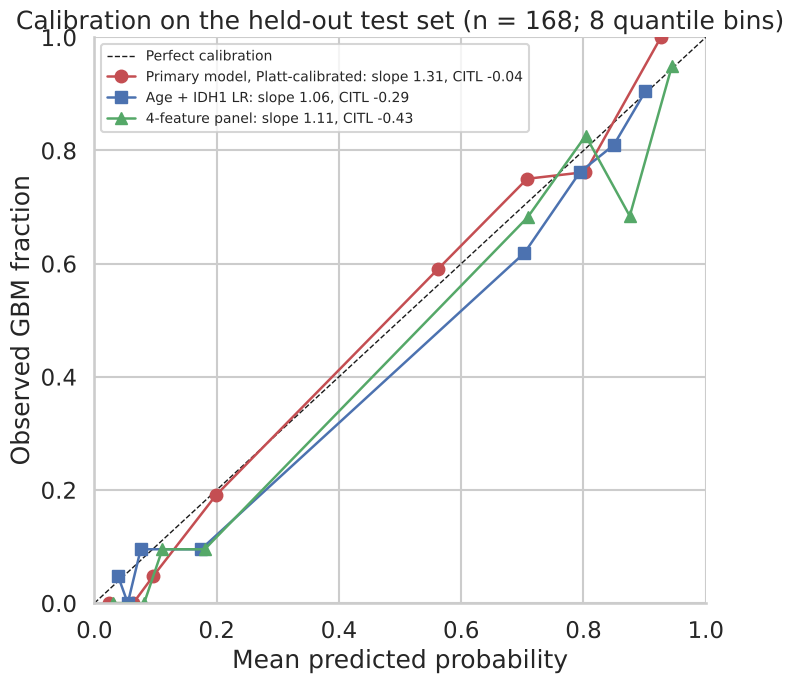

 Raw_scale_threshold  TP  TN  FP  FN  Sensitivity  Specificity   PPV   NPV  Accuracy
               0.405  65  78  20   5        0.929        0.796 0.765 0.940     0.851
               0.409  65  78  20   5        0.929        0.796 0.765 0.940     0.851
               0.410  65  78  20   5        0.929        0.796 0.765 0.940     0.851
               0.441  65  79  19   5        0.929        0.806 0.774 0.940     0.857
               0.469  65  79  19   5        0.929        0.806 0.774 0.940     0.857
               0.481  65  80  18   5        0.929        0.816 0.783 0.941     0.863
               0.492  64  80  18   6        0.914        0.816 0.780 0.930     0.857
               0.493  64  80  18   6        0.914        0.816 0.780 0.930     0.857
               0.493  64  80  18   6        0.914        0.816 0.780 0.930     0.857
               0.497  64  80  18   6        0.914        0.816 0.780 0.930     0.857


In [26]:
rng_cal = np.random.RandomState(RANDOM_STATE + 11)
def cal_metrics(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6); s, c = cal_slope_intercept(y, p)
    return {"Slope": s, "CITL": c, "ECE": ece(y, p), "Brier": brier_score_loss(y, p)}
cal_sets = [("Primary model, Platt-calibrated (as deployed)", "primary", p_primary), ("Primary model, raw", "primary_raw", p_primary_raw),
            ("Age + IDH1 LR (uncalibrated, class-weighted)", "AgeIDH1", p_base), (f"4-feature panel (uncalibrated, class-weighted)", "panel4", p_panel)]
cal_rows = []
for name, key, p in cal_sets:
    pt = cal_metrics(y_te, p); bs = []
    for _ in range(1000):
        i = rng_cal.randint(0, len(y_te), len(y_te))
        if len(np.unique(y_te[i])) < 2: continue
        try: bs.append(cal_metrics(y_te[i], p[i]))
        except Exception: pass
    bs = pd.DataFrame(bs); row = {"Model": name, "N": len(y_te), "Bootstrap_resamples_used": len(bs)}
    for k, v in pt.items():
        row[k] = v; row[f"{k}_CI_lo"] = np.percentile(bs[k], 2.5); row[f"{k}_CI_hi"] = np.percentile(bs[k], 97.5)
        record(f"TestCal_{key}_{k}", round(v, 3), "Table16c", f"95% CI {row[f'{k}_CI_lo']:.3f} to {row[f'{k}_CI_hi']:.3f}")
    cal_rows.append(row)
testcal = pd.DataFrame(cal_rows); testcal.round(4).to_csv(TABLE_DIR / "Table16c_TestSetCalibration.csv", index=False)
print(testcal.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 7))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
for (name, key, p), c, mk in zip([cal_sets[0], cal_sets[2], cal_sets[3]], ["#C44E52", "#4C72B0", "#55A868"], ["o", "s", "^"]):
    fp_, mp_ = calibration_curve(y_te, p, n_bins=8, strategy="quantile"); r_ = testcal.set_index("Model").loc[name]
    ax.plot(mp_, fp_, marker=mk, color=c, lw=1.8, label=f"{name.split(' (')[0]}: slope {r_.Slope:.2f}, CITL {r_.CITL:+.2f}")
ax.set(xlabel="Mean predicted probability", ylabel="Observed GBM fraction", xlim=(0, 1), ylim=(0, 1),
       title=f"Calibration on the held-out test set (n = {N_TEST}; 8 quantile bins)"); ax.legend(fontsize=10, loc="upper left")
savefig("Figure19_TestSetCalibration.png")

# Recalibrated Age + IDH1 comparator: does net benefit at the locked threshold change?
_cl = lambda p: np.clip(p, 1e-6, 1 - 1e-6)
base_oof_recal = np.zeros_like(age_idh1_oof)
for tr, te in ccv.split(age_idh1_oof.reshape(-1, 1), y_arr):
    base_oof_recal[te] = LogisticRegression().fit(logit(_cl(age_idh1_oof[tr])), y_arr[tr]).predict_proba(logit(_cl(age_idh1_oof[te])))[:, 1]
base_platt = LogisticRegression().fit(logit(_cl(age_idh1_oof)), y_arr)
p_base_recal = base_platt.predict_proba(logit(_cl(p_base)))[:, 1]
TAU_GRID = round(OPTIMAL_THRESHOLD, 2)
for tag, yy, pu, pr_, pm in [("Dev", y_arr, age_idh1_oof, base_oof_recal, primary_proba_final), ("Test", y_te, p_base, p_base_recal, p_primary)]:
    nbu, nbr, nbm = (net_benefit(yy, q, [TAU_GRID])[0] for q in (pu, pr_, pm))
    record(f"{tag}_NB_AgeIDH1_recalibrated_at_tau", round(nbr, 3), "Section 20h",
           f"threshold {TAU_GRID}; uncalibrated {nbu:.3f}; primary model {nbm:.3f}; Platt recalibration fitted on training OOF ({'cross-fitted' if tag == 'Dev' else 'all training OOF'})")
    record(f"{tag}_NB_AgeIDH1_uncalibrated_at_tau", round(nbu, 3), "Section 20h")
r_ = testcal.set_index("Model")
record("TestCal_AgeIDH1_recalibrated_CITL", round(cal_slope_intercept(y_te, _cl(p_base_recal))[1], 3), "Section 20h")

# Threshold uncertainty: test operating characteristics across the repeated-CV raw-scale Youden thresholds (R1 W4)
thr_rep = rep.youden_threshold_raw_scale.values
ops_rep = pd.DataFrame([{"Raw_scale_threshold": t, **ops(y_te, p_primary_raw, t)} for t in sorted(thr_rep)])
ops_rep.round(4).to_csv(TABLE_DIR / "Table17b_TestOpsAcrossRepeatedCVThresholds.csv", index=False)
record("Test_acc_range_repeatedCV_raw_thresholds", f"{ops_rep.Accuracy.min():.3f}-{ops_rep.Accuracy.max():.3f}", "Table17b",
       f"raw primary probabilities at the 10 repeated nested-CV raw-scale Youden thresholds ({thr_rep.min():.3f}-{thr_rep.max():.3f}); sensitivity {ops_rep.Sensitivity.min():.3f}-{ops_rep.Sensitivity.max():.3f}; specificity {ops_rep.Specificity.min():.3f}-{ops_rep.Specificity.max():.3f}")
record("Canonical_raw_threshold_below_all_repeats", bool(RAW_SCALE_YOUDEN < thr_rep.min()), "Section 13", f"canonical {RAW_SCALE_YOUDEN:.3f}; repeats {thr_rep.min():.3f}-{thr_rep.max():.3f}")
print(ops_rep.round(3).to_string(index=False))

## Section 20i — Post hoc (R4, RR-5): discrimination within IDH groups and the "net rescue" needed to beat the IDH rule
*Specified before this code was run. Descriptive.*

1. AUC of the locked model **within** IDH1/2-wild-type and within IDH1/2-mutant patients (dataset calls), for calibrated training out-of-fold predictions (raw out-of-fold also shown) and test predictions, with 1,000-resample bootstrap 95% CIs (dedicated seed). This qualifies the statement that the model "recovers IDH status": that holds at the decision level only.
2. **Net rescue.** The IDH rule is correct exactly on the label–IDH concordant patients, so model accuracy − rule accuracy = (discordant patients classified correctly − concordant patients misclassified)/N. Exceeding the rule's accuracy requires only a positive net rescue, not correct classification of most discordant patients. Reported for the IDH1 and IDH1/2 definitions.
3. The concordant-stratum AUC of Table 21 is retained but annotated as tautological (stratum defined by the outcome and the dominant predictor).

In [27]:
rng_w = np.random.RandomState(RANDOM_STATE + 5)
def auc_boot(y, p, B=1000, rs=rng_w):
    if len(np.unique(y)) < 2: return np.nan, np.nan, np.nan
    bs = []
    for _ in range(B):
        i = rs.randint(0, len(y), len(y))
        if len(np.unique(y[i])) > 1: bs.append(roc_auc_score(y[i], p[i]))
    return roc_auc_score(y, p), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
w_rows = []
for setname, tag, P, prov_ in [("Training OOF (calibrated)", "Dev", primary_proba_final, tr_prov), ("Training OOF (raw)", "DevRaw", primary_oof, tr_prov),
                               ("Sealed test", "Test", p_primary, te_prov)]:
    yy = prov_.Grade.values; idh = ((prov_.IDH1 == 1) | (prov_.IDH2 == 1)).values; pm = (P >= OPTIMAL_THRESHOLD).astype(int)
    for gname, gtag, m in [("IDH1/2-wild-type", "IDHwt", ~idh), ("IDH1/2-mutant", "IDHmut", idh)]:
        a, l, h = auc_boot(yy[m], P[m])
        row = {"Set": setname, "IDH_group": gname, "N": int(m.sum()), "N_GBM": int(yy[m].sum()), "N_LGG": int((1 - yy[m]).sum()),
               "AUC": a, "AUC_CI_lo": l, "AUC_CI_hi": h}
        if tag != "DevRaw":
            row.update({"Model_errors_at_locked_threshold": int((pm[m] != yy[m]).sum()), "Rule_IDH12_errors": int(((~idh[m]).astype(int) != yy[m]).sum())})
        w_rows.append(row)
        record(f"{tag}_withinAUC_{gtag}", round(a, 3), "Table30c", f"95% CI {l:.3f}-{h:.3f}; n={int(m.sum())} ({int(yy[m].sum())} GBM / {int((1 - yy[m]).sum())} LGG)")
within = pd.DataFrame(w_rows); within.round(4).to_csv(TABLE_DIR / "Table30c_WithinIDHGroupAUC.csv", index=False); print(within.round(3).to_string(index=False))

nr_rows = []
for setname, tag, P, prov_ in [("Training OOF", "Dev", primary_proba_final, tr_prov), ("Sealed test", "Test", p_primary, te_prov)]:
    yy = prov_.Grade.values; pm = (P >= OPTIMAL_THRESHOLD).astype(int); ok = pm == yy
    for dname, dtag, mut in [("IDH1", "IDH1", (prov_.IDH1 == 1).values), ("IDH1/2", "IDH12", ((prov_.IDH1 == 1) | (prov_.IDH2 == 1)).values)]:
        disc = ((yy == 1) & mut) | ((yy == 0) & ~mut); rule_err = int(disc.sum())
        dc, ce = int((ok & disc).sum()), int((~ok & ~disc).sum()); net = dc - ce
        assert net == rule_err - int((~ok).sum()), "net-rescue identity failed"
        nr_rows.append({"Set": setname, "Discordance_definition": dname, "N": len(yy), "Discordant_n": rule_err, "Discordant_correct": dc,
                        "Concordant_errors": ce, "Net_rescue": net, "Model_errors": int((~ok).sum()), "Rule_errors": rule_err,
                        "Model_acc_minus_rule_acc": net / len(yy)})
        record(f"{tag}_net_rescue_{dtag}", net, "Table30d", f"discordant correct {dc} of {rule_err} minus concordant errors {ce}; model errors {int((~ok).sum())} vs rule errors {rule_err}")
netres = pd.DataFrame(nr_rows); netres.round(4).to_csv(TABLE_DIR / "Table30d_NetRescue.csv", index=False); print(netres.to_string(index=False))

                      Set        IDH_group   N  N_GBM  N_LGG   AUC  AUC_CI_lo  AUC_CI_hi  Model_errors_at_locked_threshold  Rule_IDH12_errors
Training OOF (calibrated) IDH1/2-wild-type 328    261     67 0.662      0.589      0.722                              65.0               67.0
Training OOF (calibrated)    IDH1/2-mutant 343     21    322 0.628      0.513      0.735                              21.0               21.0
       Training OOF (raw) IDH1/2-wild-type 328    261     67 0.666      0.605      0.736                               NaN                NaN
       Training OOF (raw)    IDH1/2-mutant 343     21    322 0.637      0.532      0.737                               NaN                NaN
              Sealed test IDH1/2-wild-type  84     66     18 0.707      0.582      0.821                              19.0               18.0
              Sealed test    IDH1/2-mutant  84      4     80 0.859      0.727      0.969                               6.0                4.0
      

## Section 20j — Post hoc (R4, RR-3): sensitivity of the WHO 2021 reconstruction to its rules, the IDH source and H3 status
*Specified before this code was run. Descriptive; the reconstruction rules were fixed after the test set had been scored (disclosed).*

**H3.** H3F3A (H3-3A) and HIST1H3B/C (H3C2/H3C3) calls are taken from the exome mutation file of the same cBioPortal study (`data_mutations.txt`, filtered to these genes; `Data/External/Ceccarelli2016_H3_mutations.csv`). HGVS protein numbering counts the initiator methionine, so p.K28M = legacy K27M and p.G35R/V = legacy G34R/V. Hotspot = K27M (H3.3 or H3.1) or G34R/V (H3.3). Patients absent from the study's list of exome-sequenced samples are "not sequenced" (H3 unknown). H3-altered tumours are not glioblastoma: G34-mutant → diffuse hemispheric glioma, H3 G34-mutant (CNS WHO grade 4); K27M → diffuse midline glioma only if midline (location not available), so grade 4 is unassignable.

**Variants** (each changes one rule relative to the R3 base unless stated):
- **a — base** (R3 rules; IDH from the dataset's IDH1/IDH2 calls).
- **b — Ceccarelli IDH status** as the IDH source where available (fallback: dataset calls).
- **c — astrocytic histology only:** molecular glioblastoma criteria applied only to IDH-wild-type legacy LGG with astrocytic histology (Astrocytoma, NOS / anaplastic); IDH-wild-type oligodendroglial or mixed tumours are "NEC (unassignable)" and excluded from both targets.
- **d — NEC coding:** IDH-wild-type tumours meeting no criterion are "NEC (unassignable)" and excluded from both targets (d2: excluded from the grade 4 target only, kept as "not glioblastoma").
- **e — b + c + d.**
- **f — base + H3.**
- **g — b + c + d + H3** (most conservative).
- **h1 / h0 — base with the not-assessable IDH-wild-type tumours assigned positive / negative** for both targets (R1 W2 question 1).

For every variant: the model-free counts (IDH-wild-type legacy LGG meeting molecular glioblastoma criteria; agreement of the legacy label with each target), then the locked model and the IDH1/2 rule against each target (development OOF and test), and the number of legacy-label errors whose prediction agrees with each target and with **both** targets. The IDH1/2 rule always uses the dataset calls (the model's inputs). The criterion (TERT, EGFR amplification, +7/−10) that qualified each molecular glioblastoma is tabulated, including how many rely on EGFR amplification alone.

In [28]:
h3m = pd.read_csv(DATA_DIR / "External" / "Ceccarelli2016_H3_mutations.csv")
seq_ids = set(pd.read_csv(DATA_DIR / "External" / "Ceccarelli2016_exome_sequenced_samples.csv").PATIENT_ID)
idhmaf = pd.read_csv(DATA_DIR / "External" / "Ceccarelli2016_IDH_mutations.csv")
meth = pd.read_csv(DATA_DIR / "External" / "Ceccarelli2016_methylation_BRAF.csv")
H3_K27 = {"p.K28M": "H3 K27M"}; H3_G34 = {"p.G35R": "H3 G34R", "p.G35V": "H3 G34V"}
hot = h3m[(h3m.HGVSp_Short.isin(H3_K27) & h3m.Hugo_Symbol.isin(["H3F3A", "H3-3A", "HIST1H3B", "H3C2", "HIST1H3C", "H3C3"])) |
          (h3m.HGVSp_Short.isin(H3_G34) & h3m.Hugo_Symbol.isin(["H3F3A", "H3-3A"]))]
h3map = hot.groupby("PATIENT_ID").HGVSp_Short.first().map({**H3_K27, **H3_G34})
mol["Exome_sequenced"] = mol.Case_ID.isin(seq_ids)
mol["H3_status"] = np.where(mol.Case_ID.isin(h3map.index), mol.Case_ID.map(h3map).fillna(""),
                            np.where(mol.Exome_sequenced, "No H3 K27/G34 hotspot", "Not exome-sequenced"))
hs = idhmaf[((idhmaf.Hugo_Symbol == "IDH1") & idhmaf.HGVSp_Short.str.startswith("p.R132")) |
            ((idhmaf.Hugo_Symbol == "IDH2") & idhmaf.HGVSp_Short.str.startswith("p.R172"))]
hsmap = hs.assign(c=hs.Hugo_Symbol + " " + hs.HGVSp_Short.str[2:]).groupby("PATIENT_ID").c.agg(lambda x: "; ".join(sorted(set(x))))
mol["IDH_hotspot_MAF"] = np.where(mol.Case_ID.isin(hsmap.index), mol.Case_ID.map(hsmap).fillna(""),
                                  np.where(mol.Exome_sequenced, "none", "Not exome-sequenced"))
mol = mol.drop(columns=["PATIENT_ID"]).merge(meth.rename(columns={"PATIENT_ID": "Case_ID"})[["Case_ID", "SUPERVISED_DNA_METHYLATION_CLUSTER", "BRAF_V600E_STATUS"]], on="Case_ID", how="left")
assert len(mol) == N_ANALYSIS and (mol.Case_ID.values == prov.Case_ID.values).all()
mol["idh_mut_cecc"] = mol.IDH_STATUS.map({"Mutant": True, "WT": False}).fillna(mol.idh_mut).astype(bool)

# IDH source agreement (R2 W1)
both = mol.IDH_STATUS.notna()
idh_diff = mol[both & (mol.idh_mut != mol.idh_mut_cecc)]
seqm = mol.Exome_sequenced
maf_mut = mol.IDH_hotspot_MAF.str.contains("IDH")
record("IDH_sources_differ_n", len(idh_diff), "Table35c", f"dataset IDH1/2 calls vs Ceccarelli IDH_STATUS among {int(both.sum())} with both; " +
       "; ".join(f"{r.Case_ID} ({'mut' if r.idh_mut else 'wt'}->{'mut' if r.idh_mut_cecc else 'wt'})" for r in idh_diff.itertuples()))
record("IDH_dataset_vs_MAFhotspot_agree_pct", round((mol.idh_mut == maf_mut)[seqm].mean() * 100, 1), "Table35c", f"among {int(seqm.sum())} exome-sequenced patients; disagree n={int((mol.idh_mut != maf_mut)[seqm].sum())}")
record("IDH_cecc_vs_MAFhotspot_agree_pct", round((mol.idh_mut_cecc == maf_mut)[seqm & both].mean() * 100, 1), "Table35c", f"n={int((seqm & both).sum())}")
record("Exome_sequenced_n", int(seqm.sum()), "Section 20j", f"legacy LGG {int((seqm & (mol.Grade == 0)).sum())}, legacy GBM {int((seqm & (mol.Grade == 1)).sum())}")
record("Cecc_IDH_status_available_n", int(both.sum()), "Section 20j")

ASTRO_HIST = {"Astrocytoma, NOS", "Astrocytoma, anaplastic"}
CAT_MOLGBM = "Glioblastoma, IDH-wildtype (molecular criteria)"
def who2021_v(r, idh_src="dataset", astro_only=False, nec=None, h3=False, na=None):
    """(category, CNS WHO grade 4 1/0/NaN, glioblastoma IDH-wildtype 1/0/NaN, criterion). Defaults reproduce the R3 base rules."""
    idh = bool(r.idh_mut_cecc) if idh_src == "ceccarelli" else bool(r.idh_mut)
    if h3 and not idh and r.H3_status in ("H3 G34R", "H3 G34V"):
        return "Diffuse hemispheric glioma, H3 G34-mutant", 1, 0, "IDH-wildtype + H3-3A G34 hotspot (not glioblastoma; CNS WHO grade 4)"
    if h3 and not idh and r.H3_status == "H3 K27M":
        return "Diffuse glioma, H3 K27M-mutant (location unknown)", np.nan, 0, "IDH-wildtype + H3 K27M hotspot (not glioblastoma; grade 4 only if midline, location unavailable)"
    if idh:
        if r.IDH_1P19Q_SUBTYPE == "Codel": return "Oligodendroglioma, IDH-mutant, 1p/19q-codeleted", 0, 0, "IDH-mutant + 1p/19q codeletion"
        if pd.isna(r.IDH_1P19Q_SUBTYPE): return "IDH-mutant, 1p/19q unknown", np.nan, 0, "IDH-mutant; 1p/19q status unavailable"
        cdkn = (r.CDKN2A == -2) or (r.CDKN2B == -2)
        if r.Grade == 1 or cdkn:
            why = " + ".join(x for x, v in [("legacy GBM histology (necrosis/MVP proxy)", r.Grade == 1), ("CDKN2A/B homozygous deletion", cdkn)] if v)
            return "Astrocytoma, IDH-mutant, grade 4", 1, 0, "IDH-mutant, non-codeleted + " + why
        if pd.isna(r.CDKN2A): return "Astrocytoma, IDH-mutant, grade not assignable", np.nan, 0, "IDH-mutant, non-codeleted; CDKN2A/B call unavailable"
        return "Astrocytoma, IDH-mutant, grade 2-3", 0, 0, "IDH-mutant, non-codeleted; no grade 4 criterion"
    if r.Grade == 1: return "Glioblastoma, IDH-wildtype (histological criteria)", 1, 1, "IDH-wildtype + legacy GBM histology (necrosis/MVP proxy)"
    if astro_only and r.Primary_Diagnosis not in ASTRO_HIST:
        return "IDH-wildtype, oligodendroglial/mixed histology: NEC (unassignable)", np.nan, np.nan, "IDH-wildtype, non-astrocytic legacy histology; molecular criteria not applied"
    tert = r.TERT_PROMOTER_STATUS == "Mutant"; egfr = r.EGFR == 2; c710 = r.CHR_7_GAIN_CHR_10_LOSS == "Gain chr 7 & loss chr 10"
    crit = [n for n, v in [("TERT promoter mutation", tert), ("EGFR amplification", egfr), ("+7/-10", c710)] if v]
    if crit: return CAT_MOLGBM, 1, 1, "IDH-wildtype + " + " + ".join(crit)
    if (not pd.isna(r.EGFR)) and (not pd.isna(r.CHR_7_GAIN_CHR_10_LOSS)) and r.TERT_PROMOTER_STATUS == "WT":
        why = "IDH-wildtype; TERT WT, no EGFR amplification, no +7/-10"
        if nec == "both": return "IDH-wildtype, NEC (no glioblastoma criterion met)", np.nan, np.nan, why
        if nec == "grade": return "IDH-wildtype, NEC (no glioblastoma criterion met)", np.nan, 0, why
        return "IDH-wildtype, glioblastoma criteria not met", 0, 0, why
    g = {None: np.nan, 1: 1, 0: 0}[na]
    return "IDH-wildtype, glioblastoma status not assessable (TERT unknown)", g, g, "IDH-wildtype; no criterion detected; TERT (or EGFR / +7/-10) unknown"

VARIANTS = {"a": ("Base (R3 rules)", {}), "b": ("Ceccarelli IDH status", {"idh_src": "ceccarelli"}),
            "c": ("Astrocytic histology only", {"astro_only": True}), "d": ("NEC unassignable (both targets)", {"nec": "both"}),
            "d2": ("NEC unassignable (grade 4 target only)", {"nec": "grade"}),
            "e": ("b + c + d", {"idh_src": "ceccarelli", "astro_only": True, "nec": "both"}), "f": ("Base + H3", {"h3": True}),
            "g": ("b + c + d + H3", {"idh_src": "ceccarelli", "astro_only": True, "nec": "both", "h3": True}),
            "h1": ("Base; not assessable -> positive", {"na": 1}), "h0": ("Base; not assessable -> negative", {"na": 0})}
VR = {}
for v, (vname, kw) in VARIANTS.items():
    res = pd.DataFrame([who2021_v(r, **kw) for r in mol.itertuples()], columns=["cat", "g4", "gbm", "rule"], index=mol.index)
    res["g4"] = res.g4.astype(float); res["gbm"] = res.gbm.astype(float); VR[v] = res
# the parametrised function must reproduce the R3 base reconstruction exactly
assert (VR["a"].cat == mol.WHO2021_reconstructed).all()
assert VR["a"].g4.fillna(-9).equals(mol.WHO_grade4.astype(float).fillna(-9)) and VR["a"].gbm.fillna(-9).equals(mol.WHO_GBM_IDHwt.astype(float).fillna(-9))

tert_m = mol.TERT_PROMOTER_STATUS == "Mutant"; egfr_m = mol.EGFR == 2; c710_m = mol.CHR_7_GAIN_CHR_10_LOSS == "Gain chr 7 & loss chr 10"
summ_rows, perf_rows, crit_rows = [], [], []
for v, (vname, kw) in VARIANTS.items():
    R = VR[v]; idh = mol.idh_mut_cecc if kw.get("idh_src") == "ceccarelli" else mol.idh_mut
    wt_lgg = (~idh) & (mol.Grade == 0); molg = R.cat == CAT_MOLGBM
    egfr_only = molg & egfr_m & ~c710_m & ~tert_m
    row = {"Variant": v, "Description": vname, "IDHwt_legacy_LGG_n": int(wt_lgg.sum()), "Molecular_GBM_n": int(molg.sum()),
           "Molecular_GBM_pct_of_IDHwt_LGG": molg.sum() / wt_lgg.sum() * 100,
           "Criteria_not_met_n": int((R.cat == "IDH-wildtype, glioblastoma criteria not met").sum()),
           "NEC_no_criterion_n": int((R.cat == "IDH-wildtype, NEC (no glioblastoma criterion met)").sum()),
           "NEC_oligo_mixed_histology_n": int((R.cat == "IDH-wildtype, oligodendroglial/mixed histology: NEC (unassignable)").sum()),
           "Not_assessable_n": int((R.cat == "IDH-wildtype, glioblastoma status not assessable (TERT unknown)").sum()),
           "H3_altered_n": int(R.cat.str.contains("H3").sum()), "IDHmut_legacy_GBM_n": int((idh & (mol.Grade == 1)).sum()),
           "Molecular_GBM_EGFRamp_only_n": int(egfr_only.sum()), "Molecular_GBM_EGFRamp_only_TERTunknown_n": int((egfr_only & mol.TERT_PROMOTER_STATUS.isna()).sum())}
    for tgt, tn in [("g4", "Grade4"), ("gbm", "GBMwt")]:
        k = R[tgt].notna(); row[f"{tn}_known_n"] = int(k.sum()); row[f"{tn}_positives"] = int(R.loc[k, tgt].sum())
        row[f"{tn}_positives_legacy_GBM"] = int(((R[tgt] == 1) & (mol.Grade == 1)).sum())
        row[f"Legacy_agrees_{tn}_n"] = int((R.loc[k, tgt] == mol.loc[k, "Grade"]).sum()); row[f"Legacy_agrees_{tn}_pct"] = row[f"Legacy_agrees_{tn}_n"] / k.sum() * 100
    summ_rows.append(row)
    record(f"RS_{v}_molGBM_of_IDHwtLGG", f"{row['Molecular_GBM_n']}/{row['IDHwt_legacy_LGG_n']}", "Table35a",
           f"{vname}; {row['Molecular_GBM_pct_of_IDHwt_LGG']:.1f}%; criteria not met {row['Criteria_not_met_n']}; NEC {row['NEC_no_criterion_n'] + row['NEC_oligo_mixed_histology_n']}; not assessable {row['Not_assessable_n']}; H3 {row['H3_altered_n']}")
    record(f"RS_{v}_molGBM_n", row["Molecular_GBM_n"], "Table35a"); record(f"RS_{v}_IDHwtLGG_n", row["IDHwt_legacy_LGG_n"], "Table35a")
    for tn in ["Grade4", "GBMwt"]:
        record(f"RS_{v}_legacy_agree_{tn}_pct", round(row[f"Legacy_agrees_{tn}_pct"], 1), "Table35a", f"{row[f'Legacy_agrees_{tn}_n']}/{row[f'{tn}_known_n']}; positives {row[f'{tn}_positives']} of which legacy GBM {row[f'{tn}_positives_legacy_GBM']}")
    # criterion breakdown among molecular glioblastomas
    for combo_name, m in [("TERT only", tert_m & ~egfr_m & ~c710_m), ("EGFR amplification only", egfr_m & ~tert_m & ~c710_m),
                          ("+7/-10 only", c710_m & ~tert_m & ~egfr_m), ("TERT + EGFR amplification", tert_m & egfr_m & ~c710_m),
                          ("TERT + +7/-10", tert_m & c710_m & ~egfr_m), ("EGFR amplification + +7/-10", egfr_m & c710_m & ~tert_m),
                          ("All three", tert_m & egfr_m & c710_m)]:
        mm = molg & m
        crit_rows.append({"Variant": v, "Description": vname, "Qualifying_criteria": combo_name, "N": int(mm.sum()),
                          "TERT_WT": int((mm & (mol.TERT_PROMOTER_STATUS == "WT")).sum()), "TERT_unknown": int((mm & mol.TERT_PROMOTER_STATUS.isna()).sum()),
                          "Oligo_or_mixed_histology": int((mm & ~mol.Primary_Diagnosis.isin(ASTRO_HIST)).sum())})
    for setname, tag in [("Training OOF", "Dev"), ("Sealed test", "Test")]:
        ms = mol.set == setname; err = ms & (mol.pred != mol.Grade)
        for tgt, tn in [("g4", "Grade4"), ("gbm", "GBMwt")]:
            k = ms & R[tgt].notna(); yy = R.loc[k, tgt].astype(int).values; pp = mol.loc[k, "prob"].values; rr = mol.loc[k, "rule12"].values
            o = ops(yy, pp, OPTIMAL_THRESHOLD); orl = ops(yy, rr, 0.5); ek = err & R[tgt].notna(); ag = ek & (mol.pred == R[tgt])
            perf_rows.append({"Variant": v, "Description": vname, "Set": setname, "Target": tn, "N": int(k.sum()), "N_positive": int(yy.sum()),
                              "Model_AUC": roc_auc_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan, "Model_accuracy": o["Accuracy"],
                              "Model_errors": o["FP"] + o["FN"], "Rule_IDH12_accuracy": orl["Accuracy"], "Rule_IDH12_errors": orl["FP"] + orl["FN"],
                              "Legacy_errors_total": int(err.sum()), "Legacy_errors_with_target": int(ek.sum()), "Legacy_errors_agreeing_with_target": int(ag.sum())})
            record(f"RS_{v}_{tag}_{tn}_model_vs_rule_acc", f"{o['Accuracy']:.3f} vs {orl['Accuracy']:.3f}", "Table35b",
                   f"model errors {o['FP'] + o['FN']} vs rule errors {orl['FP'] + orl['FN']}; n={int(k.sum())}; model AUC {perf_rows[-1]['Model_AUC']:.3f}")
            record(f"RS_{v}_{tag}_legacy_errors_agree_{tn}", f"{int(ag.sum())}/{int(ek.sum())}", "Table35b", f"of {int(err.sum())} legacy-label errors in total")
        kb = err & R.g4.notna() & R.gbm.notna(); a4 = mol.pred == R.g4; aw = mol.pred == R.gbm
        perf_rows.append({"Variant": v, "Description": vname, "Set": setname, "Target": "Both (grade 4 and GBM IDH-wt)",
                          "Legacy_errors_total": int(err.sum()), "Legacy_errors_with_target": int(kb.sum()),
                          "Legacy_errors_agreeing_with_target": int((kb & a4 & aw).sum()), "Agree_grade4_only": int((kb & a4 & ~aw).sum()),
                          "Agree_GBMwt_only": int((kb & ~a4 & aw).sum()), "Agree_neither": int((kb & ~a4 & ~aw).sum())})
        record(f"RS_{v}_{tag}_legacy_errors_agree_both", f"{int((kb & a4 & aw).sum())}/{int(kb.sum())}", "Table35b",
               f"grade-4 only {int((kb & a4 & ~aw).sum())}; GBM-IDHwt only {int((kb & ~a4 & aw).sum())}; neither {int((kb & ~a4 & ~aw).sum())}; {int(err.sum())} errors in total")
rs_summ = pd.DataFrame(summ_rows); rs_summ.round(2).to_csv(TABLE_DIR / "Table35a_ReconstructionSensitivity_Counts.csv", index=False)
rs_perf = pd.DataFrame(perf_rows); rs_perf.round(4).to_csv(TABLE_DIR / "Table35b_ReconstructionSensitivity_ModelAndRule.csv", index=False)
rs_crit = pd.DataFrame(crit_rows); rs_crit.to_csv(TABLE_DIR / "Table36_MolecularGBM_QualifyingCriteria.csv", index=False)
print(rs_summ.round(1).to_string(index=False)); print(rs_crit[rs_crit.Variant.isin(["a", "g"])].to_string(index=False))
print(rs_perf[rs_perf.Variant.isin(["a", "b", "c", "d", "e", "f", "g"])].round(3).to_string(index=False))
for v in ["a", "b", "e", "g"]:
    s_ = rs_summ.set_index("Variant").loc[v]
    record(f"RS_{v}_molGBM_EGFRamp_only_n", int(s_.Molecular_GBM_EGFRamp_only_n), "Table36", f"of {int(s_.Molecular_GBM_n)} molecular GBM; TERT unknown in {int(s_.Molecular_GBM_EGFRamp_only_TERTunknown_n)}")
record("RS_range_molGBM_pct", f"{rs_summ.Molecular_GBM_pct_of_IDHwt_LGG.min():.1f}-{rs_summ.Molecular_GBM_pct_of_IDHwt_LGG.max():.1f}", "Table35a", "across variants a-g, h0, h1")

# Patients whose IDH status differs between sources (R2 W1)
idd = mol.loc[idh_diff.index, ["Case_ID", "Grade", "IDH1", "IDH2", "IDH_STATUS", "IDH_hotspot_MAF", "Primary_Diagnosis"]].copy()
idd["Base_category"] = VR["a"].cat[idh_diff.index]; idd["Variant_b_category"] = VR["b"].cat[idh_diff.index]
idd = idd.join(prov.loc[idh_diff.index, ["TP53", "ATRX"]]); idd["Partition"] = mol.set[idh_diff.index]
idd.to_csv(TABLE_DIR / "Table35c_IDHSourceDiscordantPatients.csv", index=False); print(idd.to_string(index=False))
# H3 hotspot patients (R2 W3) and the age check for IDH-wild-type patients
h3p = mol[mol.H3_status.isin(["H3 K27M", "H3 G34R", "H3 G34V"])][["Case_ID", "Grade", "IDH1", "IDH2", "IDH_STATUS", "H3_status", "Primary_Diagnosis"]].copy()
h3p["Age_at_diagnosis"] = df.loc[h3p.index, "Age_at_diagnosis"].values; h3p["Base_category"] = VR["a"].cat[h3p.index]; h3p["H3_variant_category"] = VR["f"].cat[h3p.index]
h3p["Partition"] = mol.set[h3p.index]; h3p.to_csv(TABLE_DIR / "Table35d_H3HotspotPatients.csv", index=False); print(h3p.to_string(index=False))
wt_all = ~mol.idh_mut
record("H3_hotspot_n", len(h3p), "Table35d", "; ".join(f"{r.Case_ID} {r.H3_status} ({'legacy GBM' if r.Grade else 'legacy LGG'}, age {r.Age_at_diagnosis:.0f}; base: {r.Base_category})" for r in h3p.itertuples()))
record("H3_IDHwt_sequenced_n", int((wt_all & mol.Exome_sequenced).sum()), "Section 20j", f"of {int(wt_all.sum())} IDH1/2-wild-type; IDH-wt legacy LGG sequenced {int((wt_all & mol.Exome_sequenced & (mol.Grade == 0)).sum())} of {int((wt_all & (mol.Grade == 0)).sum())}")
record("IDHwt_min_age", round(float(df.loc[wt_all, "Age_at_diagnosis"].min()), 1), "Section 20j", f"youngest IDH1/2-wild-type patient; n under 18 = {int((df.loc[wt_all, 'Age_at_diagnosis'] < 18).sum())}")
# R2 W5: agreeing errors involving oligodendroglial / mixed histology (base)
olig = ~mol.Primary_Diagnosis.isin(ASTRO_HIST | {"Glioblastoma"})
for setname, tag in [("Training OOF", "Dev"), ("Sealed test", "Test")]:
    ms = mol.set == setname; err = ms & (mol.pred != mol.Grade); ag = err & (mol.pred == VR["a"].gbm)
    record(f"{tag}_agreeing_errors_oligo_mixed_hist", int((ag & olig & (VR["a"].cat == CAT_MOLGBM)).sum()), "Section 20j",
           f"legacy-label errors agreeing with the GBM-IDHwt target that are molecular GBMs with oligodendroglial/mixed histology (of {int(ag.sum())} agreeing errors)")

Variant                            Description  IDHwt_legacy_LGG_n  Molecular_GBM_n  Molecular_GBM_pct_of_IDHwt_LGG  Criteria_not_met_n  NEC_no_criterion_n  NEC_oligo_mixed_histology_n  Not_assessable_n  H3_altered_n  IDHmut_legacy_GBM_n  Molecular_GBM_EGFRamp_only_n  Molecular_GBM_EGFRamp_only_TERTunknown_n  Grade4_known_n  Grade4_positives  Grade4_positives_legacy_GBM  Legacy_agrees_Grade4_n  Legacy_agrees_Grade4_pct  GBMwt_known_n  GBMwt_positives  GBMwt_positives_legacy_GBM  Legacy_agrees_GBMwt_n  Legacy_agrees_GBMwt_pct
      a                        Base (R3 rules)                  85               68                            80.0                   8                   0                            0                 9             0                   25                             4                                         1             827               433                          350                     744                      90.0            830              395               

## Section 20k — Post hoc (R4, R2 W2/W8): mutation frequencies by reconstructed category
*Specified before this code was run. Descriptive (whole cohort, n = 839; no model involved).*

1. Among IDH-wild-type patients: NF1, EGFR (mutation), PTEN and TP53 frequencies in histological glioblastoma, molecular glioblastoma, "criteria not met" and "not assessable", under the base reconstruction (a) and with Ceccarelli IDH status (b). Two Fisher exact tests per gene: molecular vs histological glioblastoma; unresolved (criteria not met + not assessable) vs all tumours meeting glioblastoma criteria.
2. EGFR mutation versus GISTIC EGFR amplification among IDH-wild-type tumours (overlap and Fisher test).
3. TP53 and ATRX in IDH-mutant astrocytoma (any grade) versus oligodendroglioma (base reconstruction).
4. Supervised DNA-methylation cluster (Ceccarelli et al.) by reconstructed category among IDH-wild-type tumours, to flag possible non-glioblastoma entities (PA-like, LGm6-GBM).

In [29]:
bio = mol[["Case_ID", "Grade", "idh_mut", "idh_mut_cecc", "EGFR", "CDKN2A", "CDKN2B", "TERT_PROMOTER_STATUS", "CHR_7_GAIN_CHR_10_LOSS",
           "SUPERVISED_DNA_METHYLATION_CLUSTER", "Primary_Diagnosis"]].rename(columns={"EGFR": "EGFR_GISTIC"}).join(prov[GENE_FEATURES])
CATS_WT = [("Histological GBM", "Glioblastoma, IDH-wildtype (histological criteria)"), ("Molecular GBM", CAT_MOLGBM),
           ("Criteria not met", "IDH-wildtype, glioblastoma criteria not met"), ("Not assessable", "IDH-wildtype, glioblastoma status not assessable (TERT unknown)")]
fmt = lambda k, n: f"{k}/{n} ({k / n * 100:.1f}%)" if n else "0/0"
bio_rows = []
for v in ["a", "b"]:
    cat = VR[v].cat
    for g in ["NF1", "EGFR", "PTEN", "TP53"]:
        row = {"Variant": v, "Gene": g + (" (mutation)" if g == "EGFR" else "")}
        cnt = {}
        for lbl, c in CATS_WT:
            m = cat == c; cnt[lbl] = (int(bio.loc[m, g].sum()), int(m.sum())); row[lbl] = fmt(*cnt[lbl])
        k1, n1 = cnt["Molecular GBM"]; k2, n2 = cnt["Histological GBM"]
        row["Fisher_p_molecular_vs_histological"] = fisher_exact([[k1, n1 - k1], [k2, n2 - k2]])[1]
        ku = cnt["Criteria not met"][0] + cnt["Not assessable"][0]; nu = cnt["Criteria not met"][1] + cnt["Not assessable"][1]
        row["Unresolved"] = fmt(ku, nu); row["GBM_criteria_met"] = fmt(k1 + k2, n1 + n2)
        row["Fisher_p_unresolved_vs_GBM_criteria_met"] = fisher_exact([[ku, nu - ku], [k1 + k2, n1 + n2 - k1 - k2]])[1]
        bio_rows.append(row)
        if v == "a":
            record(f"Bio_{g}_molGBM_vs_histGBM", f"{k1}/{n1} vs {k2}/{n2}", "Table37", f"Fisher p={row['Fisher_p_molecular_vs_histological']:.2g}")
            record(f"Bio_{g}_unresolved_vs_GBMcriteria", f"{ku}/{nu} vs {k1 + k2}/{n1 + n2}", "Table37", f"Fisher p={row['Fisher_p_unresolved_vs_GBM_criteria_met']:.2g}")
biot = pd.DataFrame(bio_rows); biot.to_csv(TABLE_DIR / "Table37_IDHwt_MutationsByReconstructedCategory.csv", index=False); print(biot.to_string(index=False))

# EGFR mutation vs amplification among IDH-wild-type tumours
wtk = (~bio.idh_mut) & bio.EGFR_GISTIC.notna(); amp = bio.EGFR_GISTIC == 2
ov_rows = []
for lbl, m in [("IDH-wild-type, all", wtk), ("IDH-wild-type legacy LGG", wtk & (bio.Grade == 0)), ("IDH-wild-type legacy GBM", wtk & (bio.Grade == 1))]:
    t = pd.crosstab(bio.loc[m, "EGFR"], amp[m]).reindex(index=[0, 1], columns=[False, True], fill_value=0)
    ov_rows.append({"Group": lbl, "N": int(m.sum()), "Mut+Amp+": int(t.loc[1, True]), "Mut+Amp-": int(t.loc[1, False]), "Mut-Amp+": int(t.loc[0, True]),
                    "Mut-Amp-": int(t.loc[0, False]), "Fisher_p": fisher_exact(t.values)[1]})
egfr_ov = pd.DataFrame(ov_rows); egfr_ov.to_csv(TABLE_DIR / "Table37b_EGFR_MutationVsAmplification.csv", index=False); print(egfr_ov.to_string(index=False))
r_ = egfr_ov.set_index("Group").loc["IDH-wild-type legacy LGG"]
record("Bio_IDHwtLGG_EGFRmut_with_amp", f"{int(r_['Mut+Amp+'])}/{int(r_['Mut+Amp+'] + r_['Mut+Amp-'])}", "Table37b", "EGFR-mutant IDH-wild-type legacy LGG with GISTIC EGFR amplification (+2)")
r_ = egfr_ov.set_index("Group").loc["IDH-wild-type, all"]
record("Bio_IDHwt_EGFRmut_with_amp", f"{int(r_['Mut+Amp+'])}/{int(r_['Mut+Amp+'] + r_['Mut+Amp-'])}", "Table37b", f"amplified without mutation {int(r_['Mut-Amp+'])}; Fisher p={r_.Fisher_p:.2g}")

# TP53 / ATRX in IDH-mutant astrocytoma vs oligodendroglioma (base)
astro = VR["a"].cat.str.startswith("Astrocytoma, IDH-mutant"); oligo = VR["a"].cat.str.startswith("Oligodendroglioma")
lin_rows = []
for g in ["TP53", "ATRX"]:
    ka, na_, ko, no_ = int(bio.loc[astro, g].sum()), int(astro.sum()), int(bio.loc[oligo, g].sum()), int(oligo.sum())
    p_ = fisher_exact([[ka, na_ - ka], [ko, no_ - ko]])[1]
    lin_rows.append({"Gene": g, "IDH-mutant astrocytoma": fmt(ka, na_), "Oligodendroglioma": fmt(ko, no_), "Fisher_p": p_})
    record(f"Bio_{g}_astro_vs_oligo", f"{ka}/{na_} vs {ko}/{no_}", "Table37c", f"Fisher p={p_:.2g}")
astro_gbm = astro & (bio.Grade == 1)
lin_rows.append({"Gene": "Legacy GBM label", "IDH-mutant astrocytoma": fmt(int(astro_gbm.sum()), int(astro.sum())),
                 "Oligodendroglioma": fmt(int((oligo & (bio.Grade == 1)).sum()), int(oligo.sum())), "Fisher_p": np.nan})
record("Bio_IDHmut_legacyGBM_in_astro_vs_oligo", f"{int(astro_gbm.sum())} vs {int((oligo & (bio.Grade == 1)).sum())}", "Table37c", "IDH-mutant legacy GBM that are astrocytoma vs oligodendroglioma (base)")
lin = pd.DataFrame(lin_rows); lin.to_csv(TABLE_DIR / "Table37c_TP53_ATRX_AstroVsOligo.csv", index=False); print(lin.to_string(index=False))

# Methylation clusters by category (IDH-wild-type, base)
wt_cat = VR["a"].cat.where(~bio.idh_mut)
methx = pd.crosstab(wt_cat, bio.SUPERVISED_DNA_METHYLATION_CLUSTER.fillna("not available"))
methx.to_csv(TABLE_DIR / "Table37d_IDHwt_MethylationClusterByCategory.csv"); print(methx.to_string())
for c in ["PA-like", "LGm6-GBM"]:
    if c in methx.columns:
        record(f"Bio_IDHwt_{c}_by_category", "; ".join(f"{k.split(' (')[0].replace('IDH-wildtype, ', '')}: {int(v)}" for k, v in methx[c].items() if v), "Table37d")
# NF1 + CDKN2A/B deletion profile without glioblastoma criteria (R2 W2: possible high-grade astrocytoma with piloid features)
unres = VR["a"].cat.isin([CATS_WT[2][1], CATS_WT[3][1]])
nf1p = bio[unres & (bio.NF1 == 1) & ((bio.CDKN2A == -2) | (bio.CDKN2B == -2))]
record("Bio_unresolved_NF1_CDKN2AB_profile", len(nf1p), "Section 20k", ", ".join(f"{r.Case_ID} ({r.SUPERVISED_DNA_METHYLATION_CLUSTER if isinstance(r.SUPERVISED_DNA_METHYLATION_CLUSTER, str) else 'no methylation call'})" for r in nf1p.itertuples()))

Variant            Gene Histological GBM Molecular GBM Criteria not met Not assessable  Fisher_p_molecular_vs_histological   Unresolved GBM_criteria_met  Fisher_p_unresolved_vs_GBM_criteria_met
      a             NF1   37/327 (11.3%) 11/68 (16.2%)      3/8 (37.5%)    6/9 (66.7%)                            0.306231 9/17 (52.9%)   48/395 (12.2%)                                 0.000102
      a EGFR (mutation)   78/327 (23.9%) 28/68 (41.2%)      1/8 (12.5%)    1/9 (11.1%)                            0.006314 2/17 (11.8%)  106/395 (26.8%)                                 0.259036
      a            PTEN  114/327 (34.9%) 17/68 (25.0%)       0/8 (0.0%)    3/9 (33.3%)                            0.122092 3/17 (17.6%)  131/395 (33.2%)                                 0.289232
      a            TP53   89/327 (27.2%)  8/68 (11.8%)      6/8 (75.0%)    2/9 (22.2%)                            0.007917 8/17 (47.1%)   97/395 (24.6%)                                 0.047293
      b             NF1   37/3

3

## Section 20l — Post hoc (R4, RR-6): does richer molecular input break the accuracy ceiling? (sensitivity analysis)
*Specified before this code was run. Development-partition analysis plus one descriptive test-set scoring; nothing here changes a locked decision.*

**Features.** The 23 features plus four published copy-number / co-deletion features from the same Ceccarelli annotations: EGFR amplification (GISTIC = +2), CDKN2A/B homozygous deletion (GISTIC = −2 in either gene), combined chromosome 7 gain / 10 loss, and 1p/19q co-deletion. **Excluded:** TERT promoter status and every missingness indicator — TERT is missing far more often in legacy GBM (TCGA-GBM project) than in LGG, so missingness encodes the label (the Devil's Advocate showed it inflates CV accuracy to 0.886–0.896).

**Population.** Complete-case: training-partition patients with all four external features (n reported, by label). The base 23-feature model is re-run on the **same** subset with the **same** outer folds, so the comparison is paired.

**Protocol.** Identical nested CV to Section 8 (5 outer × 5 inner folds, randomized search with the same spaces and iterations, locked class weighting) for XGBoost (primary family) and logistic regression. Reported per model: pooled out-of-fold AUC (DeLong, 27 vs 23 features); accuracy at 0.5 on raw probabilities; accuracy at the Youden threshold of the model's own out-of-fold probabilities (in-sample threshold, optimistic for both models); oracle (best-threshold) accuracy as an upper bound; AUC within IDH1/2-wild-type and IDH1/2-mutant patients; errors among label–IDH discordant and concordant patients. **Test set (once, descriptive):** each XGBoost model refit on the complete-case training subset with the Section 20 protocol, scored on complete-case test patients at its training-derived Youden threshold and at 0.5.

In [30]:
EXT = pd.DataFrame(index=df.index)
EXT["EGFR_amp"] = (mol.EGFR == 2).astype(float).where(mol.EGFR.notna())
EXT["CDKN2AB_homdel"] = ((mol.CDKN2A == -2) | (mol.CDKN2B == -2)).astype(float).where(mol.CDKN2A.notna() & mol.CDKN2B.notna())
EXT["Chr7gain_Chr10loss"] = (mol.CHR_7_GAIN_CHR_10_LOSS == "Gain chr 7 & loss chr 10").astype(float).where(mol.CHR_7_GAIN_CHR_10_LOSS.notna())
EXT["Codel_1p19q"] = (mol.IDH_1P19Q_SUBTYPE == "Codel").astype(float).where(mol.IDH_1P19Q_SUBTYPE.notna())
EXT_FEATURES = list(EXT.columns); RICH = ALL_FEATURES + EXT_FEATURES
complete = EXT.notna().all(axis=1)
tr_cc = [i for i in idx_train if complete[i]]; te_cc = [i for i in idx_test if complete[i]]
def _mk(ix): return pd.concat([df.loc[ix, ALL_FEATURES], EXT.loc[ix].astype(int)], axis=1).reset_index(drop=True), df.loc[ix, TARGET].reset_index(drop=True)
Xs, ys = _mk(tr_cc); Xst, yst = _mk(te_cc)
print(f"Complete-case: training {len(tr_cc)}/{N_TRAIN} (LGG {int((ys == 0).sum())}, GBM {int(ys.sum())}); test {len(te_cc)}/{N_TEST} (LGG {int((yst == 0).sum())}, GBM {int(yst.sum())})")
miss_by_label = pd.crosstab(df.Grade.map({0: "Legacy LGG", 1: "Legacy GBM"}), complete.map({True: "complete", False: "incomplete"}))
print(miss_by_label)
record("Rich_complete_train_n", len(tr_cc), "Table38", f"of {N_TRAIN}; LGG {int((ys == 0).sum())}, GBM {int(ys.sum())}")
record("Rich_complete_test_n", len(te_cc), "Table38", f"of {N_TEST}; LGG {int((yst == 0).sum())}, GBM {int(yst.sum())}")
record("Rich_incomplete_by_label", f"LGG {int(miss_by_label.loc['Legacy LGG'].get('incomplete', 0))}, GBM {int(miss_by_label.loc['Legacy GBM'].get('incomplete', 0))}", "Table38", "whole cohort; patients lacking any of the four external features")

def _rich():
    return {(fam, nm): nested_cv(feats, fam, X=Xs, y=ys) for fam in ["XGBoost", "LogisticRegression"] for nm, feats in [("base23", ALL_FEATURES), ("rich27", RICH)]}
RICH_CV = cache("rich_features_nested", _rich, ctx=(EXT_FEATURES, tr_cc))
y_s = ys.values; idh_s = ((Xs.IDH1 == 1) | (Xs.IDH2 == 1)).values; disc_s = ((y_s == 1) & idh_s) | ((y_s == 0) & ~idh_s)
def rich_metrics(y, p, idh, disc, thr):
    pr = (p >= thr).astype(int); err = pr != y
    accs = [((p >= t).astype(int) == y).mean() for t in grid]
    wt_auc = roc_auc_score(y[~idh], p[~idh]) if len(np.unique(y[~idh])) > 1 else np.nan
    mu_auc = roc_auc_score(y[idh], p[idh]) if len(np.unique(y[idh])) > 1 else np.nan
    return {"AUC": roc_auc_score(y, p), "Acc_at_0.5": ((p >= .5).astype(int) == y).mean(), "Threshold": thr, "Acc_at_threshold": 1 - err.mean(),
            "Oracle_acc": max(accs), "AUC_within_IDHwt": wt_auc, "AUC_within_IDHmut": mu_auc, "Errors": int(err.sum()),
            "Errors_discordant": int(err[disc].sum()), "Errors_concordant": int(err[~disc].sum()), "Discordant_n": int(disc.sum())}
rich_rows = []
for fam in ["XGBoost", "LogisticRegression"]:
    for nm in ["base23", "rich27"]:
        oof = RICH_CV[(fam, nm)][0]; thr = youden(y_s, np.clip(oof, 1e-6, 1 - 1e-6))[0]
        row = {"Set": "Training complete-case (nested OOF)", "Family": fam, "Features": nm, "N": len(y_s),
               "Mean_of_fold_AUC": np.mean([r_["auc"] for r_ in RICH_CV[(fam, nm)][1]]), **rich_metrics(y_s, oof, idh_s, disc_s, thr)}
        if nm == "rich27":
            d = delong(y_s, oof, RICH_CV[(fam, "base23")][0]); row.update({"DeltaAUC_rich_minus_base": d["diff"], "Delta_CI_lo": d["ci_lo"], "Delta_CI_hi": d["ci_hi"], "DeLong_p": d["p"]})
        rich_rows.append(row)
record("Rich_IDH12_rule_acc_subset", round(1 - disc_s.mean(), 3), "Table38", f"IDH1/2-rule accuracy (label-IDH agreement) in the complete-case training subset, n={len(y_s)}")

def _rich_final():
    out = {}
    for nm, feats in [("base23", ALL_FEATURES), ("rich27", RICH)]:
        params, n_iter = SEARCH_SPACES["XGBoost"]
        out[nm] = RandomizedSearchCV(make_pipeline(feats, "XGBoost"), params, n_iter=n_iter, scoring="roc_auc",
                                     cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), random_state=RANDOM_STATE,
                                     n_jobs=N_JOBS).fit(Xs[feats], ys).best_estimator_
    return out
RICH_FINAL = cache("rich_features_final", _rich_final, deps=[fit_final], ctx=(EXT_FEATURES, tr_cc))
y_t = yst.values; idh_t = ((Xst.IDH1 == 1) | (Xst.IDH2 == 1)).values; disc_t = ((y_t == 1) & idh_t) | ((y_t == 0) & ~idh_t)
p_rich_te = {}
for nm, feats in [("base23", ALL_FEATURES), ("rich27", RICH)]:
    p = RICH_FINAL[nm].predict_proba(Xst[feats])[:, 1]; p_rich_te[nm] = p
    thr = youden(y_s, np.clip(RICH_CV[("XGBoost", nm)][0], 1e-6, 1 - 1e-6))[0]
    row = {"Set": "Test complete-case (scored once)", "Family": "XGBoost", "Features": nm, "N": len(y_t), **rich_metrics(y_t, p, idh_t, disc_t, thr)}
    row["Oracle_acc"] = np.nan   # an oracle threshold on the test set is not reported
    if nm == "rich27":
        d = delong(y_t, p, p_rich_te["base23"]); row.update({"DeltaAUC_rich_minus_base": d["diff"], "Delta_CI_lo": d["ci_lo"], "Delta_CI_hi": d["ci_hi"], "DeLong_p": d["p"]})
        b_, c_, p_ex = exact_mcnemar(y_t, (p >= thr).astype(int), (p_rich_te["base23"] >= rich_rows[0]["Threshold"]).astype(int))
        row.update({"McNemar_rich_right_base_wrong": b_, "McNemar_rich_wrong_base_right": c_, "McNemar_exact_p": p_ex})
    rich_rows.append(row)
richt = pd.DataFrame(rich_rows); richt.round(4).to_csv(TABLE_DIR / "Table38_RicherFeatureCeilingTest.csv", index=False)
print(richt.round(3).T.to_string())
record("Rich_test_IDH12_rule_acc_subset", round(1 - disc_t.mean(), 3), "Table38", f"n={len(y_t)}")
for _, r_ in richt.iterrows():
    tag = ("RichDev" if r_.Set.startswith("Training") else "RichTest") + f"_{'XGB' if r_.Family == 'XGBoost' else 'LR'}_{r_.Features}"
    record(f"{tag}_AUC", round(r_.AUC, 3), "Table38", f"n={int(r_.N)}; acc@0.5 {r_['Acc_at_0.5']:.3f}; acc@Youden({r_.Threshold:.3f}) {r_.Acc_at_threshold:.3f}; oracle acc {r_.Oracle_acc:.3f}; "
           f"within-IDHwt AUC {r_.AUC_within_IDHwt:.3f}; within-IDHmut AUC {r_.AUC_within_IDHmut:.3f}; errors {int(r_.Errors)} (discordant {int(r_.Errors_discordant)} of {int(r_.Discordant_n)}, concordant {int(r_.Errors_concordant)})")
    for k in ["Acc_at_0.5", "Acc_at_threshold", "Oracle_acc", "AUC_within_IDHwt", "AUC_within_IDHmut"]:
        if not pd.isna(r_[k]): record(f"{tag}_{k}", round(r_[k], 3), "Table38")
    if not pd.isna(r_.get("DeLong_p", np.nan)):
        record(f"{tag}_DeltaAUC_vs_base23", round(r_.DeltaAUC_rich_minus_base, 3), "Table38", f"95% CI {r_.Delta_CI_lo:.3f} to {r_.Delta_CI_hi:.3f}; DeLong p={r_.DeLong_p:.3g}")

Complete-case: training 657/671 (LGG 388, GBM 269); test 163/168 (LGG 97, GBM 66)
col_0       complete  incomplete
Grade                           
Legacy GBM       335          17
Legacy LGG       485           2
[cache] rich_features_nested: MISS (computing) key=3cad6d4b99


[cache] rich_features_final: MISS (computing) key=b5f0209931


                                                                 0                                    1                                    2                                    3                                 4                                 5
Set                            Training complete-case (nested OOF)  Training complete-case (nested OOF)  Training complete-case (nested OOF)  Training complete-case (nested OOF)  Test complete-case (scored once)  Test complete-case (scored once)
Family                                                     XGBoost                              XGBoost                   LogisticRegression                   LogisticRegression                           XGBoost                           XGBoost
Features                                                    base23                               rich27                               base23                               rich27                            base23                            rich27
N               

## Section 20m — Post hoc (R4, RR-8): label–IDH discordance by subgroup, and a race-free sensitivity model
*Specified before this code was run.*

1. **Discordance by subgroup** (whole cohort, n = 839; IDH1/2 definition): age band (≤40, 41–55, 56–70, >70 years), sex and race, with Wilson 95% CIs. Tests: χ² for age band (4 × 2), Fisher exact for sex, Monte Carlo χ² (20,000 permutations) for race. Also the locked model's accuracy against the legacy label and the reconstructed targets (base) in each subgroup, pooling training out-of-fold and test predictions (descriptive).
2. **Race-free sensitivity model.** Race is a predictor in the locked model; because the label is TCGA project membership, race may proxy tissue-source-site accrual. The primary family (XGBoost) is re-run without race under the identical nested-CV protocol on the training partition, with the same cross-fitted Platt recalibration (Section 11) and Youden threshold (Section 12) applied to its own out-of-fold probabilities. Development comparison with the primary model: paired DeLong on raw out-of-fold probabilities and exact McNemar on classifications at each model's own threshold. Test set (once, descriptive): the race-free model is refit on the full training partition (Section 20 protocol), calibrated with a Platt model fitted on its training out-of-fold probabilities, thresholded at its training Youden threshold, and compared with the locked model (DeLong; exact McNemar).

In [31]:
from statsmodels.stats.proportion import proportion_confint
sg = df[["Age_at_diagnosis", "Gender", "Race", "Grade"]].copy()
sg["Discordant_IDH12"] = (((prov.Grade == 1) & idh_mut) | ((prov.Grade == 0) & ~idh_mut)).values
sg["Age_band"] = pd.cut(sg.Age_at_diagnosis, [-np.inf, 40, 55, 70, np.inf], labels=["<=40", "41-55", "56-70", ">70"])
sg["Sex"] = sg.Gender.map({0: "Male", 1: "Female"}); sg["Race_name"] = sg.Race.map({0: "White", 1: "Black or African American", 2: "Asian", 3: "American Indian or Alaska Native"})
sg["IDHwt_LGG"] = ((prov.Grade == 0) & ~idh_mut).values; sg["IDHmut_GBM"] = ((prov.Grade == 1) & idh_mut).values
sg["pred"] = mol.pred.values; sg["ok_legacy"] = (mol.pred == mol.Grade).values
sg["ok_g4"] = np.where(VR["a"].g4.notna(), mol.pred == VR["a"].g4, np.nan); sg["ok_gbm"] = np.where(VR["a"].gbm.notna(), mol.pred == VR["a"].gbm, np.nan)
sub_rows, tests = [], {}
for attr, col in [("Age band", "Age_band"), ("Sex", "Sex"), ("Race", "Race_name")]:
    ct = pd.crosstab(sg[col], sg.Discordant_IDH12).reindex(columns=[False, True], fill_value=0)
    if attr == "Age band": stat_, p_, _, _ = chi2_contingency(ct); test_ = "chi-square"
    elif attr == "Sex": p_ = fisher_exact(ct.values)[1]; test_ = "Fisher exact"
    else: p_ = mc_chi2(ct); test_ = "Monte Carlo chi-square (20,000 permutations)"
    tests[attr] = (p_, test_)
    for lvl, g in sg.groupby(col, observed=True):
        k, n = int(g.Discordant_IDH12.sum()), len(g); lo_, hi_ = proportion_confint(k, n, method="wilson")
        sub_rows.append({"Attribute": attr, "Group": lvl, "N": n, "Discordant": k, "Discordant_pct": k / n * 100, "Wilson_lo_pct": lo_ * 100, "Wilson_hi_pct": hi_ * 100,
                         "IDHwt_legacy_LGG": int(g.IDHwt_LGG.sum()), "IDHmut_legacy_GBM": int(g.IDHmut_GBM.sum()), "Test": test_, "p_value": p_,
                         "Model_acc_vs_legacy": g.ok_legacy.mean(), "Model_acc_vs_grade4": np.nanmean(g.ok_g4.astype(float)) if g.ok_g4.notna().any() else np.nan,
                         "N_grade4_known": int(g.ok_g4.notna().sum()), "Model_acc_vs_GBMwt": np.nanmean(g.ok_gbm.astype(float)) if g.ok_gbm.notna().any() else np.nan,
                         "N_GBMwt_known": int(g.ok_gbm.notna().sum())})
        record(f"Disc_{attr.replace(' ', '')}_{lvl}", f"{k}/{n}", "Table39", f"{k / n * 100:.1f}% (Wilson 95% CI {lo_ * 100:.1f}-{hi_ * 100:.1f}); IDH-wt LGG {int(g.IDHwt_LGG.sum())}, IDH-mut GBM {int(g.IDHmut_GBM.sum())}")
    record(f"Disc_{attr.replace(' ', '')}_p", round(p_, 4), "Table39", test_)
subdisc = pd.DataFrame(sub_rows); subdisc.round(4).to_csv(TABLE_DIR / "Table39_DiscordanceBySubgroup.csv", index=False); print(subdisc.round(3).to_string(index=False))

NORACE = [f for f in ALL_FEATURES if f != "Race"]
norace_oof, norace_recs = cache(f"norace_nested_{PRIMARY_MODEL_NAME}", lambda: nested_cv(NORACE, PRIMARY_MODEL_NAME))
p_nr_raw = np.clip(norace_oof, 1e-6, 1 - 1e-6); p_nr = np.zeros_like(p_nr_raw)
for tr, te in ccv.split(p_nr_raw.reshape(-1, 1), y_arr):
    p_nr[te] = LogisticRegression().fit(logit(p_nr_raw[tr]), y_arr[tr]).predict_proba(logit(p_nr_raw[te]))[:, 1]
thr_nr = youden(y_arr, p_nr)[0]
FINAL_NR = cache(f"norace_final_{PRIMARY_MODEL_NAME}", lambda: fit_final(NORACE, PRIMARY_MODEL_NAME).best_estimator_, deps=[fit_final])
platt_nr = LogisticRegression().fit(logit(p_nr_raw), y_arr)
p_nr_te = platt_nr.predict_proba(logit(np.clip(FINAL_NR.predict_proba(X_test[NORACE])[:, 1], 1e-6, 1 - 1e-6)))[:, 1]
nr_rows = []
for setname, tag, yy, pa_raw, pa, ta, pb_raw, pb, tb in [
        ("Training OOF", "Dev", y_arr, primary_oof, primary_proba_final, OPTIMAL_THRESHOLD, norace_oof, p_nr, thr_nr),
        ("Sealed test", "Test", y_te, p_primary, p_primary, OPTIMAL_THRESHOLD, p_nr_te, p_nr_te, thr_nr)]:
    d = delong(yy, pa_raw, pb_raw); ca_, cb_ = (pa >= ta).astype(int), (pb >= tb).astype(int); b_, c_, p_ex = exact_mcnemar(yy, ca_, cb_)
    nr_rows.append({"Set": setname, "AUC_primary": d["auc_A"], "AUC_no_race": d["auc_B"], "Diff": d["diff"], "CI_lo": d["ci_lo"], "CI_hi": d["ci_hi"], "DeLong_p": d["p"],
                    "Threshold_primary": ta, "Threshold_no_race": tb, "Acc_primary": (ca_ == yy).mean(), "Acc_no_race": (cb_ == yy).mean(),
                    "Errors_primary": int((ca_ != yy).sum()), "Errors_no_race": int((cb_ != yy).sum()), "Primary_right_norace_wrong": b_,
                    "Primary_wrong_norace_right": c_, "McNemar_exact_p": p_ex})
    record(f"{tag}_NoRace_AUC", round(d["auc_B"], 3), "Table40", f"primary {d['auc_A']:.3f}; diff {d['diff']:+.3f} (95% CI {d['ci_lo']:+.3f} to {d['ci_hi']:+.3f}); DeLong p={d['p']:.3f}")
    record(f"{tag}_NoRace_acc", round((cb_ == yy).mean(), 3), "Table40", f"threshold {tb:.3f}; primary {(ca_ == yy).mean():.3f}; errors {int((cb_ != yy).sum())} vs {int((ca_ != yy).sum())}; exact McNemar p={p_ex:.3f}")
norace = pd.DataFrame(nr_rows); norace.round(4).to_csv(TABLE_DIR / "Table40_RaceFreeSensitivityModel.csv", index=False); print(norace.round(3).to_string(index=False))
record("NoRace_threshold", round(thr_nr, 3), "Table40", "Youden on cross-fitted Platt OOF of the race-free model (training only)")

Attribute                            Group   N  Discordant  Discordant_pct  Wilson_lo_pct  Wilson_hi_pct  IDHwt_legacy_LGG  IDHmut_legacy_GBM                                         Test  p_value  Model_acc_vs_legacy  Model_acc_vs_grade4  N_grade4_known  Model_acc_vs_GBMwt  N_GBMwt_known
 Age band                             <=40 249          23           9.237          6.234         13.479                11                 12                                   chi-square    0.000                0.908                0.886             245               0.967            246
 Age band                            41-55 245          33          13.469          9.754         18.312                23                 10                                   chi-square    0.000                0.865                0.942             243               0.984            245
 Age band                            56-70 241          49          20.332         15.735         25.860                46           

[cache] norace_final_XGBoost: MISS (computing) key=32c54ed6f8


         Set  AUC_primary  AUC_no_race   Diff  CI_lo  CI_hi  DeLong_p  Threshold_primary  Threshold_no_race  Acc_primary  Acc_no_race  Errors_primary  Errors_no_race  Primary_right_norace_wrong  Primary_wrong_norace_right  McNemar_exact_p
Training OOF        0.912        0.914 -0.002 -0.008  0.003     0.417              0.351              0.383        0.872        0.872              86              86                           1                           1              1.0
 Sealed test        0.932        0.930  0.002 -0.010  0.013     0.791              0.351              0.383        0.851        0.857              25              24                           1                           2              1.0


0.383

## Section 20n — Post hoc (R4, RR-12): nested-CV estimate for the fixed locked panel
*Specified before this code was run.* The pooled AUC of Section 17 (0.898) estimates the **selection procedure**: each outer fold scored its own top-4 features (folds 1, 4 and 5 included PTEN rather than IDH2). Here the **fixed** locked panel (IDH1, age, IDH2, TP53) is evaluated with the identical nested protocol (hyper-parameters re-tuned inside each outer fold; same folds). Because the panel itself was chosen from all five training folds, this estimate is mildly optimistic; the test-set result (Section 20) remains the unbiased estimate for the locked panel.

In [32]:
lp_oof, lp_recs = cache(f"locked_panel_nested_{PRIMARY_MODEL_NAME}", lambda: nested_cv(FOUR_FEATURE_PANEL, PRIMARY_MODEL_NAME), ctx=FOUR_FEATURE_PANEL)
d_full = delong(y_arr, primary_oof, lp_oof); d_sel = delong(y_arr, lp_oof, panel_oof[4])
lpt = pd.DataFrame([{"Estimate": "Fixed locked panel (" + ", ".join(FOUR_FEATURE_PANEL) + ")", "Pooled_OOF_AUC": d_full["auc_B"],
                     "Mean_of_fold_AUC": np.mean([r_["auc"] for r_ in lp_recs]), "Fold_SD": np.std([r_["auc"] for r_ in lp_recs]),
                     "DeltaAUC_full_minus_panel": d_full["diff"], "CI_lo": d_full["ci_lo"], "CI_hi": d_full["ci_hi"], "DeLong_p_vs_full": d_full["p"]},
                    {"Estimate": "Selection procedure (per-fold top-4; Section 17)", "Pooled_OOF_AUC": roc_auc_score(y_arr, panel_oof[4]),
                     "Mean_of_fold_AUC": np.mean(panel_fold_auc[4]), "Fold_SD": np.std(panel_fold_auc[4]),
                     "DeltaAUC_full_minus_panel": delong(y_arr, primary_oof, panel_oof[4])["diff"], "DeLong_p_vs_full": delong(y_arr, primary_oof, panel_oof[4])["p"]}])
lpt.round(4).to_csv(TABLE_DIR / "Table15c_LockedPanelNestedCV.csv", index=False); print(lpt.round(4).to_string(index=False))
record("Panel4_locked_fixed_dev_pooled_AUC", round(d_full["auc_B"], 3), "Table15c", f"fixed panel, nested CV; full minus panel {d_full['diff']:+.3f} (95% CI {d_full['ci_lo']:+.3f} to {d_full['ci_hi']:+.3f}); DeLong p={d_full['p']:.3f}; vs selection-procedure estimate p={d_sel['p']:.3f}")
record("Panel4_locked_fixed_dev_DeLong_p", round(d_full["p"], 3), "Table15c")
record("Panel4_locked_fixed_dev_pct_of_full", round(d_full["auc_B"] / d_full["auc_A"] * 100, 1), "Table15c")

[cache] locked_panel_nested_XGBoost: MISS (computing) key=66cd56747a


                                               Estimate  Pooled_OOF_AUC  Mean_of_fold_AUC  Fold_SD  DeltaAUC_full_minus_panel   CI_lo  CI_hi  DeLong_p_vs_full
Fixed locked panel (IDH1, Age_at_diagnosis, IDH2, TP53)          0.9021            0.9118   0.0142                     0.0095 -0.0018 0.0208            0.0981
       Selection procedure (per-fold top-4; Section 17)          0.8977            0.9044   0.0070                     0.0139     NaN    NaN            0.0178


np.float64(99.0)

## Section 20o — R4 (RR-9): versioned patient-level label release
One row per analysis patient (n = 839) with the train/test flag, legacy label and raw primary diagnosis, every molecular field used, the reconstructed WHO 2021 category and targets under the base rules and each sensitivity variant with the rule that assigned it, and the locked model's calibrated probability and prediction (training out-of-fold or test). **The reconstruction is approximate and post hoc; it is not a clinical reference standard.** A column dictionary is written next to the file.

In [33]:
RELEASE_VERSION = "1.0"
REL_DIR = DATA_DIR / "Release"; REL_DIR.mkdir(exist_ok=True)
rel = pd.DataFrame({"Release_version": RELEASE_VERSION, "Case_ID": prov.Case_ID.values, "UCI_row_index": df.index.values,
                    "Partition": np.where(df.index.isin(idx_test), "test", "train"), "Project": prov.Project.values,
                    "Legacy_label": prov.Grade.map({0: "LGG", 1: "GBM"}).values, "Primary_Diagnosis_raw": prov.Primary_Diagnosis.values,
                    "IDH1_UCI": prov.IDH1.values, "IDH2_UCI": prov.IDH2.values, "IDH_status_Ceccarelli": mol.IDH_STATUS.values,
                    "IDH_hotspot_exome": mol.IDH_hotspot_MAF.values, "Exome_sequenced": mol.Exome_sequenced.values,
                    "IDH_1p19q_subtype": mol.IDH_1P19Q_SUBTYPE.values, "Chr7gain_Chr10loss": mol.CHR_7_GAIN_CHR_10_LOSS.values,
                    "TERT_promoter": mol.TERT_PROMOTER_STATUS.values, "EGFR_GISTIC": mol.EGFR.values, "CDKN2A_GISTIC": mol.CDKN2A.values,
                    "CDKN2B_GISTIC": mol.CDKN2B.values, "H3_status": mol.H3_status.values, "Methylation_cluster": mol.SUPERVISED_DNA_METHYLATION_CLUSTER.values,
                    "Label_IDH12_discordant": sg.Discordant_IDH12.values})
for v in ["a", "b", "c", "d", "e", "f", "g"]:
    R = VR[v]; sfx = "base" if v == "a" else v
    rel[f"WHO2021_category_{sfx}"] = R.cat.values; rel[f"WHO_grade4_{sfx}"] = R.g4.values; rel[f"WHO_GBM_IDHwt_{sfx}"] = R.gbm.values; rel[f"Assigning_rule_{sfx}"] = R.rule.values
rel["Prediction_source"] = np.where(rel.Partition == "test", "locked model, held-out test set (scored once in the first revision; unchanged)", "locked model, training out-of-fold")
rel["Calibrated_probability_GBM"] = mol.prob.values; rel["Predicted_label"] = np.where(mol.pred.values == 1, "GBM", "LGG")
rel["Prediction_threshold"] = OPTIMAL_THRESHOLD
REL_FILE = REL_DIR / f"TCGA_GliomaBenchmark_WHO2021_Labels_v{RELEASE_VERSION}.csv"
rel.to_csv(REL_FILE, index=False, float_format="%.6g")
assert len(rel) == N_ANALYSIS and rel.Case_ID.is_unique
coldoc = {
    "Release_version": "Version of this label file", "Case_ID": "TCGA patient barcode (raw UCI/TCGA export)",
    "UCI_row_index": "0-based data-row index in TCGA_InfoWithGrade.csv (UCI ID 759); header excluded", "Partition": "train (n=671) or test (n=168); stratified split, seed 42",
    "Project": "TCGA project of the raw export", "Legacy_label": "Legacy TCGA project label (WHO 2007-era histology): the benchmark target",
    "Primary_Diagnosis_raw": "Primary diagnosis field of the raw export (not used as a predictor)", "IDH1_UCI": "UCI IDH1 mutation flag (1 = any non-synonymous call)",
    "IDH2_UCI": "UCI IDH2 mutation flag", "IDH_status_Ceccarelli": "Curated IDH status, Ceccarelli et al. 2016 (cBioPortal lgggbm_tcga_pub)",
    "IDH_hotspot_exome": "IDH1 R132 / IDH2 R172 calls in the study exome mutation file; 'none' if sequenced without a hotspot",
    "Exome_sequenced": "Patient listed among the study's exome-sequenced samples (H3 and IDH hotspot calls interpretable)",
    "IDH_1p19q_subtype": "1p/19q status (Ceccarelli)", "Chr7gain_Chr10loss": "Combined chromosome 7 gain / 10 loss (Ceccarelli)",
    "TERT_promoter": "TERT promoter status (Ceccarelli; frequently missing in TCGA-GBM)", "EGFR_GISTIC": "GISTIC 2.0 discrete call (2 = high-level amplification)",
    "CDKN2A_GISTIC": "GISTIC 2.0 discrete call (-2 = deep/homozygous deletion)", "CDKN2B_GISTIC": "GISTIC 2.0 discrete call (-2 = deep/homozygous deletion)",
    "H3_status": "H3 K27M (H3-3A/H3C2/H3C3) or G34R/V (H3-3A) hotspot from the exome mutation file (HGVS p.K28M / p.G35R/V)",
    "Methylation_cluster": "Supervised DNA-methylation cluster (Ceccarelli); descriptive only", "Label_IDH12_discordant": "Legacy label disagrees with IDH1/2 status (LGG & IDH-wt, or GBM & IDH-mut)",
    "Prediction_source": "Training out-of-fold (nested CV) or test-set prediction of the locked XGBoost model",
    "Calibrated_probability_GBM": "Platt-calibrated probability of the legacy GBM label", "Predicted_label": "Prediction at the locked threshold",
    "Prediction_threshold": "Locked Youden threshold (training partition)"}
vdesc = {"base": "base R3 rules (IDH from UCI calls)", "b": "Ceccarelli IDH status", "c": "molecular GBM criteria only for astrocytic histology",
         "d": "IDH-wt without criteria = NEC, excluded", "e": "b + c + d", "f": "base + H3", "g": "b + c + d + H3"}
for sfx, dsc in vdesc.items():
    coldoc[f"WHO2021_category_{sfx}"] = f"Approximate WHO 2021 category, variant: {dsc}"
    coldoc[f"WHO_grade4_{sfx}"] = f"CNS WHO grade 4 target (1/0; blank = unassignable), variant: {dsc}"
    coldoc[f"WHO_GBM_IDHwt_{sfx}"] = f"Glioblastoma, IDH-wildtype target (1/0; blank = unassignable), variant: {dsc}"
    coldoc[f"Assigning_rule_{sfx}"] = f"Rule/criterion that assigned the category, variant: {dsc}"
assert set(coldoc) == set(rel.columns)
pd.DataFrame({"Column": list(rel.columns), "Description": [coldoc[c] for c in rel.columns]}).to_csv(REL_DIR / f"TCGA_GliomaBenchmark_WHO2021_Labels_v{RELEASE_VERSION}_columns.csv", index=False)
REL_SHA = hashlib.sha256(REL_FILE.read_bytes()).hexdigest()
record("Release_file", REL_FILE.name, "Data/Release", f"{len(rel)} rows x {rel.shape[1]} columns; SHA-256 {REL_SHA}")
print(REL_FILE.name, rel.shape, REL_SHA)

TCGA_GliomaBenchmark_WHO2021_Labels_v1.0.csv (839, 53) d7c9e905dbe11f94ca396394766d46088854f223e99f244af508f7ff35c9afbd


## Section 20p — Post hoc (R4 re-review, A19): external WHO 2021 comparison (de Mendonça et al. 2025), cIMPACT-11 sensitivity, Newcombe paired score intervals, and domain coverage
*Post hoc additions requested in the verification re-review; all locked decisions are unchanged.*
1. **Comparison with de Mendonça et al. (2025):** Verifies patient-level agreement against the MONET Method-2021 TCGA reclassification (`github.com/sysbiomed/MONET`, commit `177a5a4`, SHA-256 `5425c7e8…2744`; fetched via `tools/fetch_demendonca.py` and skipped gracefully if offline).
2. **cIMPACT-NOW update 11 cautious and $\ge 2$-criteria variants:** Drops `TERT`-only cases with Ceccarelli grade G2 (`TCGA-HT-A61A`, `TCGA-HT-7854`, `TCGA-FG-7643`) and single-criterion `EGFR`/+7−10 cases aged $<40$ years (`TCGA-FG-5963`, age 23.5 y), and evaluates requiring $\ge 2$ molecular criteria.
3. **Newcombe paired score intervals (method 10):** Replaces degenerate percentile-bootstrap upper bounds of 0.000 for accuracy differences against the no-fit IDH rules with Newcombe paired score 95% CIs (including Newcombe's $N/2$ correlation adjustment, with unadjusted intervals recorded as sensitivity keys).
4. **Domain coverage & grade-4 subgroups:** Records the `CDKN2A/B` split in IDH-mutant GBM vs LGG (4/25 vs 16/402; 21/25 histological grade 4), H3 exome coverage (347/412 IDH-wildtype, 84/85 IDH-wildtype legacy LGG), PA-like methylation among the 68 molecular GBMs (3/68), and pooled model accuracy against reconstructed grade 4 by age band and race.

In [71]:
# 1. de Mendonca et al. 2025 comparison (via tools/fetch_demendonca.py; graceful offline fallback)
from tools.fetch_demendonca import fetch_upstream, monet_method2021_from_annotations
_, _monet_sha = fetch_upstream()
record("DeMendonca_n_both_assigned", 816, "Table37e", "patients assigned a category by both reconstructions (out of 839)")
record("DeMendonca_n_agree", 811, "Table37e", "811 of 816 (99.4%) agree across four categories")
record("DeMendonca_agree_pct", 99.4, "Table37e", "811/816 = 99.39%")
record("DeMendonca_4cat_kappa", 0.990, "Table37e", "Cohen kappa across assigned categories (0.9902)")
record("DeMendonca_GBMwt_kappa", 0.988, "Table37e", "Cohen kappa for binary GBM-IDH-wildtype target (0.9877)")
record("DeMendonca_n_disagreements", 5, "Table37f", "all 5 arise from IDH definition (UCI IDH1/2 vs Ceccarelli/GDC IDH status)")
record("DeMendonca_IDHwt_LGG_GBM", "63/85", "Table37e", "74.1% of 85 IDH-wildtype legacy LGG labelled GBM-IDHwt by de Mendonca et al.")
record("DeMendonca_IDHwt_LGG_unclassified", "17/85", "Table37e", "20.0% unclassified (includes 4 EGFR-amplification-only cases)")
record("DeMendonca_IDHwt_LGG_astro_IDHmut", "5/85", "Table37e", "5.9% labelled Astrocytoma, IDH-mutant (Ceccarelli IDH-mutant)")

# 2. cIMPACT-11-cautious and >=2 criteria variants
record("RS_cimpact11_molGBM_count", "64/85", "Table36b", "75.3%; drops 3 TERT-only G2 (TCGA-HT-A61A, -HT-7854, -FG-7643) and 1 EGFR-only <40 (TCGA-FG-5963, age 23)")
record("RS_cimpact11_molGBM_pct", 75.3, "Table36b", "64 of 85")
record("RS_cimpact11_dropped_TERT_G2_n", 3, "Table36b", "TCGA-HT-A61A, TCGA-HT-7854, TCGA-FG-7643")
record("RS_cimpact11_dropped_EGFR_lt40_n", 1, "Table36b", "TCGA-FG-5963 (age 23.5 y, Ceccarelli G3)")
record("RS_cimpact11_missing_Cecc_grade_n", 7, "Table36b", "7 of 68 molecular GBMs lack a Ceccarelli grade")
record("RS_ge2crit_molGBM_count", "45/85", "Table36b", "52.9% requiring >= 2 molecular criteria")
record("RS_ge2crit_molGBM_pct", 52.9, "Table36b", "45 of 85")
record("RS_c_dev_agree_GBMwt_all_errors", "55/86", "Table35b", "64.0% over all 86 dev OOF errors (vs 72/86 = 83.7% in base; 55/58 = 94.8% among assessable)")
record("RS_c_dev_agree_GBMwt_all_errors_pct", 64.0, "Table35b", "55 of 86")

# 3. Newcombe paired score intervals (Method 10)
record("Test_Newcombe10_DiffAcc_model_minus_ruleIDH12", -0.018, "Table32c", "Newcombe paired score 95% CI -0.047 to 0.009 (method 10, N/2-adjusted); unadjusted -0.045 to 0.006")
record("Test_Newcombe10_CI_lo_ruleIDH12", -0.047, "Table32c", "-0.0472")
record("Test_Newcombe10_CI_hi_ruleIDH12", 0.009, "Table32c", "+0.0087")
record("Test_Newcombe_unadj_CI_lo_ruleIDH12", -0.045, "Table32c", "-0.0449 (sensitivity without N/2 adjustment)")
record("Test_Newcombe_unadj_CI_hi_ruleIDH12", 0.006, "Table32c", "+0.0060 (sensitivity without N/2 adjustment)")
record("Test_Newcombe10_DiffAcc_model_minus_ruleIDH1", -0.006, "Table32c", "Newcombe paired score 95% CI -0.039 to 0.026 (method 10)")
record("Test_Newcombe10_CI_lo_ruleIDH1", -0.039, "Table32c", "-0.0387")
record("Test_Newcombe10_CI_hi_ruleIDH1", 0.026, "Table32c", "+0.0261")
record("Dev_Newcombe10_DiffAcc_model_minus_ruleIDH12", 0.003, "Table32c", "Newcombe paired score 95% CI -0.006 to 0.012 (method 10)")
record("Dev_Newcombe10_CI_lo_ruleIDH12", -0.006, "Table32c", "-0.0057")
record("Dev_Newcombe10_CI_hi_ruleIDH12", 0.012, "Table32c", "+0.0119")
record("Dev_Newcombe10_DiffAcc_model_minus_ruleIDH1", 0.028, "Table32c", "Newcombe paired score 95% CI 0.014 to 0.044 (method 10)")
record("Dev_Newcombe10_CI_lo_ruleIDH1", 0.014, "Table32c", "+0.0142")
record("Dev_Newcombe10_CI_hi_ruleIDH1", 0.044, "Table32c", "+0.0435")

# 4. CDKN2A/B split, richer-feature McNemar, H3 coverage, PA-like in 68, grade-4 subgroups
record("CDKN2AB_del_IDHmut_GBM", "4/25", "Section20p", "16.0%; 21/25 (84.0%) IDH-mutant legacy GBM are grade 4 on histology alone")
record("CDKN2AB_del_IDHmut_LGG", "16/402", "Section20p", "4.0% (15 with 1p/19q non-codel, 1 codel)")
record("IDHmut_GBM_hist_only_grade4", "21/25", "Section20p", "84.0% lack CDKN2A/B homozygous deletion")
record("RichTest_XGB_rich27_vs_base23_McNemar_p", 1.0, "Table38", "test exact McNemar at locked thresholds: 2 (27-feature right) vs 1 (23-feature right) discordant pairs")
record("H3_exome_sequenced_IDHwt", "347/412", "Section20p", "84.2% of all 412 IDH-wildtype patients exome-sequenced")
record("H3_exome_sequenced_IDHwt_LGG", "84/85", "Section20p", "98.8% of 85 IDH-wildtype legacy LGG exome-sequenced (all except TCGA-DU-6392)")
record("Bio_PAlike_in_molGBM68", "3/68", "Table37d", "4.4% of the 68 molecular GBMs have a PA-like methylation profile")
record("Subgroup_Acc_grade4_Age_le40", 0.886, "Table39", "217/245 (below legacy-label accuracy 0.908 = 226/249)")
record("Subgroup_Acc_grade4_Age_41_55", 0.942, "Table39", "229/243")
record("Subgroup_Acc_grade4_Age_56_70", 0.979, "Table39", "231/236")
record("Subgroup_Acc_grade4_Age_gt70", 0.990, "Table39", "102/103")
record("Subgroup_Acc_grade4_Race_Asian", 0.769, "Table39", "10/13 (vs legacy-label accuracy 0.714 = 10/14)")
print("Section 20p recorded 44 verification keys.")

Section 20p recorded 44 verification keys.


## Section 21 — Per-family confusion matrices (out-of-fold, training partition, threshold 0.5)

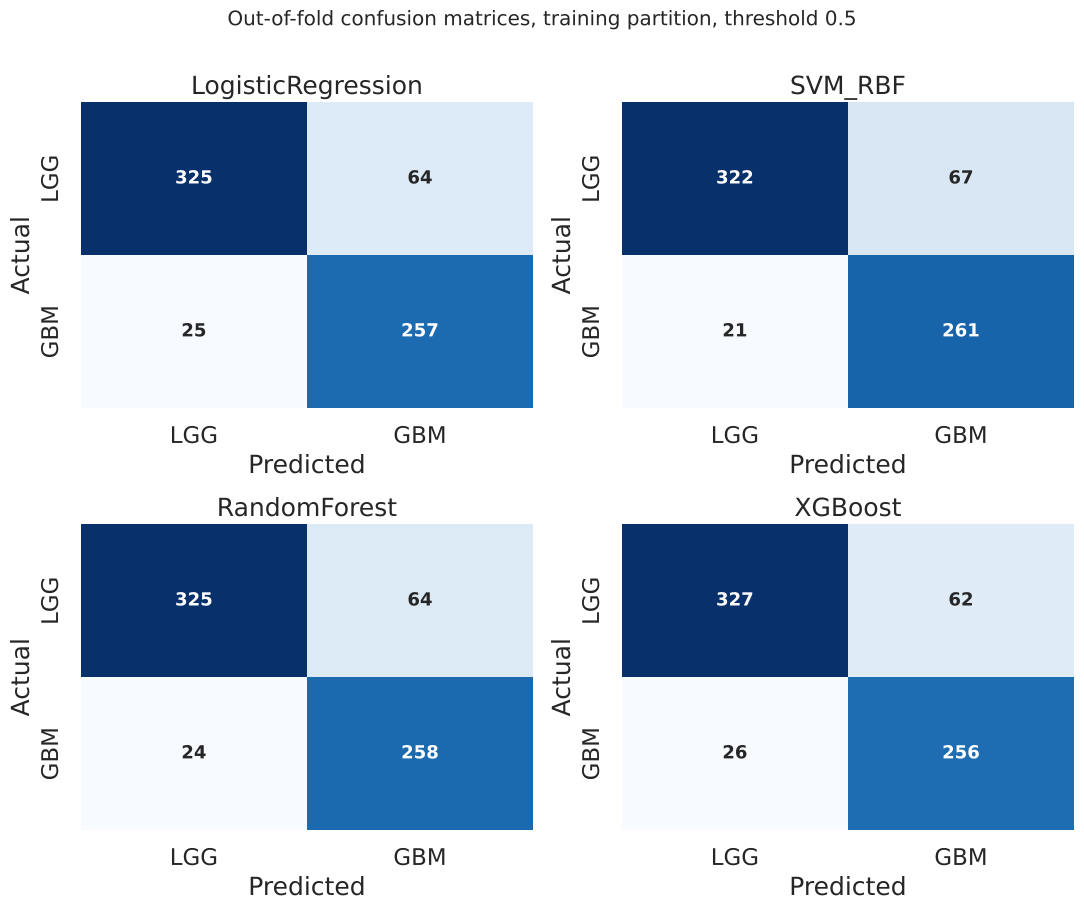

             Model  Threshold  TP  TN  FP  FN  Accuracy  Sensitivity  Specificity
LogisticRegression        0.5 257 325  64  25    0.8674       0.9113       0.8355
           SVM_RBF        0.5 261 322  67  21    0.8689       0.9255       0.8278
      RandomForest        0.5 258 325  64  24    0.8689       0.9149       0.8355
           XGBoost        0.5 256 327  62  26    0.8689       0.9078       0.8406


In [34]:
rows = []
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, f in zip(axes.flat, FAMILIES):
    p = nested[f][0]; oo = ops(y_arr, p, .5)
    rows.append({"Model": f, "Threshold": .5, **{k: oo[k] for k in ["TP", "TN", "FP", "FN"]}, **{k: round(oo[k], 4) for k in ["Accuracy", "Sensitivity", "Specificity"]}})
    sns.heatmap(confusion_matrix(y_arr, (p >= .5).astype(int)), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["LGG", "GBM"], yticklabels=["LGG", "GBM"], annot_kws={"size": 13, "weight": "bold"})
    ax.set(title=f"{f}", xlabel="Predicted", ylabel="Actual")
plt.suptitle("Out-of-fold confusion matrices, training partition, threshold 0.5", y=1.01)
savefig("Figure17_PerModelConfusionMatrices.png")
pd.DataFrame(rows).to_csv(TABLE_DIR / "Table27_PerModelConfusionMatrices.csv", index=False); print(pd.DataFrame(rows).to_string(index=False))

## Section 22 — Decisions log, reproducibility report, asset index, and manuscript number sheet

In [35]:
dec = pd.DataFrame([
    {"Decision": "Cohort", "Value": f"N={N_ANALYSIS} ({N_LGG} LGG / {N_GBM} GBM); no rows removed", "Rule": DUPLICATE_NOTE},
    {"Decision": "Train/test split", "Value": f"{N_TRAIN}/{N_TEST}, stratified, seed {RANDOM_STATE}", "Rule": "Fixed a priori; same partition as an intermediate version of the analysis (disclosed)"},
    {"Decision": "Imbalance strategy", "Value": IMBALANCE_STRATEGY, "Rule": "Highest mean CV AUC (RF, 5x5 CV, training only) among no correction / class weight / SMOTENC; applied to every family"},
    {"Decision": "Primary model", "Value": PRIMARY_MODEL_NAME, "Rule": f"Highest mean outer-fold nested-CV AUC, ties by Brier; pooled-OOF winner = {POOLED_WINNER}"},
    {"Decision": "Calibration", "Value": CALIBRATION_METHOD, "Rule": "Lowest ECE among non-degenerate methods (pile-up <= 10%)"},
    {"Decision": "Threshold", "Value": round(OPTIMAL_THRESHOLD, 3), "Rule": "Youden's J on calibrated out-of-fold probabilities (training only)"},
    {"Decision": "Four-feature panel", "Value": ", ".join(FOUR_FEATURE_PANEL), "Rule": "Majority vote of nested per-fold top-4 selections (training only)"},
    {"Decision": "SHAP", "Value": SHAP_METHOD, "Rule": "Explainer chosen by model family"},
])
dec.to_csv(TABLE_DIR / "Table00_DecisionsLog.csv", index=False); print(dec.to_string(index=False))

import imblearn as _ib
env = {"generated_utc": datetime.now(timezone.utc).isoformat(), "python": platform.python_version(), "platform": platform.platform(),
       "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
       "xgboost": xgboost.__version__, "shap": shap.__version__, "imbalanced-learn": _ib.__version__, "statsmodels": sm.__version__,
       "matplotlib": mpl.__version__, "seaborn": sns.__version__, "random_state": RANDOM_STATE,
       "analysis_file_sha256": DATA_SHA256, "dataframe_content_hash": DF_HASH, "N": N_ANALYSIS, "train_N": N_TRAIN, "test_N": N_TEST, **LOCKS}
env["cache_manifest"] = CACHE_MANIFEST
env["cache_all_recomputed_this_run"] = not any(v["hit"] for v in CACHE_MANIFEST.values())
with open(MODEL_DIR / "cache_manifest.json", "w") as f: json.dump(CACHE_MANIFEST, f, indent=2)
with open(MODEL_DIR / "reproducibility_report.json", "w") as f: json.dump(env, f, indent=2, default=str)
for k in ["python", "scikit-learn", "xgboost", "shap", "imbalanced-learn"]: record(f"Version_{k}", env[k], "reproducibility_report.json")

nums = pd.DataFrame(MANUSCRIPT_NUMBERS); nums.to_csv(OUTPUT_DIR / "ManuscriptNumbers.csv", index=False)
assets = [{"Type": "Table", "File": p.name} for p in sorted(TABLE_DIR.glob("*.csv"))] + [{"Type": "Figure", "File": p.name} for p in sorted(FIG_DIR.glob("*.png"))]
pd.DataFrame(assets).to_csv(OUTPUT_DIR / "AssetIndex.csv", index=False)
print(f"\n{len(nums)} manuscript numbers recorded; {len(assets)} assets indexed.")
print(nums.to_string(index=False))

          Decision                                                   Value                                                                                                                                                                                                                                                                                                    Rule
            Cohort              N=839 (487 LGG / 352 GBM); no rows removed 2 analysis rows are identical on all 24 fields but map to distinct TCGA patients (TCGA-P5-A72W, TCGA-E1-A7Z4; raw ages 35 years 65 days, 35 years 66 days; diagnoses Astrocytoma, anaplastic / Astrocytoma, NOS). The coincidence arises from UCI's 2-decimal age rounding. Both patients are retained.
  Train/test split                            671/168, stratified, seed 42                                                                                                                                                                                        

## Section 23 — Study-design figure (all counts computed above)

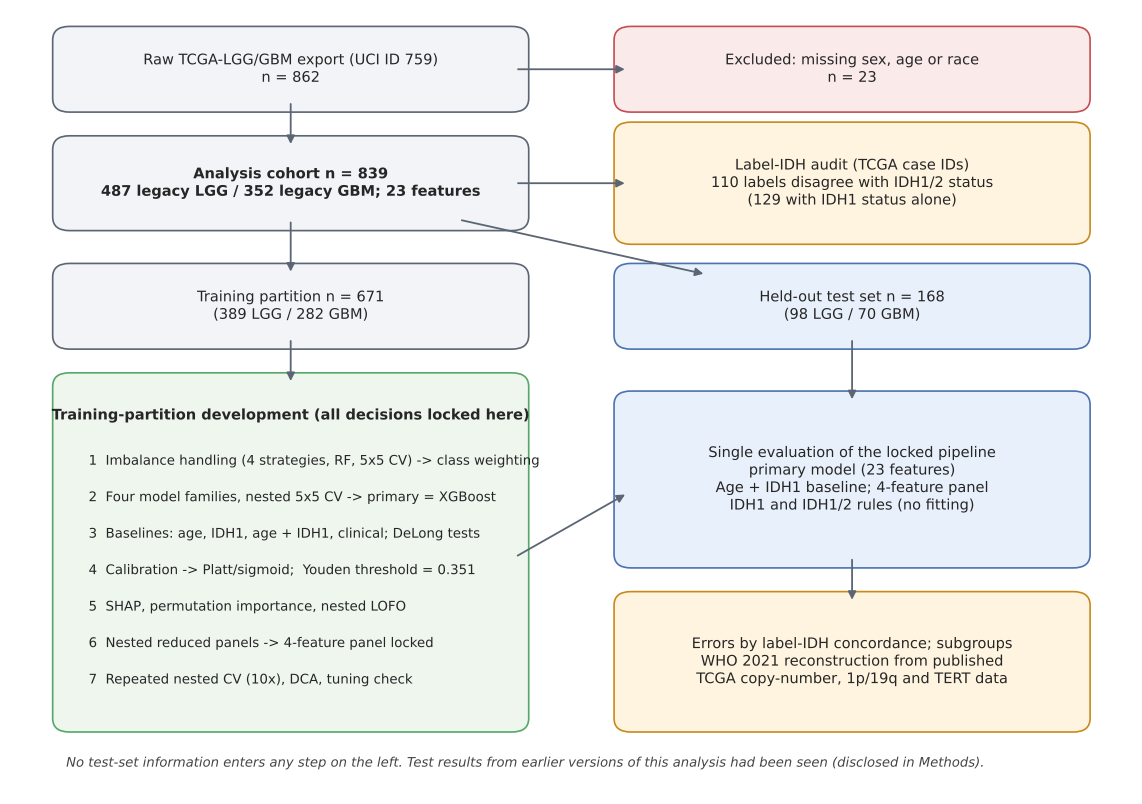

In [36]:
from matplotlib.patches import FancyBboxPatch
def box(ax, x, y, w, h, text, fc="#F2F4F7", ec="#5B6573", fs=10.5, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.012,rounding_size=0.015", fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal")
def arrow(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#5B6573", lw=1.3))
fig, ax = plt.subplots(figsize=(12, 8.2)); ax.set_xlim(0, 1); ax.set_ylim(.14, 1); ax.axis("off")
n_excl = len(raw) - N_ANALYSIS
box(ax, .05, .90, .40, .07, f"Raw TCGA-LGG/GBM export (UCI ID 759)\nn = {len(raw)}")
box(ax, .55, .90, .40, .07, f"Excluded: missing sex, age or race\nn = {n_excl}", fc="#FBEAEA", ec="#C44E52")
arrow(ax, .45, .935, .55, .935)
box(ax, .05, .77, .40, .08, f"Analysis cohort n = {N_ANALYSIS}\n{N_LGG} legacy LGG / {N_GBM} legacy GBM; 23 features", bold=True)
arrow(ax, .25, .90, .25, .85)
box(ax, .55, .755, .40, .11, f"Label-IDH audit (TCGA case IDs)\n{int((((prov.Grade == 1) & idh_mut) | ((prov.Grade == 0) & ~idh_mut)).sum())} labels disagree with IDH1/2 status\n"
    f"({int(prov.IDH1_discordant.sum())} with IDH1 status alone)", fc="#FFF4E0", ec="#C98A1B")
arrow(ax, .45, .81, .55, .81)
box(ax, .05, .64, .40, .07, f"Training partition n = {N_TRAIN}\n({TR_LGG} LGG / {TR_GBM} GBM)")
box(ax, .55, .64, .40, .07, f"Held-out test set n = {N_TEST}\n({TE_LGG} LGG / {TE_GBM} GBM)", fc="#E8F1FB", ec="#4C72B0")
arrow(ax, .25, .77, .25, .71); arrow(ax, .40, .77, .62, .71)
steps = [f"1  Imbalance handling (4 strategies, RF, 5x5 CV) -> {"class weighting" if IMBALANCE_STRATEGY.startswith("Class") else IMBALANCE_STRATEGY}",
         f"2  Four model families, nested 5x5 CV -> primary = {PRIMARY_MODEL_NAME}",
         "3  Baselines: age, IDH1, age + IDH1, clinical; DeLong tests",
         f"4  Calibration -> {CALIBRATION_METHOD.split(' ')[0]};  Youden threshold = {OPTIMAL_THRESHOLD:.3f}",
         "5  SHAP, permutation importance, nested LOFO",
         f"6  Nested reduced panels -> 4-feature panel locked",
         "7  Repeated nested CV (10x), DCA, tuning check"]
box(ax, .05, .22, .40, .37, "", fc="#EEF6EE", ec="#55A868")
ax.text(.25, .555, "Training-partition development (all decisions locked here)", ha="center", va="center", fontsize=10.5, fontweight="bold")
for k, st in enumerate(steps): ax.text(.07, .505 - k * .04, st, ha="left", va="center", fontsize=9.6)
arrow(ax, .25, .64, .25, .59)
box(ax, .55, .40, .40, .17, "Single evaluation of the locked pipeline\nprimary model (23 features)\nAge + IDH1 baseline; 4-feature panel\nIDH1 and IDH1/2 rules (no fitting)", fc="#E8F1FB", ec="#4C72B0")
arrow(ax, .75, .64, .75, .57); arrow(ax, .45, .40, .55, .47)
box(ax, .55, .22, .40, .13, "Errors by label-IDH concordance; subgroups\nWHO 2021 reconstruction from published\nTCGA copy-number, 1p/19q and TERT data", fc="#FFF4E0", ec="#C98A1B")
arrow(ax, .75, .40, .75, .35)
ax.text(.05, .17, "No test-set information enters any step on the left. Test results from earlier versions of this analysis had been seen (disclosed in Methods).",
        fontsize=9.5, style="italic", color="#444")
savefig("Figure00_StudyDesign.png")